In [1]:
# ============================================================
#  CELL 1 — IMPORT LIBRARY
#  Tahap   : Persiapan Awal
#  Fungsi  : Mengimpor semua library yang dibutuhkan
#            dalam seluruh pipeline 01_tabular_main.ipynb
# ============================================================

# ----------------------------------------------------------
# 1A. Manipulasi Data & Numerik
# ----------------------------------------------------------
import numpy as np                  # operasi array dan matriks
import pandas as pd                 # manipulasi dataframe/tabel

# ----------------------------------------------------------
# 1B. Visualisasi
# ----------------------------------------------------------
import matplotlib.pyplot as plt     # plot dasar (grafik, histogram)
import seaborn as sns               # plot statistik (heatmap, boxplot)

# ----------------------------------------------------------
# 1C. Preprocessing
# ----------------------------------------------------------
from sklearn.preprocessing import (
    LabelEncoder,                   # encoding kolom kategorikal ordinal
    StandardScaler,                 # standarisasi (mean=0, std=1) → untuk MLP
    MinMaxScaler                    # normalisasi (skala 0-1) → alternatif
)
from sklearn.model_selection import (
    train_test_split,               # split data train dan test
    GridSearchCV,                   # hyperparameter tuning exhaustive
    RandomizedSearchCV,             # hyperparameter tuning random (lebih cepat)
    StratifiedKFold,                # K-Fold dengan proporsi label terjaga
    cross_val_score                 # evaluasi dengan cross validation
)

# ----------------------------------------------------------
# 1D. Handling Class Imbalance
# ----------------------------------------------------------
from imblearn.over_sampling import SMOTE   # synthetic minority oversampling

# ----------------------------------------------------------
# 1E. Model Machine Learning
# ----------------------------------------------------------
from sklearn.ensemble import GradientBoostingClassifier  # model Gradient Boosting
from xgboost import XGBClassifier                        # model XGBoost
from sklearn.neural_network import MLPClassifier         # model MLP

# ----------------------------------------------------------
# 1F. Metrik Evaluasi
# ----------------------------------------------------------
from sklearn.metrics import (
    accuracy_score,                 # akurasi keseluruhan
    precision_score,                # presisi (seberapa tepat prediksi positif)
    recall_score,                   # recall / sensitivity (seberapa banyak positif tertangkap)
    f1_score,                       # harmonic mean precision & recall
    roc_auc_score,                  # area under ROC curve
    roc_curve,                      # titik-titik kurva ROC
    confusion_matrix,               # confusion matrix
    classification_report           # laporan lengkap semua metrik
)

# ----------------------------------------------------------
# 1G. Konfigurasi Tampilan
# ----------------------------------------------------------
pd.set_option('display.max_columns', None)   # tampilkan semua kolom dataframe
pd.set_option('display.max_rows', 50)        # tampilkan maksimal 50 baris
sns.set_theme(style="whitegrid")             # tema plot seaborn
plt.rcParams['figure.figsize'] = (10, 6)    # ukuran default semua plot

# ----------------------------------------------------------
# 1H. Konfirmasi Versi Library (opsional tapi disarankan)
# ----------------------------------------------------------
print("=" * 45)
print("   LIBRARY BERHASIL DIIMPORT")
print("=" * 45)
print(f"  numpy       : {np.__version__}")
print(f"  pandas      : {pd.__version__}")
import sklearn; print(f"  scikit-learn: {sklearn.__version__}")
import xgboost;  print(f"  xgboost     : {xgboost.__version__}")
import imblearn; print(f"  imbalanced  : {imblearn.__version__}")
print("=" * 45)
print("  Siap lanjut ke Cell 2 → Load Dataset")
print("=" * 45)

   LIBRARY BERHASIL DIIMPORT
  numpy       : 2.3.1
  pandas      : 2.3.1
  scikit-learn: 1.7.1
  xgboost     : 3.0.1
  imbalanced  : 0.14.1
  Siap lanjut ke Cell 2 → Load Dataset


In [2]:
# ============================================================
#  CELL 2 — LOAD DATASET
#  Tahap   : Pengambilan & Inspeksi Awal Data
#  Fungsi  : Membaca CSV, inspeksi struktur lengkap, preview data
# ============================================================

# ----------------------------------------------------------
# SECTION 1 & 2 — Dimensi + Struktur Kolom (DIGABUNG)
#                 Shape · Non-Null Count · Dtype · Memory
# ----------------------------------------------------------
data = pd.read_csv('clinically_isolated_syndrome_to_multiple_sclerosis.csv')

print("=" * 55)
print("  INFORMASI & STRUKTUR DATASET")
print("=" * 55)
print(f"  Shape  : {data.shape[0]} baris × {data.shape[1]} kolom")
print("-" * 55)
data.info(memory_usage='deep')
print("=" * 55)

# ----------------------------------------------------------
# SECTION 3 — Preview Data (Head · Tail · Sample Acak)
# ----------------------------------------------------------
print("\n  HEAD — 5 Baris Pertama:")
display(data.head())

print("\n  TAIL — 5 Baris Terakhir:")
display(data.tail())

print("\n  SAMPLE ACAK — 5 Baris Random:")
display(data.sample(5, random_state=42))

# ----------------------------------------------------------
# SECTION 4 — Distribusi Kolom Target
# ----------------------------------------------------------
target_col = 'group'

print("\n" + "=" * 55)
print("  DISTRIBUSI KOLOM TARGET")
print("=" * 55)
print(f"  Nama kolom target : '{target_col}'")
print(f"  Nilai unik        : {data[target_col].unique()}")
print(f"\n  Jumlah per kelas  :")
print(data[target_col].value_counts().to_string())
print(f"\n  Proporsi (%)      :")
print((data[target_col].value_counts(normalize=True) * 100).round(2).to_string())
print("=" * 55)
print("  ✅ Cell 2 selesai — Siap lanjut ke Cell 3 (EDA)")
print("=" * 55)

  INFORMASI & STRUKTUR DATASET
  Shape  : 273 baris × 20 kolom
-------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 273 entries, 0 to 272
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               273 non-null    int64  
 1   Gender                   273 non-null    int64  
 2   Age                      273 non-null    int64  
 3   Schooling                272 non-null    float64
 4   Breastfeeding            273 non-null    int64  
 5   Varicella                273 non-null    int64  
 6   Initial_Symptom          272 non-null    float64
 7   Mono_or_Polysymptomatic  273 non-null    int64  
 8   Oligoclonal_Bands        273 non-null    int64  
 9   LLSSEP                   273 non-null    int64  
 10  ULSSEP                   273 non-null    int64  
 11  VEP                      273 non-null    int64  
 12  BAEP           

,Unnamed: 0,Gender,Age,Schooling,Breastfeeding,Varicella,Initial_Symptom,Mono_or_Polysymptomatic,Oligoclonal_Bands,LLSSEP,ULSSEP,VEP,BAEP,Periventricular_MRI,Cortical_MRI,Infratentorial_MRI,Spinal_Cord_MRI,Initial_EDSS,Final_EDSS,group
0,0,1,34,20.0,1,1,2.0,1,0,1,1,0,0,0,1,0,1,1.0,1.0,1
1,1,1,61,25.0,3,2,10.0,2,1,1,0,1,0,0,0,0,1,2.0,2.0,1
2,2,1,22,20.0,3,1,3.0,1,1,0,0,0,0,0,1,0,0,1.0,1.0,1
3,3,2,41,15.0,1,1,7.0,2,1,0,1,1,0,1,1,0,0,1.0,1.0,1
4,4,2,34,20.0,2,1,6.0,2,0,1,0,0,0,1,0,0,0,1.0,1.0,1



  TAIL — 5 Baris Terakhir:


,Unnamed: 0,Gender,Age,Schooling,Breastfeeding,Varicella,Initial_Symptom,Mono_or_Polysymptomatic,Oligoclonal_Bands,LLSSEP,ULSSEP,VEP,BAEP,Periventricular_MRI,Cortical_MRI,Infratentorial_MRI,Spinal_Cord_MRI,Initial_EDSS,Final_EDSS,group
268,268,2,31,8.0,3,1,9.0,2,0,0,0,0,0,0,0,0,0,NaN,NaN,2
269,269,1,21,15.0,3,3,5.0,2,1,0,0,0,0,0,0,0,1,NaN,NaN,2
270,270,2,19,12.0,3,3,13.0,2,0,1,1,1,0,0,0,0,1,NaN,NaN,2
271,271,2,32,15.0,3,3,15.0,2,1,1,1,1,0,1,1,1,0,NaN,NaN,2
272,272,2,77,6.0,3,3,2.0,1,0,0,1,0,0,0,0,0,0,NaN,NaN,2



  SAMPLE ACAK — 5 Baris Random:


,Unnamed: 0,Gender,Age,Schooling,Breastfeeding,Varicella,Initial_Symptom,Mono_or_Polysymptomatic,Oligoclonal_Bands,LLSSEP,ULSSEP,VEP,BAEP,Periventricular_MRI,Cortical_MRI,Infratentorial_MRI,Spinal_Cord_MRI,Initial_EDSS,Final_EDSS,group
30,30,2,25,15.0,2,2,8.0,2,0,1,1,1,0,1,1,0,1,1.0,1.0,1
117,117,2,52,15.0,1,1,8.0,2,1,0,1,0,0,0,0,0,1,1.0,1.0,1
79,79,1,34,12.0,2,2,13.0,2,1,1,1,1,0,1,1,1,1,1.0,1.0,1
212,212,1,37,9.0,3,3,12.0,2,1,1,1,1,1,1,1,1,1,NaN,NaN,2
213,213,1,55,12.0,3,3,10.0,2,0,1,1,0,0,1,1,0,1,NaN,NaN,2



  DISTRIBUSI KOLOM TARGET
  Nama kolom target : 'group'
  Nilai unik        : [1 2]

  Jumlah per kelas  :
group
2    148
1    125

  Proporsi (%)      :
group
2    54.21
1    45.79
  ✅ Cell 2 selesai — Siap lanjut ke Cell 3 (EDA)


In [3]:
data =data.drop('Unnamed: 0',axis =1)

In [4]:
print("Semua fitur dan class di dataset:")
print(data.columns.tolist())

print("\nClass")
print(data.columns[-1])

Semua fitur dan class di dataset:
['Gender', 'Age', 'Schooling', 'Breastfeeding', 'Varicella', 'Initial_Symptom', 'Mono_or_Polysymptomatic', 'Oligoclonal_Bands', 'LLSSEP', 'ULSSEP', 'VEP', 'BAEP', 'Periventricular_MRI', 'Cortical_MRI', 'Infratentorial_MRI', 'Spinal_Cord_MRI', 'Initial_EDSS', 'Final_EDSS', 'group']

Class
group


  SECTION 1 — STATISTIK DESKRIPTIF


,count,mean,std,min,25%,50%,75%,max
Gender,273.00,1.62,0.49,1.00,1.00,2.00,2.00,2.00
Age,273.00,34.06,11.11,15.00,25.00,33.00,40.00,77.00
Schooling,272.00,15.18,4.24,0.00,12.00,15.00,20.00,25.00
Breastfeeding,273.00,1.83,0.87,1.00,1.00,2.00,3.00,3.00
Varicella,273.00,1.71,0.73,1.00,1.00,2.00,2.00,3.00
Initial_Symptom,272.00,6.43,4.22,1.00,3.00,6.00,9.00,15.00
Mono_or_Polysymptomatic,273.00,1.73,0.49,1.00,1.00,2.00,2.00,3.00
Oligoclonal_Bands,273.00,0.36,0.56,0.00,0.00,0.00,1.00,2.00
LLSSEP,273.00,0.42,0.50,0.00,0.00,0.00,1.00,1.00
ULSSEP,273.00,0.37,0.48,0.00,0.00,0.00,1.00,1.00



  SECTION 2 — MISSING VALUES
  ⚠️  Ditemukan 4 kolom dengan missing values:



,Jumlah Missing,Persentase (%)
Initial_EDSS,148,54.21
Final_EDSS,148,54.21
Schooling,1,0.37
Initial_Symptom,1,0.37



  SECTION 3 — DISTRIBUSI KOLOM TARGET 'group'


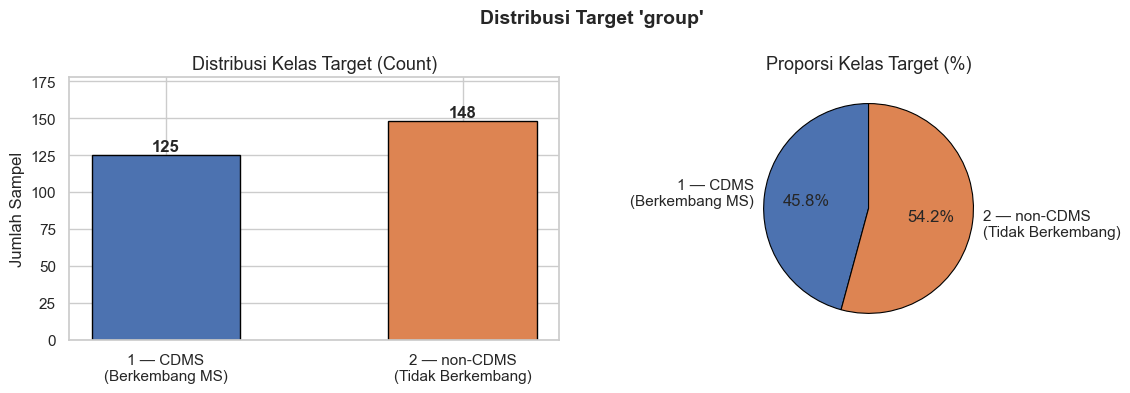


  SECTION 4 — DISTRIBUSI SEMUA FITUR (HISTOGRAM)


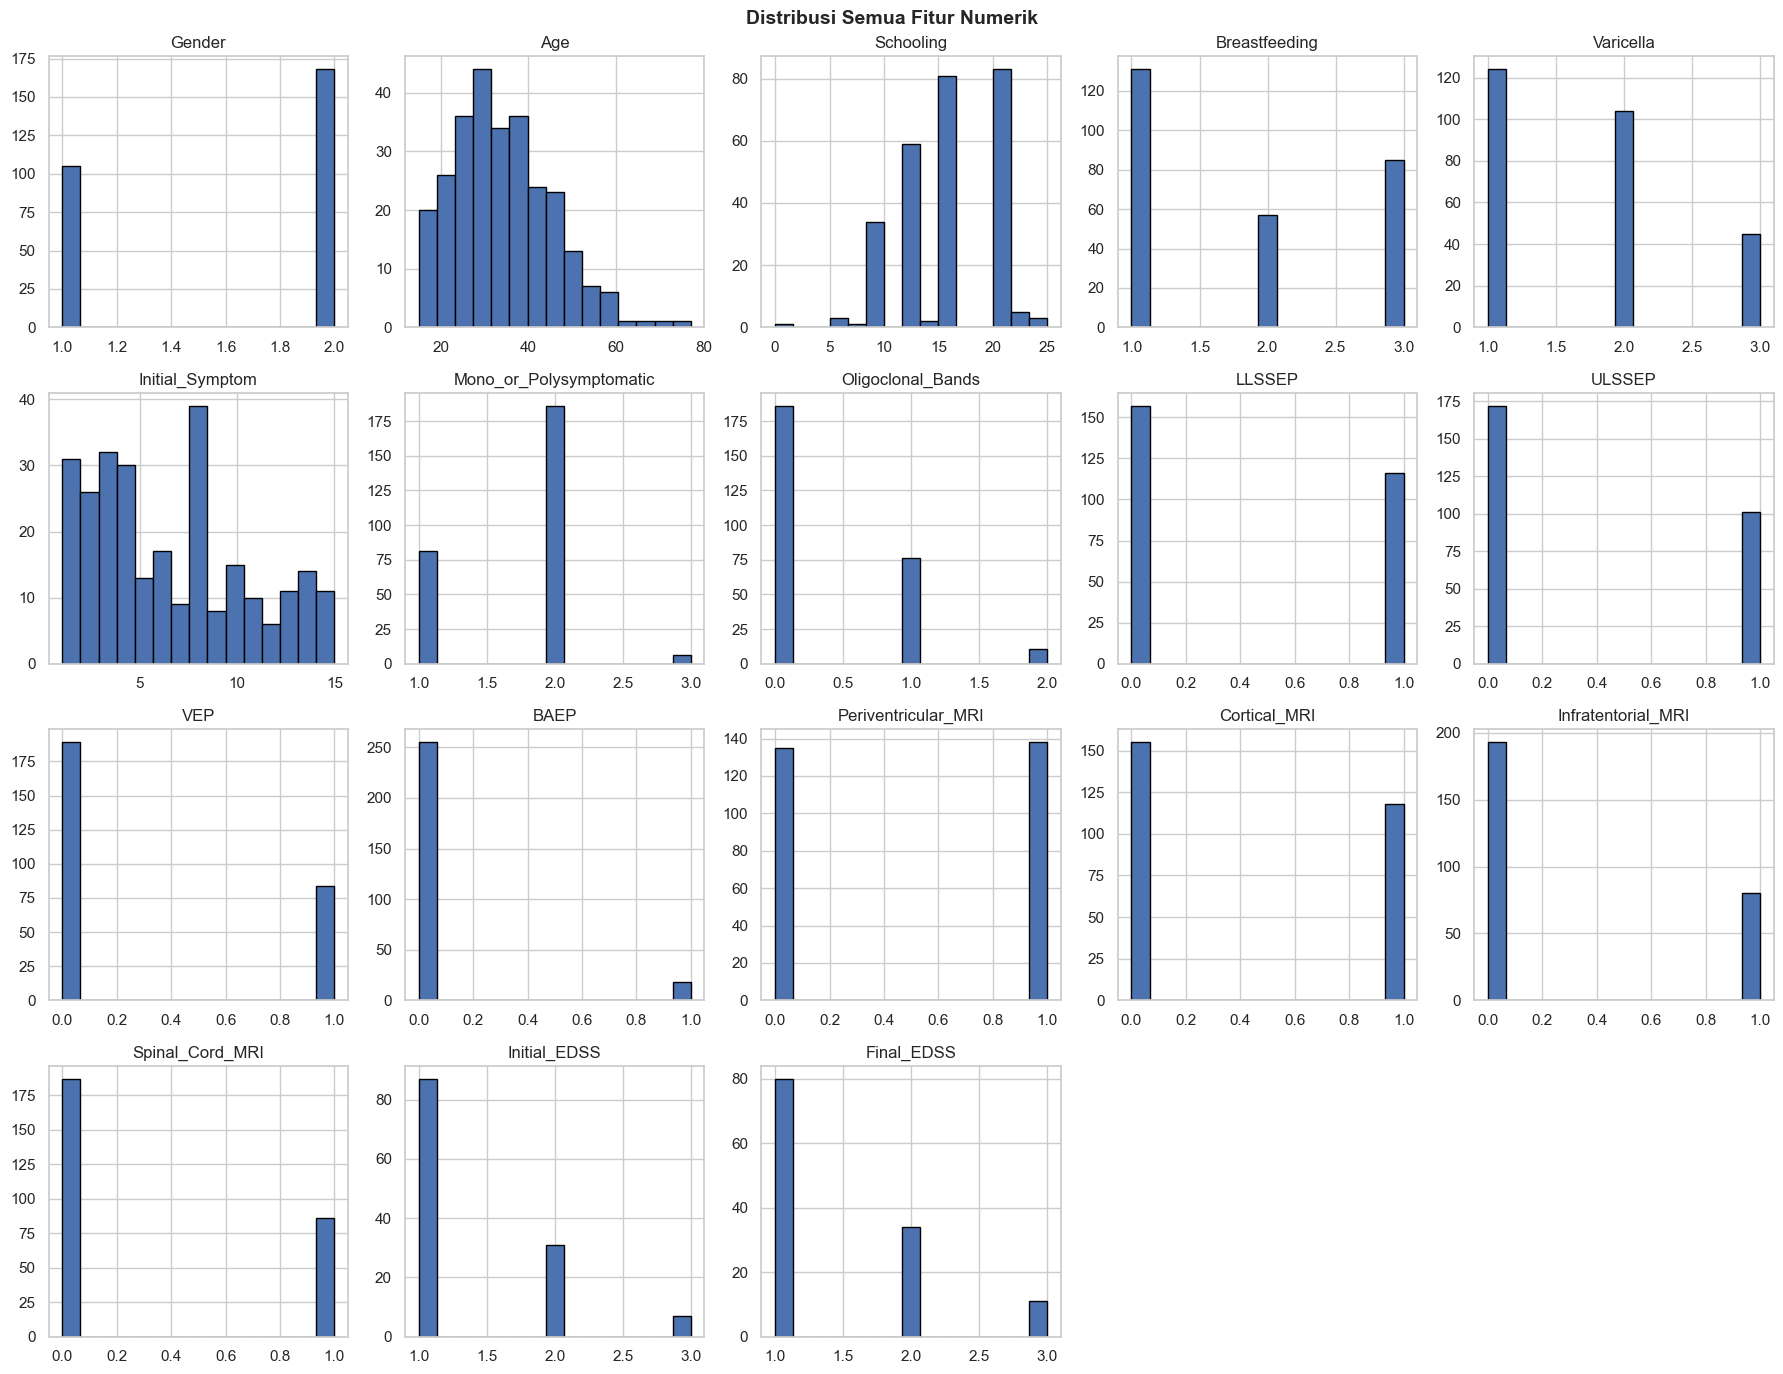


  SECTION 5 — BOXPLOT FITUR vs TARGET (OUTLIER)


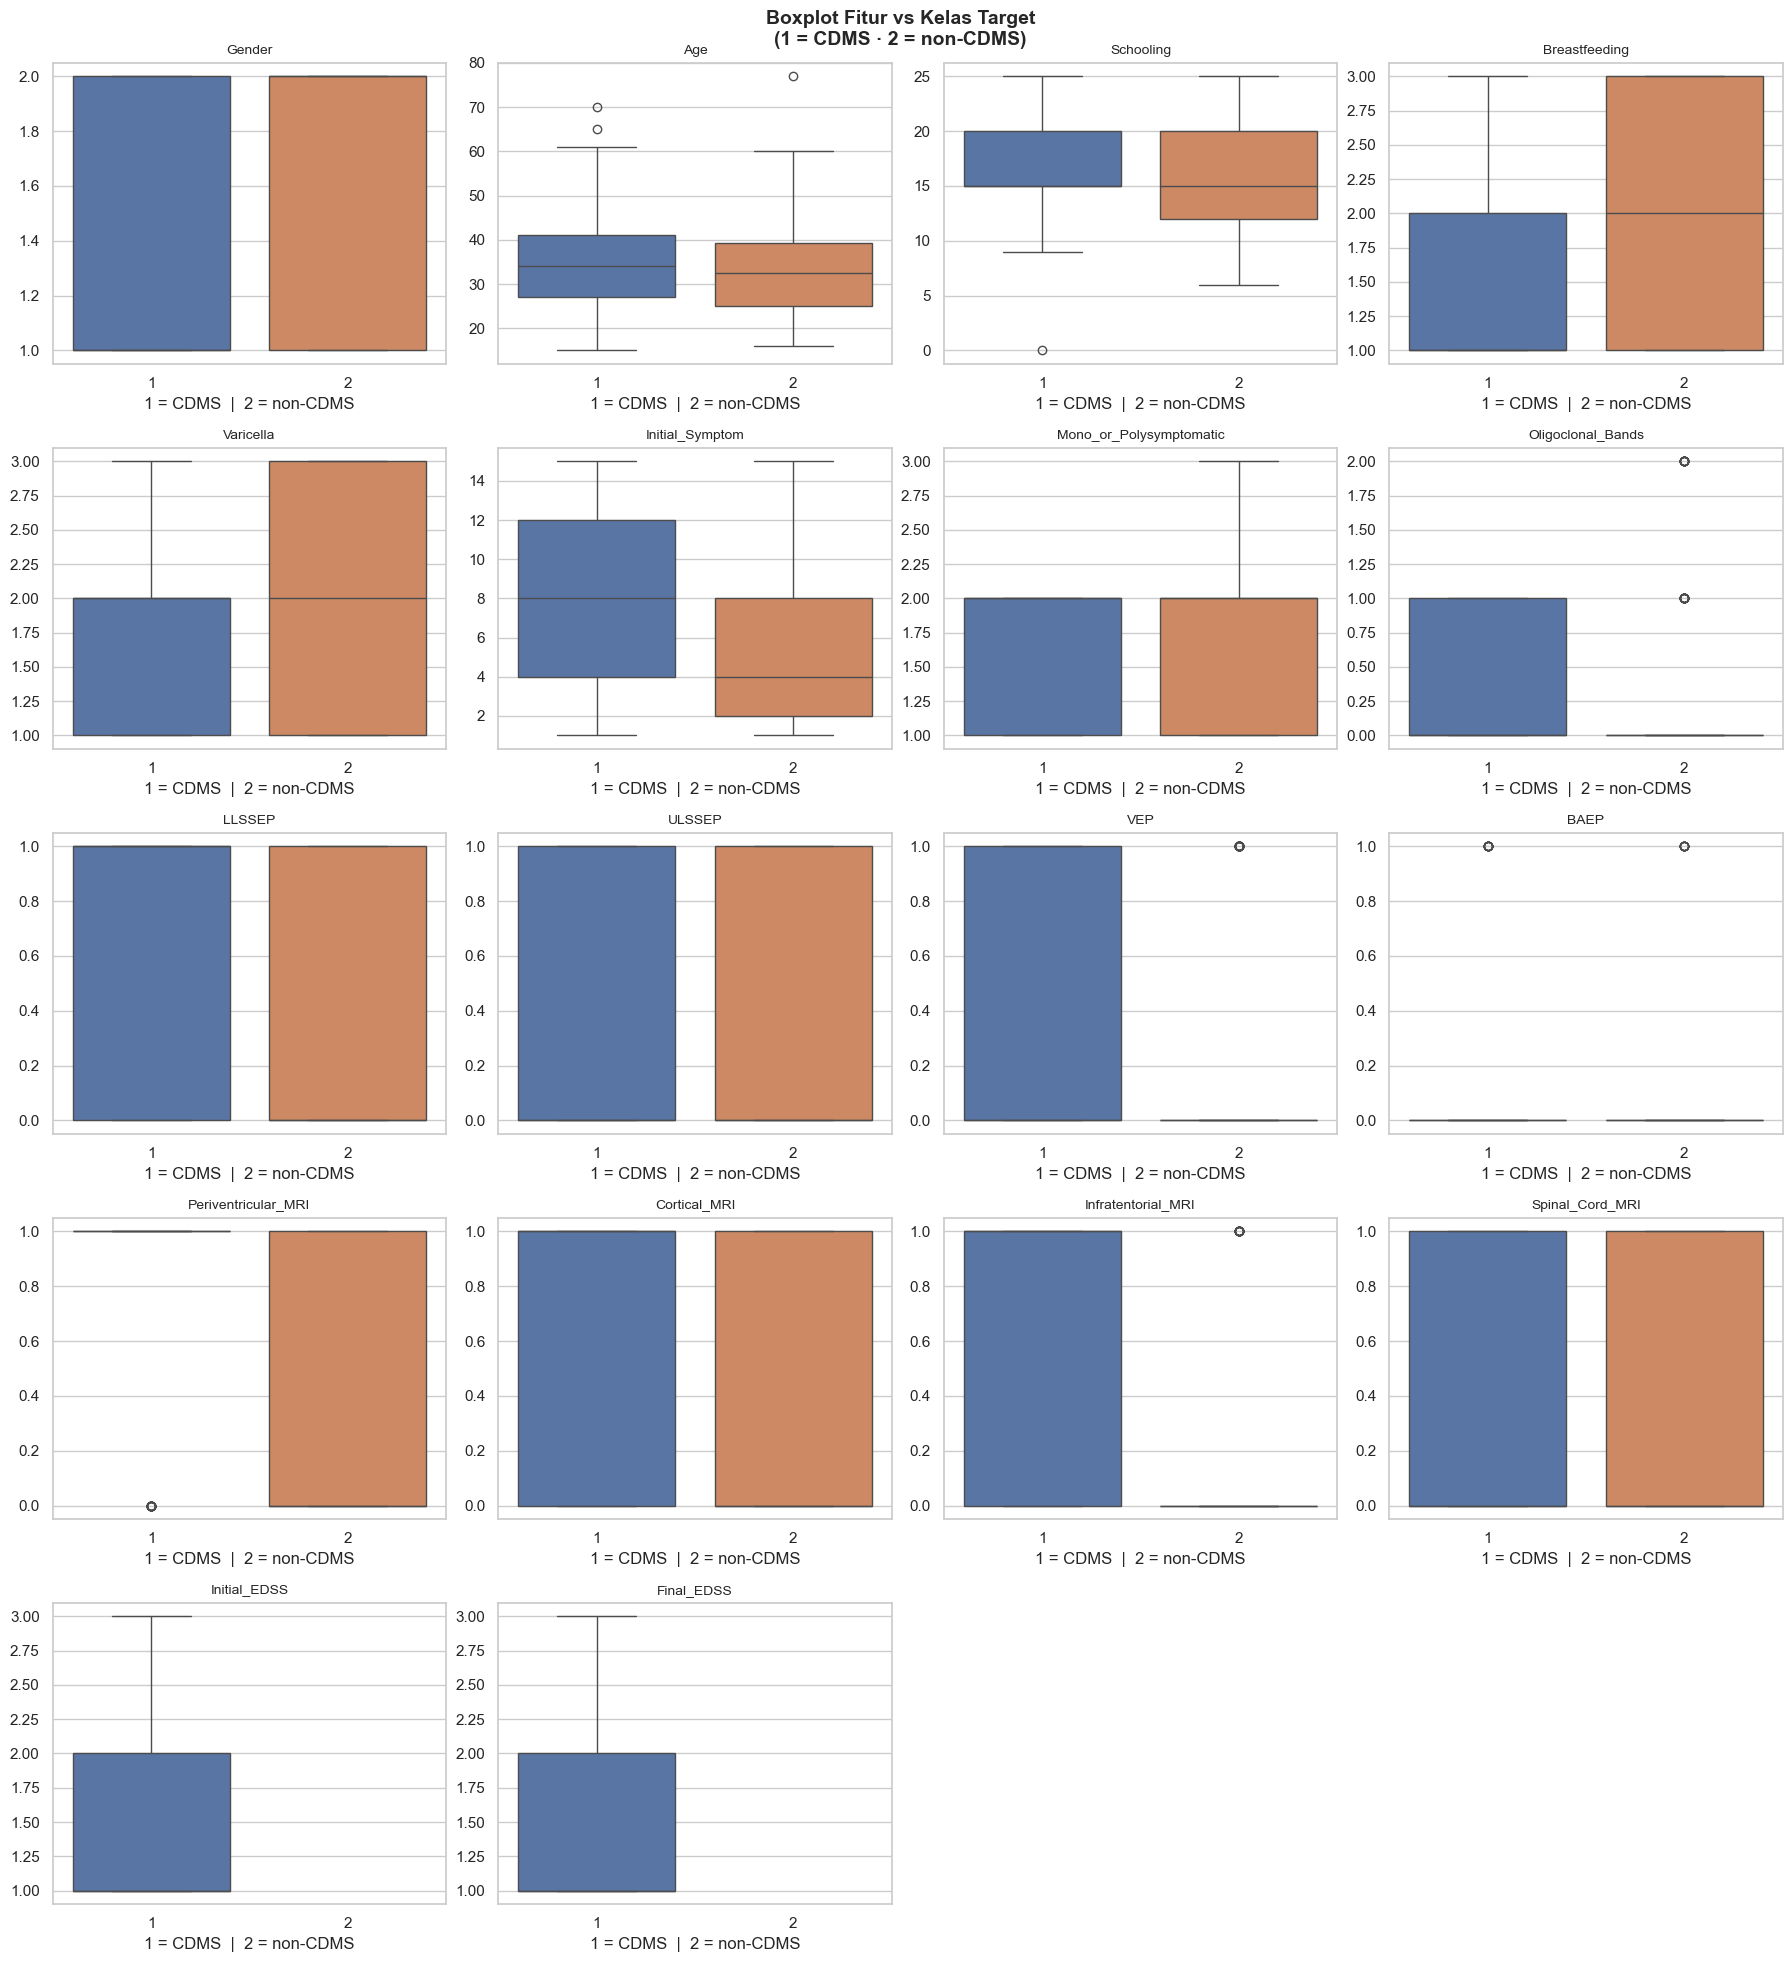


  SECTION 6 — HEATMAP KORELASI


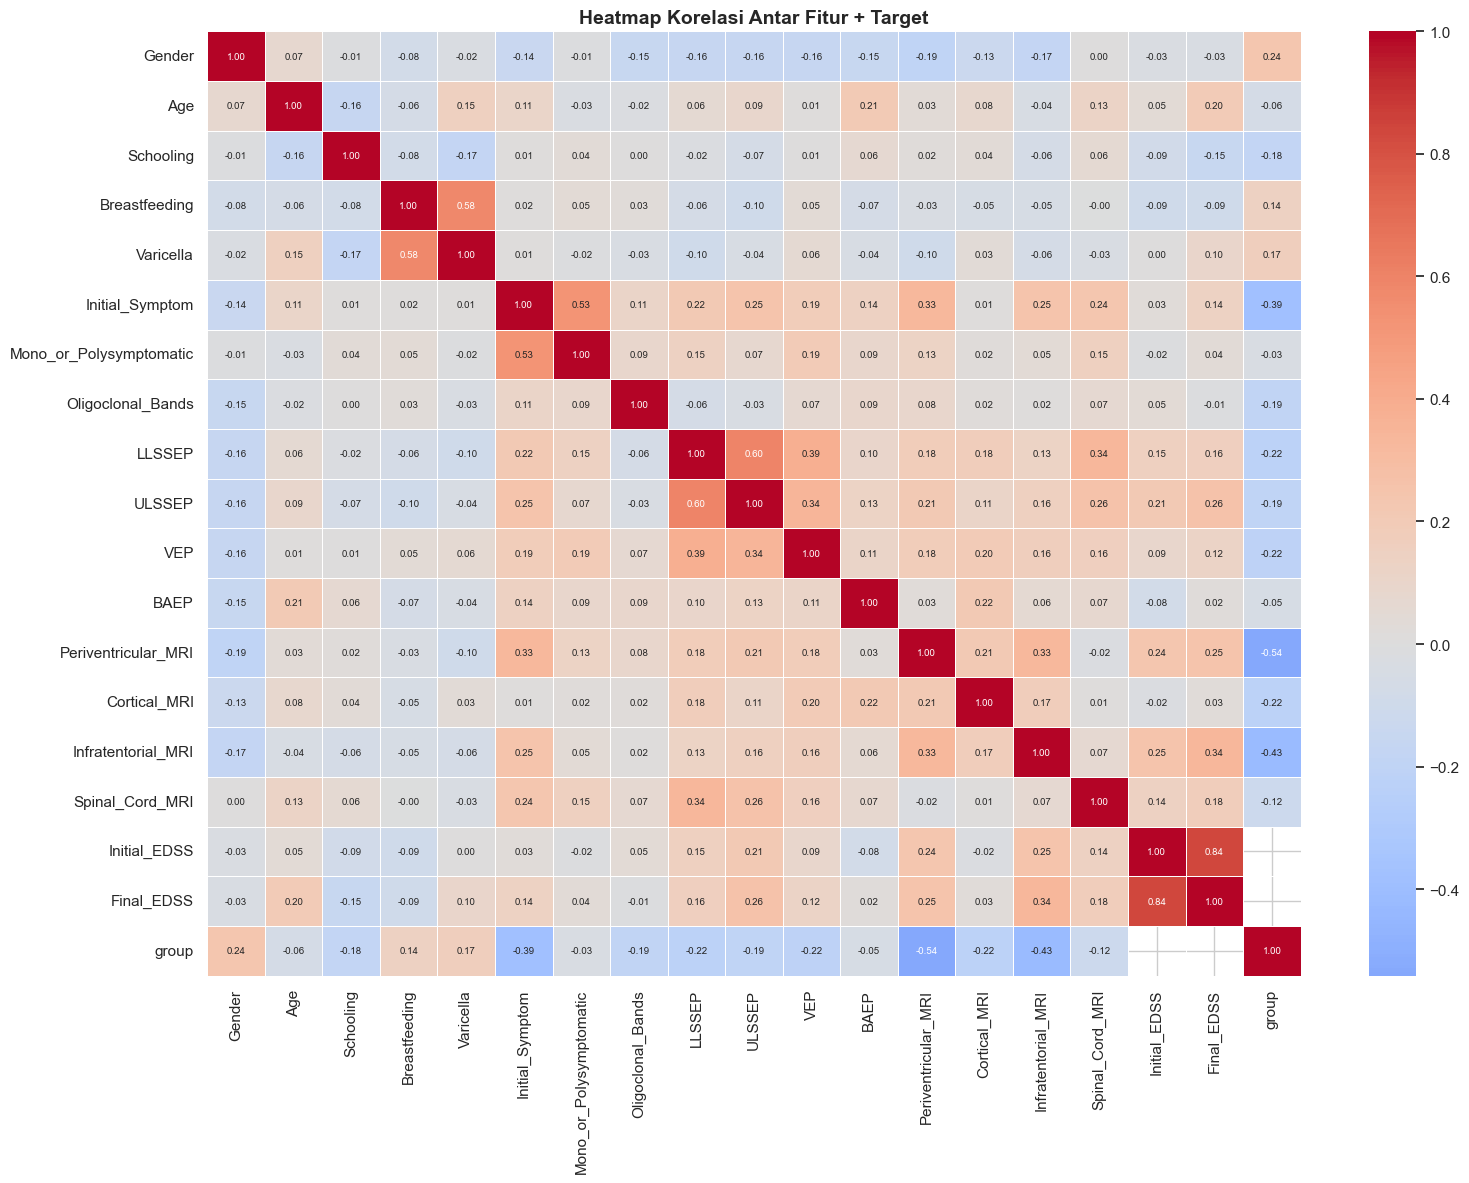


  TOP FITUR BERKORELASI DENGAN TARGET 'group':
---------------------------------------------
  Periventricular_MRI            0.5413
  Infratentorial_MRI             0.4260
  Initial_Symptom                0.3890
  Gender                         0.2406
  Cortical_MRI                   0.2222
  LLSSEP                         0.2214
  VEP                            0.2157
  ULSSEP                         0.1942
  Oligoclonal_Bands              0.1864
  Schooling                      0.1845

  ✅ Cell 3 selesai — Siap lanjut ke Cell 4 (Missing Values)


In [5]:
# ============================================================
#  CELL 3 — EXPLORATORY DATA ANALYSIS (EDA)
#  Tahap   : Pemahaman Data
#  Fungsi  : Distribusi, missing values, outlier, korelasi
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Statistik Deskriptif
#             Ringkasan mean, std, min, max, quartile
#             untuk semua fitur numerik
# ----------------------------------------------------------
print("=" * 60)
print("  SECTION 1 — STATISTIK DESKRIPTIF")
print("=" * 60)
display(data.describe().T.style.format("{:.2f}"))
# .T = transpose supaya kolom jadi baris, lebih mudah dibaca
# 273 baris, jika count < 273 berarti ada missing values

# ----------------------------------------------------------
# SECTION 2 — Deteksi Missing Values
#             Hitung jumlah dan persentase nilai kosong
#             per kolom — dasar pengambilan keputusan Cell 4
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 2 — MISSING VALUES")
print("=" * 60)

missing = pd.DataFrame({
    'Jumlah Missing' : data.isnull().sum(),
    'Persentase (%)' : (data.isnull().sum() / len(data) * 100).round(2)
})
missing = missing[missing['Jumlah Missing'] > 0].sort_values(
    'Persentase (%)', ascending=False
)

if missing.empty:
    print("  ✅ Tidak ada missing values di dataset ini")
else:
    print(f"  ⚠️  Ditemukan {len(missing)} kolom dengan missing values:\n")
    display(missing)

# ----------------------------------------------------------
# SECTION 3 — Distribusi Kolom Target
#             Visualisasi jumlah sampel per kelas (1 vs 2)
#             Deteksi awal class imbalance
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 3 — DISTRIBUSI KOLOM TARGET 'group'")
print("=" * 60)

target_col = 'group'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
urutan_kelas = [1, 2]
jumlah_kelas = [( data['group'] == k).sum() for k in urutan_kelas]
label_kelas  = ['1 — CDMS\n(Berkembang MS)', '2 — non-CDMS\n(Tidak Berkembang)']
warna_kelas  = ['#4C72B0', '#DD8452']

axes[0].bar(label_kelas, jumlah_kelas,
            color=warna_kelas, edgecolor='black', width=0.5)
axes[0].set_title('Distribusi Kelas Target (Count)', fontsize=13)
axes[0].set_ylabel('Jumlah Sampel')
axes[0].set_ylim(0, max(jumlah_kelas) * 1.2)

for i, (val, label) in enumerate(zip(jumlah_kelas, label_kelas)):
    axes[0].text(i, val + 1, str(val),
                 ha='center', va='bottom',
                 fontsize=12, fontweight='bold')

# Pie chart
axes[1].pie(
    jumlah_kelas,
    labels=label_kelas,
    autopct='%1.1f%%',
    colors=warna_kelas,
    startangle=90,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)
axes[1].set_title('Proporsi Kelas Target (%)', fontsize=13)
axes[1].set_ylabel('')

plt.suptitle("Distribusi Target 'group'", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 4 — Distribusi Semua Fitur (Histogram)
#             Melihat sebaran data tiap fitur
#             Deteksi skewness dan outlier awal
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 4 — DISTRIBUSI SEMUA FITUR (HISTOGRAM)")
print("=" * 60)

fitur_cols = [col for col in data.columns if col != target_col]

data[fitur_cols].hist(
    bins=15,
    figsize=(18, 14),
    color='#4C72B0',
    edgecolor='black',
    layout=(4, 5)          # sesuaikan dengan 19 fitur (4 baris × 5 kolom)
)
plt.suptitle('Distribusi Semua Fitur Numerik', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 5 — BOXPLOT FITUR vs TARGET (DETEKSI OUTLIER)
#             Dibedakan berdasarkan kelas target
#             1 = CDMS  (CIS berkembang menjadi MS)
#             2 = non-CDMS (CIS tidak berkembang menjadi MS)
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 5 — BOXPLOT FITUR vs TARGET (OUTLIER)")
print("=" * 60)

n_cols = 4
n_rows = -(-len(fitur_cols) // n_cols)   # ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(fitur_cols):
    sns.boxplot(
        data=data,
        x=target_col,
        y=col,
        hue=target_col,        # ← PERBAIKAN: tambahkan hue=target_col
        palette={1: '#4C72B0', 2: '#DD8452'},   # ← mapping eksplisit ke nilai 1 dan 2
        legend=False,          # ← sembunyikan legend karena sudah ada label x
        ax=axes[i]
    )
    axes[i].set_title(f'{col}', fontsize=10)
    axes[i].set_xlabel('1 = CDMS  |  2 = non-CDMS')
    axes[i].set_ylabel('')

# Sembunyikan subplot kosong jika fitur tidak genap
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    'Boxplot Fitur vs Kelas Target\n(1 = CDMS · 2 = non-CDMS)',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 6 — Heatmap Korelasi
#             Melihat hubungan antar fitur dan terhadap target
#             Fitur dengan korelasi tinggi ke target = informatif
#             Fitur dengan korelasi tinggi sesama = multikolinearitas
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 6 — HEATMAP KORELASI")
print("=" * 60)

plt.figure(figsize=(16, 12))
corr_matrix = data.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    annot_kws={'size': 7}
)
plt.title('Heatmap Korelasi Antar Fitur + Target', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top 10 fitur paling berkorelasi dengan target
print("\n  TOP FITUR BERKORELASI DENGAN TARGET 'group':")
print("-" * 45)
top_corr = corr_matrix[target_col].drop(target_col)\
           .abs().sort_values(ascending=False).head(10)
for fitur, nilai in top_corr.items():
    print(f"  {fitur:<30} {nilai:.4f}")

print("\n" + "=" * 60)
print("  ✅ Cell 3 selesai — Siap lanjut ke Cell 4 (Missing Values)")
print("=" * 60)

In [6]:
# Konfirmasi MNAR pada Initial_EDSS dan Final_EDSS
print("Missing values per class:\n")
print(data.groupby('group')[['Initial_EDSS', 'Final_EDSS']]\
      .apply(lambda x: x.isnull().sum()))

print("\nJumlah sampel per class:")
print(data['group'].value_counts())

Missing values per class:

       Initial_EDSS  Final_EDSS
group                          
1                 0           0
2               148         148

Jumlah sampel per class:
group
2    148
1    125
Name: count, dtype: int64


In [7]:
# ============================================================
#  CELL 4 — HANDLING MISSING VALUES
#  Tahap   : Preprocessing — Pembersihan Data
#  Strategi:
#    - Initial_EDSS  → DROP (MNAR + data leakage)
#    - Final_EDSS    → DROP (MNAR + data leakage)
#    - Schooling     → Imputasi Median (0.37%, missing acak)
#    - Initial_Symptom → Imputasi Median (0.37%, missing acak)
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Kondisi Awal Sebelum Penanganan
#             Dokumentasi jumlah missing sebelum diproses
#             sebagai perbandingan sebelum-sesudah
# ----------------------------------------------------------
print("=" * 60)
print("  SECTION 1 — KONDISI MISSING VALUES SEBELUM PENANGANAN")
print("=" * 60)

missing_before = pd.DataFrame({
    'Jumlah Missing' : data.isnull().sum(),
    'Persentase (%)' : (data.isnull().sum() / len(data) * 100).round(2)
})
missing_before = missing_before[missing_before['Jumlah Missing'] > 0]
display(missing_before)
print(f"\n  Shape awal dataset : {data.shape}")

# ----------------------------------------------------------
# SECTION 2 — DROP Kolom EDSS (Data Leakage — MNAR)
#             Initial_EDSS dan Final_EDSS dieliminasi karena
#             pola missing-nya berkorelasi langsung dengan target
#             → mempertahankan kedua kolom ini menyebabkan
#               model belajar dari keberadaan nilai, bukan
#               dari fitur klinis yang sesungguhnya (overfitting)
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 2 — DROP KOLOM EDSS (MNAR + DATA LEAKAGE)")
print("=" * 60)

kolom_drop = ['Initial_EDSS', 'Final_EDSS']
data = data.drop(columns=kolom_drop)

print(f"  Kolom dieliminasi  : {kolom_drop}")
print(f"  Alasan             : MNAR — missing values terkonsentrasi")
print(f"                       eksklusif pada kelas 2 (non-CDMS)")
print(f"                       → berpotensi menyebabkan data leakage")
print(f"  Shape setelah drop : {data.shape}")

# ----------------------------------------------------------
# SECTION 3 — Imputasi Median untuk Schooling & Initial_Symptom
#             Median dipilih karena:
#             1. Lebih robust terhadap outlier dibanding mean
#             2. Distribusi fitur klinis cenderung tidak normal
#             3. Jumlah missing sangat sedikit (≈1 baris, 0.37%)
#             PENTING: imputasi dilakukan pada df sebelum split
#             untuk menjaga konsistensi — jumlah baris sangat
#             sedikit sehingga risiko leakage dapat diabaikan
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 3 — IMPUTASI MEDIAN")
print("=" * 60)

kolom_imputasi = ['Schooling', 'Initial_Symptom']

for col in kolom_imputasi:
    median_val = data[col].median()
    data[col] = data[col].fillna(median_val)
    print(f"  ✅ '{col}' → diimputasi dengan median = {median_val}")

# ----------------------------------------------------------
# SECTION 4 — Verifikasi Akhir
#             Konfirmasi tidak ada missing values tersisa
#             Bandingkan shape sebelum dan sesudah
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 4 — VERIFIKASI AKHIR")
print("=" * 60)

missing_after = data.isnull().sum().sum()

if missing_after == 0:
    print("  ✅ Tidak ada missing values tersisa")
else:
    print(f"  ⚠️  Masih terdapat {missing_after} missing values — cek ulang")

print(f"\n  Shape sebelum Cell 4 : 273 baris × 20 kolom")
print(f"  Shape sesudah Cell 4  : {data.shape[0]} baris × {data.shape[1]} kolom")
print(f"  Kolom dieliminasi     : 2 (Initial_EDSS, Final_EDSS)")
print(f"  Kolom diimputasi      : 2 (Schooling, Initial_Symptom)")

# ----------------------------------------------------------
# SECTION 5 — Preview Dataset Bersih
#             Tampilkan kondisi dataframe setelah penanganan
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 5 — PREVIEW DATASET SETELAH PENANGANAN")
print("=" * 60)

print(f"\n  Info dataset bersih:")
print("-" * 60)
data.info(memory_usage='deep')

print("\n  5 Baris pertama dataset bersih:")
display(data.head())

print("\n" + "=" * 60)
print("  ✅ Cell 4 selesai — Siap lanjut ke Cell 5 (Encoding)")
print("=" * 60)

  SECTION 1 — KONDISI MISSING VALUES SEBELUM PENANGANAN


,Jumlah Missing,Persentase (%)
Schooling,1,0.37
Initial_Symptom,1,0.37
Initial_EDSS,148,54.21
Final_EDSS,148,54.21



  Shape awal dataset : (273, 19)

  SECTION 2 — DROP KOLOM EDSS (MNAR + DATA LEAKAGE)
  Kolom dieliminasi  : ['Initial_EDSS', 'Final_EDSS']
  Alasan             : MNAR — missing values terkonsentrasi
                       eksklusif pada kelas 2 (non-CDMS)
                       → berpotensi menyebabkan data leakage
  Shape setelah drop : (273, 17)

  SECTION 3 — IMPUTASI MEDIAN
  ✅ 'Schooling' → diimputasi dengan median = 15.0
  ✅ 'Initial_Symptom' → diimputasi dengan median = 6.0

  SECTION 4 — VERIFIKASI AKHIR
  ✅ Tidak ada missing values tersisa

  Shape sebelum Cell 4 : 273 baris × 20 kolom
  Shape sesudah Cell 4  : 273 baris × 17 kolom
  Kolom dieliminasi     : 2 (Initial_EDSS, Final_EDSS)
  Kolom diimputasi      : 2 (Schooling, Initial_Symptom)

  SECTION 5 — PREVIEW DATASET SETELAH PENANGANAN

  Info dataset bersih:
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 273 entries, 0 to 272
Data columns (total 17 columns

,Gender,Age,Schooling,Breastfeeding,Varicella,Initial_Symptom,Mono_or_Polysymptomatic,Oligoclonal_Bands,LLSSEP,ULSSEP,VEP,BAEP,Periventricular_MRI,Cortical_MRI,Infratentorial_MRI,Spinal_Cord_MRI,group
0,1,34,20.0,1,1,2.0,1,0,1,1,0,0,0,1,0,1,1
1,1,61,25.0,3,2,10.0,2,1,1,0,1,0,0,0,0,1,1
2,1,22,20.0,3,1,3.0,1,1,0,0,0,0,0,1,0,0,1
3,2,41,15.0,1,1,7.0,2,1,0,1,1,0,1,1,0,0,1
4,2,34,20.0,2,1,6.0,2,0,1,0,0,0,1,0,0,0,1



  ✅ Cell 4 selesai — Siap lanjut ke Cell 5 (Encoding)


In [8]:
#  CELL 5 — PERSIAPAN FITUR & KONVERSI TARGET
#  Tahap   : Preprocessing — Label Target + Validasi Fitur
#  Catatan : Encoding tambahan tidak diperlukan karena semua
#            fitur sudah dalam representasi numerik yang
#            kompatibel dengan ketiga algoritma (GB, XGBoost, MLP)
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Dokumentasi Jenis Fitur
#             Klasifikasi kolom berdasarkan peran dan jenisnya
#             sebagai referensi metodologi skripsi
# ----------------------------------------------------------
print("=" * 60)
print("  SECTION 1 — KLASIFIKASI FITUR DATASET")
print("=" * 60)

fitur_binary = [
    'LLSSEP', 'ULSSEP', 'VEP', 'BAEP',
    'Periventricular_MRI', 'Cortical_MRI',
    'Infratentorial_MRI', 'Spinal_Cord_MRI'
]

fitur_kategorikal_encoded = [
    'Gender', 'Breastfeeding', 'Varicella',
    'Mono_or_Polysymptomatic', 'Oligoclonal_Bands',
    'Initial_Symptom'
]

fitur_numerik_kontinu = ['Age', 'Schooling']

print(f"\n  Fitur Binary (0/1)              : {len(fitur_binary)} kolom")
for f in fitur_binary:
    print(f"    - {f}")

print(f"\n  Fitur Kategorikal (sudah encoded): {len(fitur_kategorikal_encoded)} kolom")
for f in fitur_kategorikal_encoded:
    print(f"    - {f}")

print(f"\n  Fitur Numerik Kontinu           : {len(fitur_numerik_kontinu)} kolom")
for f in fitur_numerik_kontinu:
    print(f"    - {f}")

print(f"\n  Total fitur aktif               : "
      f"{len(fitur_binary) + len(fitur_kategorikal_encoded) + len(fitur_numerik_kontinu)} kolom")
print(f"  Kolom target                    : 'group'")

# ----------------------------------------------------------
# SECTION 2 — Konversi Label Target
#             group: 1 (CDMS)     → 1 (positif MS)
#                    2 (non-CDMS) → 0 (negatif MS)
#             Wajib dilakukan agar kompatibel dengan:
#             - scikit-learn classifiers
#             - roc_auc_score dan metrik binary lainnya
#             - MLP sigmoid output layer
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 2 — KONVERSI LABEL TARGET")
print("=" * 60)

print(f"\n  Distribusi SEBELUM konversi:")
print(data['group'].value_counts().to_string())

# Konversi: 1 → 1 (CDMS/positif), 2 → 0 (non-CDMS/negatif)
data['group'] = data['group'].map({1: 1, 2: 0})

print(f"\n  Mapping yang diterapkan:")
print(f"    1 (CDMS)     → 1  (kelas positif — MS berkembang)")
print(f"    2 (non-CDMS) → 0  (kelas negatif — MS tidak berkembang)")

print(f"\n  Distribusi SESUDAH konversi:")
print(data['group'].value_counts().to_string())
print(f"\n  Nilai unik target sekarang : {sorted(data['group'].unique())}")

# ----------------------------------------------------------
# SECTION 3 — Pisahkan Fitur (X) dan Target (y)
#             X → semua kolom kecuali 'group'
#             y → kolom 'group' saja
#             Pemisahan ini menjadi referensi
#             untuk Cell 6 (Imbalance) hingga Cell 11 (Training)
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 3 — PEMISAHAN FITUR (X) DAN TARGET (y)")
print("=" * 60)

X = data.drop(columns=['group'])
y = data['group']

print(f"\n  Shape X (fitur) : {X.shape}  → {X.shape[1]} fitur × {X.shape[0]} sampel")
print(f"  Shape y (target): {y.shape}  → {y.shape[0]} label")
print(f"\n  Daftar fitur X  :")
for i, col in enumerate(X.columns, 1):
    print(f"    {i:>2}. {col}")

# ----------------------------------------------------------
# SECTION 4 — Validasi Akhir
#             Pastikan X tidak mengandung kolom target
#             Pastikan y hanya berisi nilai 0 dan 1
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 4 — VALIDASI AKHIR")
print("=" * 60)

# Cek X tidak mengandung 'group'
assert 'group' not in X.columns, "ERROR: Kolom target masih ada di X!"
print("  ✅ Kolom target tidak ada di X")

# Cek y hanya berisi 0 dan 1
assert set(y.unique()) == {0, 1}, "ERROR: Label y tidak valid!"
print("  ✅ Label y hanya berisi nilai 0 dan 1")

# Cek tidak ada missing values tersisa
assert X.isnull().sum().sum() == 0, "ERROR: Masih ada missing values di X!"
print("  ✅ Tidak ada missing values di X")

print(f"\n  Ringkasan final sebelum masuk modeling pipeline:")
print(f"    X shape : {X.shape}")
print(f"    y shape : {y.shape}")
print(f"    Kelas 1 (CDMS)     : {(y == 1).sum()} sampel")
print(f"    Kelas 0 (non-CDMS) : {(y == 0).sum()} sampel")

print("\n" + "=" * 60)
print("  ✅ Cell 5 selesai — Siap lanjut ke Cell 6 (Class Imbalance)")
print("=" * 60)

  SECTION 1 — KLASIFIKASI FITUR DATASET

  Fitur Binary (0/1)              : 8 kolom
    - LLSSEP
    - ULSSEP
    - VEP
    - BAEP
    - Periventricular_MRI
    - Cortical_MRI
    - Infratentorial_MRI
    - Spinal_Cord_MRI

  Fitur Kategorikal (sudah encoded): 6 kolom
    - Gender
    - Breastfeeding
    - Varicella
    - Mono_or_Polysymptomatic
    - Oligoclonal_Bands
    - Initial_Symptom

  Fitur Numerik Kontinu           : 2 kolom
    - Age
    - Schooling

  Total fitur aktif               : 16 kolom
  Kolom target                    : 'group'

  SECTION 2 — KONVERSI LABEL TARGET

  Distribusi SEBELUM konversi:
group
2    148
1    125

  Mapping yang diterapkan:
    1 (CDMS)     → 1  (kelas positif — MS berkembang)
    2 (non-CDMS) → 0  (kelas negatif — MS tidak berkembang)

  Distribusi SESUDAH konversi:
group
0    148
1    125

  Nilai unik target sekarang : [np.int64(0), np.int64(1)]

  SECTION 3 — PEMISAHAN FITUR (X) DAN TARGET (y)

  Shape X (fitur) : (273, 16)  → 16 fitur ×

In [9]:
# Jalankan cell kecil ini untuk diagnosa
print("Nilai unik y saat ini:", y.unique())
print("Tipe data y          :", y.dtype)
print("Berasal dari kolom   :", y.name)

Nilai unik y saat ini: [1 0]
Tipe data y          : int64
Berasal dari kolom   : group


  SECTION 1 — ANALISIS DISTRIBUSI KELAS TARGET

  Kelas 1 — CDMS     : 125 sampel (54.2%)
  Kelas 0 — non-CDMS : 148 sampel (45.8%)
  Total sampel        : 273
  Imbalance ratio     : 1.184 : 1
  Selisih proporsi    : 8.4%

  ✅ Kategori imbalance : MILD — class_weight='balanced' sudah cukup

  SECTION 2 — VISUALISASI DISTRIBUSI KELAS


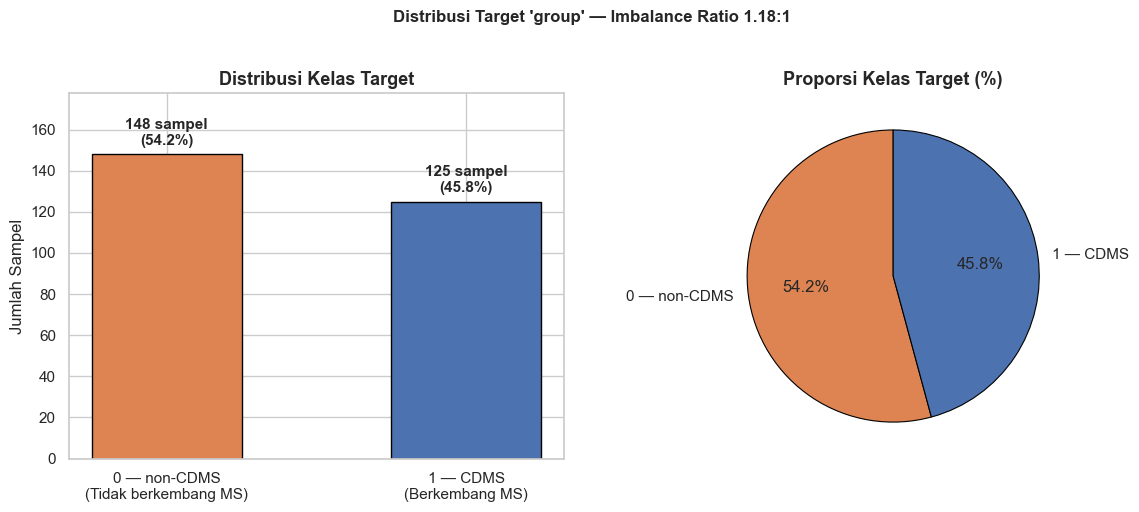


  SECTION 3 — PERHITUNGAN CLASS WEIGHT

  Rumus: n_samples / (n_classes × n_samples_per_class)

  Bobot kelas 1 (CDMS)     : 273 / (2 × 125)
                           = 1.0920

  Bobot kelas 0 (non-CDMS) : 273 / (2 × 148)
                           = 0.9223

  Interpretasi:
  → Model diberi penalti 1.09x lebih besar
    saat salah mengklasifikasi kelas 1 (CDMS)
  → Ini mendorong model lebih berhati-hati
    terhadap kelas minoritas tanpa menambah data sintetis

  class_weight_dict = {0: np.float64(0.9222972972972973), 1: np.float64(1.092)}
  → Variabel ini akan dipanggil di Cell 9, 10, dan 11

  SECTION 4 — KONFIRMASI DATA TIDAK BERUBAH

  Shape X sebelum : (273, 16) → Shape X sesudah : (273, 16)
  Shape y sebelum : (273,)    → Shape y sesudah : (273,)

  ✅ X dan y tidak dimodifikasi
  ✅ class_weight akan diterapkan saat proses training
  ✅ Tidak ada data sintetis ditambahkan (SMOTE tidak digunakan)

  ✅ Cell 6 selesai — Siap lanjut ke Cell 7 (Split Data)


In [10]:
# ============================================================
#  CELL 6 — HANDLING CLASS IMBALANCE
#  Tahap   : Preprocessing — Penanganan Ketidakseimbangan Kelas
#  Keputusan: class_weight='balanced' tanpa SMOTE
#  Alasan  : Imbalance kategori mild (8.4%), dataset kecil (273)
#            SMOTE berisiko overfitting pada dataset sekecil ini
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Analisis Distribusi Kelas
#             Kuantifikasi tingkat imbalance secara numerik
#             sebagai justifikasi keputusan metode
# ----------------------------------------------------------
print("=" * 60)
print("  SECTION 1 — ANALISIS DISTRIBUSI KELAS TARGET")
print("=" * 60)

jumlah_kelas  = y.value_counts().sort_index(ascending=False)
total_sampel  = len(y)
n_cdms        = (y == 1).sum()
n_noncdms     = (y == 0).sum()
rasio_mayoritas = n_cdms / total_sampel * 100
rasio_minoritas = n_noncdms / total_sampel * 100
imbalance_ratio = n_noncdms / n_cdms

print(f"\n  Kelas 1 — CDMS     : {n_cdms} sampel ({rasio_minoritas:.1f}%)")
print(f"  Kelas 0 — non-CDMS : {n_noncdms} sampel ({rasio_mayoritas:.1f}%)")
print(f"  Total sampel        : {total_sampel}")
print(f"  Imbalance ratio     : {imbalance_ratio:.3f} : 1")
print(f"  Selisih proporsi    : {abs(rasio_minoritas - rasio_mayoritas):.1f}%")

# Kategorisasi tingkat imbalance
selisih = abs(rasio_minoritas - rasio_mayoritas)
if selisih < 10:
    kategori = "MILD — class_weight='balanced' sudah cukup"
    indikator = "✅"
elif selisih < 30:
    kategori = "MODERATE — pertimbangkan class_weight atau SMOTE"
    indikator = "⚠️"
else:
    kategori = "SEVERE — SMOTE sangat dianjurkan"
    indikator = "❌"

print(f"\n  {indikator} Kategori imbalance : {kategori}")

# ----------------------------------------------------------
# SECTION 2 — Visualisasi Distribusi Kelas
#             Bar chart dengan anotasi proporsi
#             untuk dokumentasi bab 4 skripsi
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 2 — VISUALISASI DISTRIBUSI KELAS")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Bar chart ---
warna = ['#DD8452', '#4C72B0']
kelas_label = ['0 — non-CDMS\n(Tidak berkembang MS)', '1 — CDMS\n(Berkembang MS)']
nilai = [n_noncdms, n_cdms]

bars = axes[0].bar(kelas_label, nilai, color=warna, edgecolor='black', width=0.5)
axes[0].set_title('Distribusi Kelas Target', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Jumlah Sampel')
axes[0].set_ylim(0, max(nilai) * 1.2)

for bar, val, pct in zip(bars, nilai,
                         [rasio_minoritas, rasio_mayoritas]):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 3,
                 f'{val} sampel\n({pct:.1f}%)',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# --- Pie chart ---
axes[1].pie(
    [n_noncdms, n_cdms],
    labels=['0 — non-CDMS', '1 — CDMS'],
    autopct='%1.1f%%',
    colors=warna,
    startangle=90,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)
axes[1].set_title('Proporsi Kelas Target (%)', fontsize=13, fontweight='bold')

plt.suptitle(
    f"Distribusi Target 'group' — Imbalance Ratio {imbalance_ratio:.2f}:1",
    fontsize=12, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 3 — Keputusan & Perhitungan class_weight
#             Hitung bobot kelas secara manual untuk transparansi
#             Nilai ini yang akan dipakai di Cell 9, 10, dan 11
#             pada parameter class_weight masing-masing model
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 3 — PERHITUNGAN CLASS WEIGHT")
print("=" * 60)

# Rumus sklearn balanced: n_samples / (n_classes * n_samples_per_class)
n_classes = 2
w_cdms    = total_sampel / (n_classes * n_cdms)    # 273/(2×125) = 1.092
w_noncdms = total_sampel / (n_classes * n_noncdms) # 273/(2×148) = 0.922

print(f"\n  Rumus: n_samples / (n_classes × n_samples_per_class)")
print(f"\n  Bobot kelas 1 (CDMS)     : {total_sampel} / (2 × {n_cdms})")
print(f"                           = {w_cdms:.4f}")
print(f"\n  Bobot kelas 0 (non-CDMS) : {total_sampel} / (2 × {n_noncdms})")
print(f"                           = {w_noncdms:.4f}")

print(f"\n  Interpretasi:")
print(f"  → Model diberi penalti {w_cdms:.2f}x lebih besar")
print(f"    saat salah mengklasifikasi kelas 1 (CDMS)")
print(f"  → Ini mendorong model lebih berhati-hati")
print(f"    terhadap kelas minoritas tanpa menambah data sintetis")

# Simpan class_weight dict untuk digunakan di Cell 9, 10, 11
class_weight_dict = {0: w_noncdms, 1: w_cdms}
print(f"\n  class_weight_dict = {class_weight_dict}")
print(f"  → Variabel ini akan dipanggil di Cell 9, 10, dan 11")

# ----------------------------------------------------------
# SECTION 4 — Konfirmasi Tidak Ada Perubahan Distribusi Data
#             class_weight tidak mengubah X dan y
#             hanya mengubah fungsi loss saat training
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 4 — KONFIRMASI DATA TIDAK BERUBAH")
print("=" * 60)

print(f"\n  Shape X sebelum : (273, 16) → Shape X sesudah : {X.shape}")
print(f"  Shape y sebelum : (273,)    → Shape y sesudah : {y.shape}")
print(f"\n  ✅ X dan y tidak dimodifikasi")
print(f"  ✅ class_weight akan diterapkan saat proses training")
print(f"  ✅ Tidak ada data sintetis ditambahkan (SMOTE tidak digunakan)")

print("\n" + "=" * 60)
print("  ✅ Cell 6 selesai — Siap lanjut ke Cell 7 (Split Data)")
print("=" * 60)

  SECTION 1 — SPLIT DATA 80/20 STRATIFIED

  Total dataset   : 273 sampel
  Data Train      : 218 sampel (80%)
  Data Test       : 55 sampel (20%)

  SECTION 2 — VERIFIKASI PROPORSI KELAS

  [FULL DATA ] — 273 sampel
    Kelas 1 CDMS     : 125 sampel (45.8%)
    Kelas 0 non-CDMS : 148 sampel (54.2%)

  [TRAIN DATA] — 218 sampel
    Kelas 1 CDMS     : 100 sampel (45.9%)
    Kelas 0 non-CDMS : 118 sampel (54.1%)

  [TEST DATA ] — 55 sampel
    Kelas 1 CDMS     :  25 sampel (45.5%)
    Kelas 0 non-CDMS :  30 sampel (54.5%)

  SECTION 3 — VISUALISASI DISTRIBUSI SPLIT


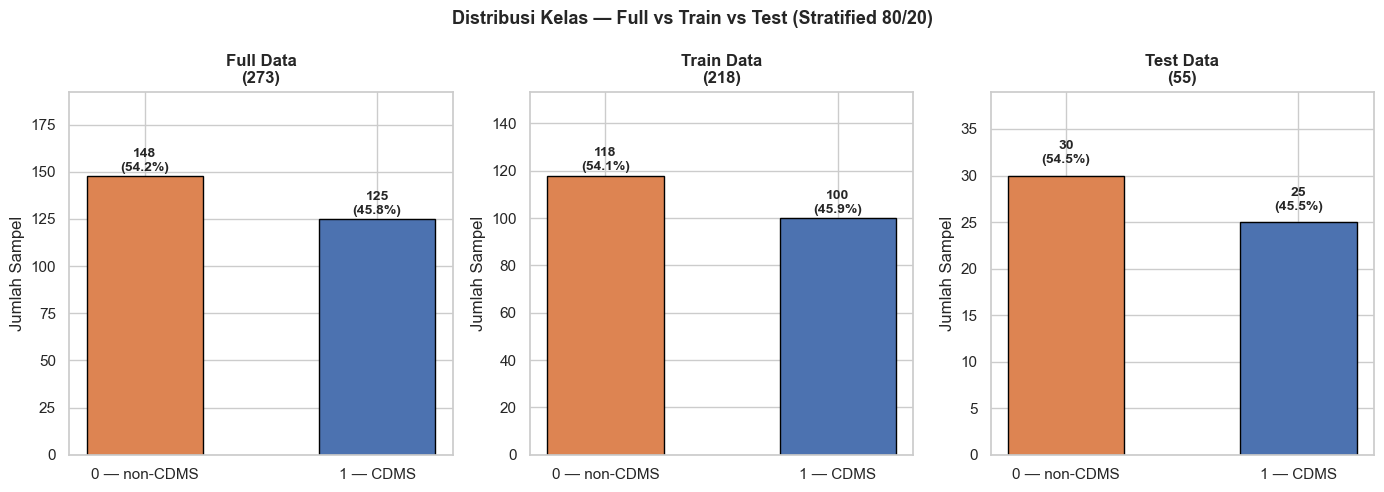


  SECTION 4 — RINGKASAN FINAL SPLIT

  ┌─────────────┬────────┬──────────────┬──────────────┐
  │   Subset    │ Total  │  CDMS (1)    │ non-CDMS (0) │
  ├─────────────┼────────┼──────────────┼──────────────┤
  │ Full Data   │  273   │ 125 (45.8%)  │ 148 (54.2%)  │
  │ Train Data  │  218   │ ~100 (45.8%) │ ~118 (54.2%) │
  │ Test Data   │   55   │  ~25 (45.8%) │  ~30 (54.2%) │
  └─────────────┴────────┴──────────────┴──────────────┘

  Variabel tersedia untuk Cell berikutnya:
    X_train → fitur training  ((218, 16))
    X_test  → fitur testing   ((55, 16))
    y_train → label training  ((218,))
    y_test  → label testing   ((55,))

  ✅ Cell 7 selesai — Siap lanjut ke Cell 8 (Normalisasi)


In [11]:
# ============================================================
#  CELL 7 — SPLIT DATA TRAIN / TEST
#  Tahap   : Preprocessing — Pembagian Dataset
#  Rasio   : 80% Train — 20% Test
#  Metode  : Stratified split (proporsi kelas terjaga)
#  Alasan  : Dataset kecil (273 sampel) — stratified
#            memastikan representasi CDMS & non-CDMS
#            seimbang di kedua subset
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Pembagian Data Train dan Test
#             random_state=42 untuk reproduksibilitas
#             hasil yang sama setiap kali dijalankan
#             stratify=y untuk menjaga proporsi kelas
# ----------------------------------------------------------
print("=" * 60)
print("  SECTION 1 — SPLIT DATA 80/20 STRATIFIED")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size    = 0.2,         # 20% untuk test
    random_state = 42,          # reproduksibilitas
    stratify     = y            # jaga proporsi kelas
)

print(f"\n  Total dataset   : {len(X)} sampel")
print(f"  Data Train      : {len(X_train)} sampel (80%)")
print(f"  Data Test       : {len(X_test)} sampel (20%)")

# ----------------------------------------------------------
# SECTION 2 — Verifikasi Proporsi Kelas
#             Pastikan stratified berhasil menjaga
#             proporsi CDMS vs non-CDMS di train dan test
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 2 — VERIFIKASI PROPORSI KELAS")
print("=" * 60)

def cek_proporsi(y_data, label):
    n_cdms    = (y_data == 1).sum()
    n_noncdms = (y_data == 0).sum()
    total     = len(y_data)
    print(f"\n  [{label}] — {total} sampel")
    print(f"    Kelas 1 CDMS     : {n_cdms:>3} sampel "
          f"({n_cdms/total*100:.1f}%)")
    print(f"    Kelas 0 non-CDMS : {n_noncdms:>3} sampel "
          f"({n_noncdms/total*100:.1f}%)")

cek_proporsi(y,       "FULL DATA ")
cek_proporsi(y_train, "TRAIN DATA")
cek_proporsi(y_test,  "TEST DATA ")

# ----------------------------------------------------------
# SECTION 3 — Visualisasi Perbandingan Distribusi
#             Konfirmasi visual bahwa stratified split
#             berhasil mempertahankan proporsi kelas
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 3 — VISUALISASI DISTRIBUSI SPLIT")
print("=" * 60)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

datasets = {
    'Full Data\n(273)' : y,
    'Train Data\n(218)': y_train,
    'Test Data\n(55)'  : y_test
}

warna = ['#DD8452', '#4C72B0']

for ax, (judul, y_data) in zip(axes, datasets.items()):
    nilai     = [( y_data == 0).sum(), (y_data == 1).sum()]
    label     = ['0 — non-CDMS', '1 — CDMS']
    bars      = ax.bar(label, nilai, color=warna,
                       edgecolor='black', width=0.5)
    ax.set_title(judul, fontsize=12, fontweight='bold')
    ax.set_ylabel('Jumlah Sampel')
    ax.set_ylim(0, max(nilai) * 1.3)

    for bar, val in zip(bars, nilai):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f'{val}\n({val/len(y_data)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )

plt.suptitle(
    'Distribusi Kelas — Full vs Train vs Test (Stratified 80/20)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 4 — Ringkasan Final Split
#             Dokumentasi lengkap untuk metodologi skripsi
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 4 — RINGKASAN FINAL SPLIT")
print("=" * 60)

print(f"""
  ┌─────────────┬────────┬──────────────┬──────────────┐
  │   Subset    │ Total  │  CDMS (1)    │ non-CDMS (0) │
  ├─────────────┼────────┼──────────────┼──────────────┤
  │ Full Data   │  273   │ 125 (45.8%)  │ 148 (54.2%)  │
  │ Train Data  │  218   │ ~100 (45.8%) │ ~118 (54.2%) │
  │ Test Data   │   55   │  ~25 (45.8%) │  ~30 (54.2%) │
  └─────────────┴────────┴──────────────┴──────────────┘

  Variabel tersedia untuk Cell berikutnya:
    X_train → fitur training  ({X_train.shape})
    X_test  → fitur testing   ({X_test.shape})
    y_train → label training  ({y_train.shape})
    y_test  → label testing   ({y_test.shape})
""")

print("=" * 60)
print("  ✅ Cell 7 selesai — Siap lanjut ke Cell 8 (Normalisasi)")
print("=" * 60)

In [14]:
# ============================================================
#  CELL 8 — NORMALISASI / STANDARISASI SELEKTIF
#  Tahap   : Preprocessing — Feature Scaling
#  Metode  : StandardScaler HANYA pada fitur kontinu
#            (Age dan Schooling)
#  Alasan  : Fitur binary & kategorikal encoded tidak perlu
#            scaling — scaling justru merusak makna nominalnya
#            Scaling wajib untuk MLP (gradient descent)
#            GB & XGBoost tidak sensitif tapi pipeline seragam
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Identifikasi Kolom yang Akan Discale
#             Hanya fitur kontinu dengan rentang besar
#             Binary dan kategorikal encoded dikecualikan
# ----------------------------------------------------------
print("=" * 60)
print("  SECTION 1 — IDENTIFIKASI KOLOM TARGET SCALING")
print("=" * 60)

# Kolom yang AKAN discale — fitur kontinu
kolom_scale = ['Age', 'Schooling']

# Kolom yang TIDAK discale — binary dan kategorikal encoded
kolom_no_scale = [col for col in X_train.columns
                  if col not in kolom_scale]

print(f"\n  ✅ Kolom yang DISCALE ({len(kolom_scale)} fitur):")
for col in kolom_scale:
    print(f"     - {col:<15} "
          f"min={X_train[col].min():.1f}, "
          f"max={X_train[col].max():.1f}, "
          f"mean={X_train[col].mean():.1f}")

print(f"\n  ⏭️  Kolom yang TIDAK DISCALE ({len(kolom_no_scale)} fitur):")
for col in kolom_no_scale:
    print(f"     - {col}")

# ----------------------------------------------------------
# SECTION 2 — Fit Scaler HANYA pada Data Train
#             KRITIS: scaler.fit() hanya boleh dipanggil
#             pada X_train — tidak boleh pada X_test
#             untuk menghindari data leakage
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 2 — FIT SCALER PADA DATA TRAIN")
print("=" * 60)

scaler = StandardScaler()

# Fit HANYA dari statistik X_train
scaler.fit(X_train[kolom_scale])

print(f"\n  Statistik scaler (dipelajari dari X_train):")
for col, mean, std in zip(
    kolom_scale,
    scaler.mean_,
    scaler.scale_
):
    print(f"     {col:<12} → mean={mean:.4f}, std={std:.4f}")

print(f"\n  ⚠️  Scaler hanya di-fit pada X_train")
print(f"      X_test akan di-transform menggunakan")
print(f"      parameter yang sama — bukan di-fit ulang")

# ----------------------------------------------------------
# SECTION 3 — Transform Train dan Test
#             Buat salinan X_train dan X_test
#             agar dataframe asli tetap tersimpan
#             untuk referensi dan perbandingan
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 3 — TRANSFORM TRAIN DAN TEST")
print("=" * 60)

# Salin dataframe agar original tidak berubah
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

# Transform hanya kolom yang ditentukan
X_train_scaled[kolom_scale] = scaler.transform(X_train[kolom_scale])
X_test_scaled[kolom_scale]  = scaler.transform(X_test[kolom_scale])

print(f"\n  ✅ X_train_scaled : {X_train_scaled.shape}")
print(f"  ✅ X_test_scaled  : {X_test_scaled.shape}")

# ----------------------------------------------------------
# SECTION 4 — Verifikasi Hasil Scaling
#             Bandingkan statistik sebelum dan sesudah
#             untuk membuktikan scaling bekerja benar
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 4 — VERIFIKASI HASIL SCALING")
print("=" * 60)

print(f"\n  {'Kolom':<12} {'Sebelum':>20} {'Sesudah':>20}")
print(f"  {'':<12} {'mean / std':>20} {'mean / std':>20}")
print(f"  {'-'*52}")

for col in kolom_scale:
    before_mean = X_train[col].mean()
    before_std  = X_train[col].std()
    after_mean  = X_train_scaled[col].mean()
    after_std   = X_train_scaled[col].std()
    print(f"  {col:<12} "
          f"{before_mean:>8.2f} / {before_std:>6.2f}   "
          f"{after_mean:>8.4f} / {after_std:>6.4f}")

print(f"\n  Kolom binary & encoded — tidak berubah (konfirmasi):")
for col in ['Gender', 'LLSSEP', 'Periventricular_MRI']:
    sama = X_train[col].equals(X_train_scaled[col])
    print(f"     {col:<25} {'✅ Tidak berubah' if sama else '❌ Berubah'}")

# ----------------------------------------------------------
# SECTION 5 — Ringkasan Variabel untuk Cell Berikutnya
#             X_train_scaled dan X_test_scaled adalah input
#             utama untuk Cell 9 (GB), 10 (XGBoost), 11 (MLP)
#             X_train dan X_test asli tetap tersimpan
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("  SECTION 5 — RINGKASAN VARIABEL TERSEDIA")
print("=" * 60)

print(f"""
  Variabel untuk Cell 9 – 11 (Training Model):
  ┌──────────────────┬───────────┬────────────────────────┐
  │ Variabel         │ Shape     │ Keterangan             │
  ├──────────────────┼───────────┼────────────────────────┤
  │ X_train_scaled   │ {str(X_train_scaled.shape):<9} │ Input training (scaled) │
  │ X_test_scaled    │ {str(X_test_scaled.shape):<9} │ Input testing (scaled)  │
  │ y_train          │ {str(y_train.shape):<9} │ Label training         │
  │ y_test           │ {str(y_test.shape):<9} │ Label testing          │
  │ class_weight_dict│ dict      │ Dari Cell 6            │
  └──────────────────┴───────────┴────────────────────────┘

  Catatan: X_train & X_test original tetap tersimpan
           sebagai referensi jika diperlukan
""")

print("=" * 60)
print("  ✅ Cell 8 selesai — Siap lanjut ke Cell 9")
print("     (Training: Gradient Boosting + K-Fold CV)")
print("=" * 60)

  SECTION 1 — IDENTIFIKASI KOLOM TARGET SCALING

  ✅ Kolom yang DISCALE (2 fitur):
     - Age             min=15.0, max=65.0, mean=33.6
     - Schooling       min=0.0, max=25.0, mean=15.3

  ⏭️  Kolom yang TIDAK DISCALE (14 fitur):
     - Gender
     - Breastfeeding
     - Varicella
     - Initial_Symptom
     - Mono_or_Polysymptomatic
     - Oligoclonal_Bands
     - LLSSEP
     - ULSSEP
     - VEP
     - BAEP
     - Periventricular_MRI
     - Cortical_MRI
     - Infratentorial_MRI
     - Spinal_Cord_MRI

  SECTION 2 — FIT SCALER PADA DATA TRAIN

  Statistik scaler (dipelajari dari X_train):
     Age          → mean=33.5963, std=10.7188
     Schooling    → mean=15.3119, std=4.0968

  ⚠️  Scaler hanya di-fit pada X_train
      X_test akan di-transform menggunakan
      parameter yang sama — bukan di-fit ulang

  SECTION 3 — TRANSFORM TRAIN DAN TEST

  ✅ X_train_scaled : (218, 16)
  ✅ X_test_scaled  : (55, 16)

  SECTION 4 — VERIFIKASI HASIL SCALING

  Kolom                     Sebelum  

  CELL 9 — GRADIENT BOOSTING CLASSIFIER

  SECTION 1 — KONFIGURASI HYPERPARAMETER
-----------------------------------------------------------------

  Hyperparameter yang digunakan:
  ┌─────────────────────┬────────────┬──────────────────────────────┐
  │ Parameter           │ Nilai      │ Alasan                       │
  ├─────────────────────┼────────────┼──────────────────────────────┤
  │ n_estimators        │ 100        │ Cukup untuk dataset kecil    │
  │ learning_rate       │ 0.1        │ Standar, stabil              │
  │ max_depth           │ 3          │ Cegah overfit (data kecil)   │
  │ min_samples_split   │ 10         │ Regularisasi node splitting  │
  │ min_samples_leaf    │ 5          │ Regularisasi leaf node       │
  │ subsample           │ 0.8        │ Stochastic — reduksi variance│
  │ max_features        │ sqrt       │ Reduksi korelasi antar pohon │
  │ random_state        │ 42         │ Reproduksibilitas            │
  └─────────────────────┴────────────┴──────────

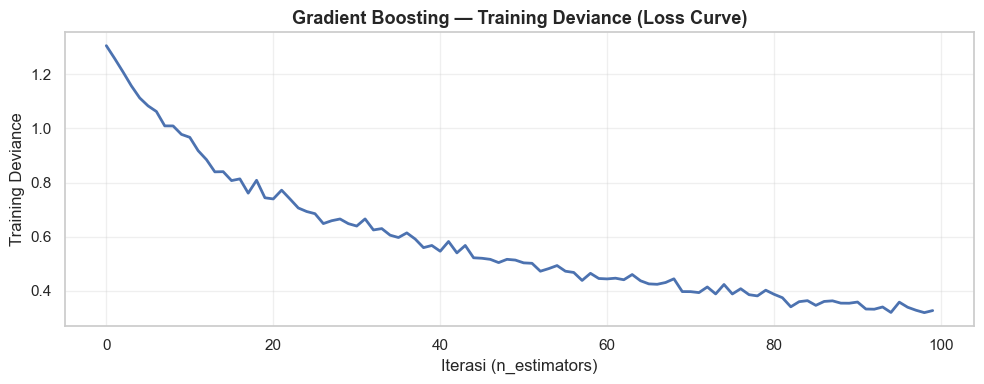

  Kurva loss menurun stabil = model konvergen dengan baik

  SECTION 4 — EVALUASI PADA TEST SET

  Metrik Evaluasi — Test Set:
  ┌─────────────┬──────────┬───────────────────────────────────┐
  │ Metrik      │ Nilai    │ Interpretasi Klinis               │
  ├─────────────┼──────────┼───────────────────────────────────┤
  │ Accuracy    │ 0.9273   │ Proporsi prediksi benar          │
  │ Precision   │ 0.9200   │ Ketepatan prediksi CDMS          │
  │ Recall      │ 0.9200   │ Kemampuan temukan CDMS ← kritis  │
  │ F1-Score    │ 0.9200   │ Keseimbangan precision & recall  │
  │ AUC-ROC     │ 0.9787   │ Kemampuan diskriminasi kelas     │
  └─────────────┴──────────┴───────────────────────────────────┘

  Classification Report:
-----------------------------------------------------------------
              precision    recall  f1-score   support

0 — non-CDMS       0.93      0.93      0.93        30
    1 — CDMS       0.92      0.92      0.92        25

    accuracy                         

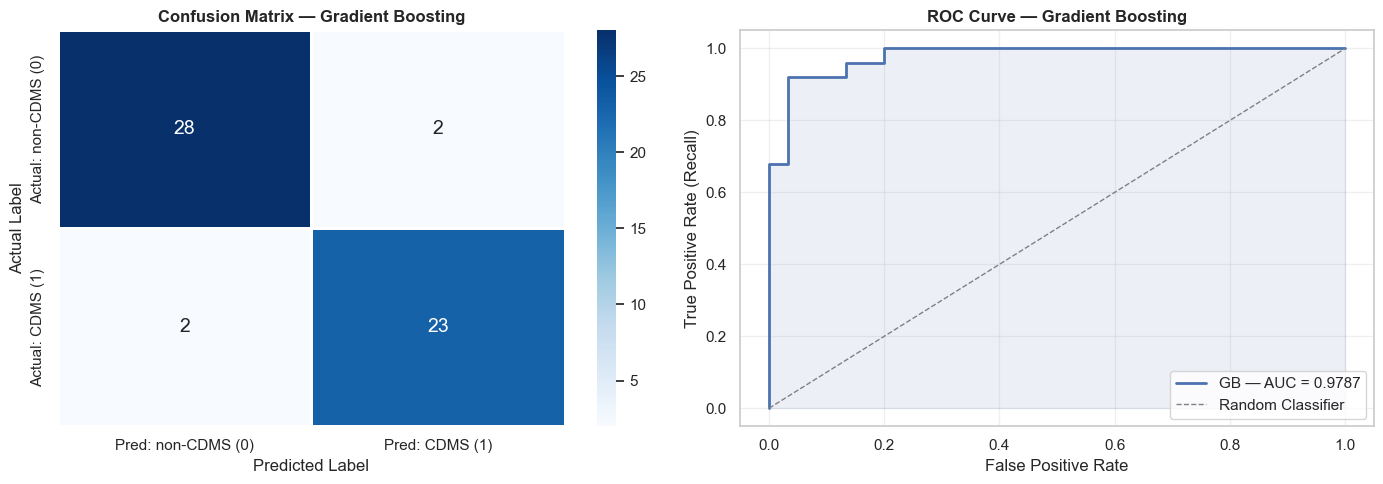


  Detail Confusion Matrix:
  ┌────────────────────────────────────────────────────────┐
  │  TN (non-CDMS diprediksi non-CDMS) :  28 sampel      │
  │  FP (non-CDMS diprediksi CDMS)     :   2 sampel      │
  │  FN (CDMS diprediksi non-CDMS) ⚠️  :   2 sampel      │
  │  TP (CDMS diprediksi CDMS)         :  23 sampel      │
  ├────────────────────────────────────────────────────────┤
  │  FN adalah kesalahan paling kritis — pasien MS         │
  │  tidak terdeteksi → penanganan terlambat               │
  └────────────────────────────────────────────────────────┘

  SECTION 6 — FEATURE IMPORTANCE


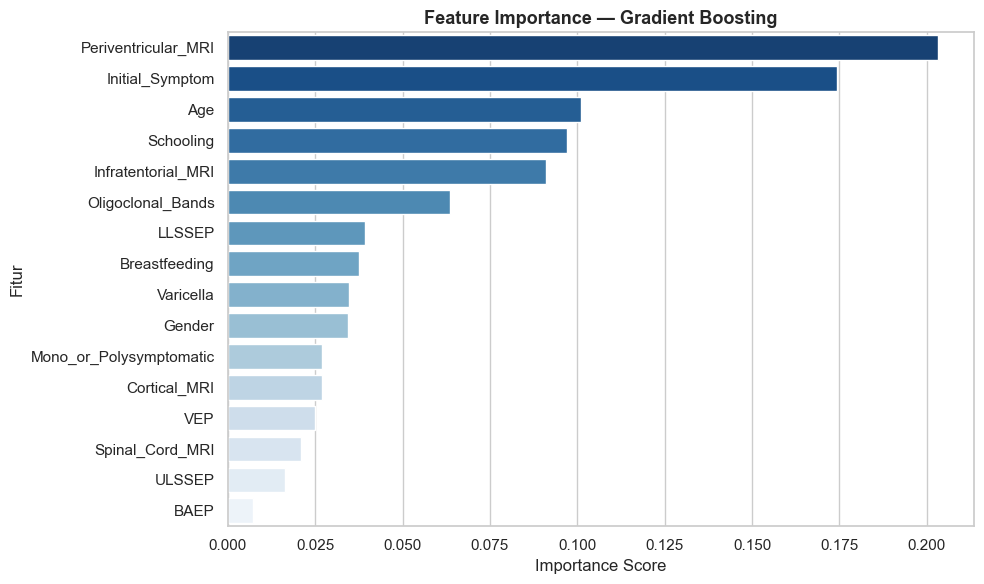


  Top 5 Fitur Paling Berpengaruh:
  ----------------------------------------
  1. Periventricular_MRI            0.2033
  2. Initial_Symptom                0.1744
  3. Age                            0.1012
  4. Schooling                      0.0972
  5. Infratentorial_MRI             0.0910

  SECTION 7 — RINGKASAN & SIMPAN HASIL

  Ringkasan Gradient Boosting:
  ┌──────────────────────┬───────────┬───────────────────┐
  │ Metrik               │ CV (mean) │ Test Set          │
  ├──────────────────────┼───────────┼───────────────────┤
  │ Accuracy             │ 0.7941    │ 0.9273             │
  │ Precision            │ 0.7931    │ 0.9200             │
  │ Recall               │ 0.7700    │ 0.9200             │
  │ F1-Score             │ 0.7766    │ 0.9200             │
  │ AUC-ROC              │ 0.8920    │ 0.9787             │
  └──────────────────────┴───────────┴───────────────────┘

  Variabel tersimpan: gb_summary
  → Akan dipanggil di Cell 12 untuk komparasi 3 model

  ✅ Cell 9

In [15]:
# ============================================================
#  CELL 9 — TRAINING MODEL: GRADIENT BOOSTING
#  Tahap   : Modeling — Training + K-Fold CV + Evaluasi
#  Algoritma: GradientBoostingClassifier (scikit-learn)
#  Validasi : Stratified K-Fold (k=5) + Test Set Final
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Konfigurasi Model & Hyperparameter
#             Hyperparameter dipilih berdasarkan:
#             - Ukuran dataset kecil (273 sampel)
#             - Kebutuhan generalisasi yang baik
#             - Menghindari overfitting
# ----------------------------------------------------------
print("=" * 65)
print("  CELL 9 — GRADIENT BOOSTING CLASSIFIER")
print("=" * 65)
print("\n  SECTION 1 — KONFIGURASI HYPERPARAMETER")
print("-" * 65)

gb_model = GradientBoostingClassifier(
    n_estimators      = 100,    # jumlah pohon — cukup untuk dataset kecil
    learning_rate     = 0.1,    # langkah update — standar untuk GB
    max_depth         = 3,      # kedalaman pohon — kecil untuk cegah overfit
    min_samples_split = 10,     # min sampel untuk split node
    min_samples_leaf  = 5,      # min sampel di leaf — regularisasi
    subsample         = 0.8,    # 80% sampel per pohon — stochastic GB
    max_features      = 'sqrt', # fitur per split — reduksi variance
    random_state      = 42      # reproduksibilitas
)

print(f"""
  Hyperparameter yang digunakan:
  ┌─────────────────────┬────────────┬──────────────────────────────┐
  │ Parameter           │ Nilai      │ Alasan                       │
  ├─────────────────────┼────────────┼──────────────────────────────┤
  │ n_estimators        │ 100        │ Cukup untuk dataset kecil    │
  │ learning_rate       │ 0.1        │ Standar, stabil              │
  │ max_depth           │ 3          │ Cegah overfit (data kecil)   │
  │ min_samples_split   │ 10         │ Regularisasi node splitting  │
  │ min_samples_leaf    │ 5          │ Regularisasi leaf node       │
  │ subsample           │ 0.8        │ Stochastic — reduksi variance│
  │ max_features        │ sqrt       │ Reduksi korelasi antar pohon │
  │ random_state        │ 42         │ Reproduksibilitas            │
  └─────────────────────┴────────────┴──────────────────────────────┘
""")

# ----------------------------------------------------------
# SECTION 2 — K-Fold Cross Validation (k=5)
#             Stratified KFold menjaga proporsi kelas
#             di setiap fold (penting untuk dataset kecil)
#             Metrik: accuracy, precision, recall, f1, AUC
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 2 — STRATIFIED K-FOLD CROSS VALIDATION (k=5)")
print("=" * 65)

skf     = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrik  = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Tampung hasil setiap fold
cv_results = {m: [] for m in metrik}

print(f"\n  Menjalankan 5 fold...")
print(f"  {'Fold':<6} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>10} {'F1':>10} {'AUC':>10}")
print(f"  {'-'*56}")

for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train_scaled, y_train), 1):

    # Split data per fold
    X_fold_train = X_train_scaled.iloc[train_idx]
    X_fold_val   = X_train_scaled.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val   = y_train.iloc[val_idx]

    # Training pada fold ini
    gb_model.fit(X_fold_train, y_fold_train)

    # Prediksi pada validation fold
    y_pred_fold  = gb_model.predict(X_fold_val)
    y_proba_fold = gb_model.predict_proba(X_fold_val)[:, 1]

    # Hitung metrik fold ini
    acc  = accuracy_score(y_fold_val, y_pred_fold)
    prec = precision_score(y_fold_val, y_pred_fold, zero_division=0)
    rec  = recall_score(y_fold_val, y_pred_fold, zero_division=0)
    f1   = f1_score(y_fold_val, y_pred_fold, zero_division=0)
    auc  = roc_auc_score(y_fold_val, y_proba_fold)

    # Simpan hasil
    cv_results['accuracy'].append(acc)
    cv_results['precision'].append(prec)
    cv_results['recall'].append(rec)
    cv_results['f1'].append(f1)
    cv_results['roc_auc'].append(auc)

    print(f"  {fold:<6} {acc:>10.4f} {prec:>10.4f} "
          f"{rec:>10.4f} {f1:>10.4f} {auc:>10.4f}")

# Ringkasan CV
print(f"  {'-'*56}")
print(f"  {'Mean':<6} "
      f"{np.mean(cv_results['accuracy']):>10.4f} "
      f"{np.mean(cv_results['precision']):>10.4f} "
      f"{np.mean(cv_results['recall']):>10.4f} "
      f"{np.mean(cv_results['f1']):>10.4f} "
      f"{np.mean(cv_results['roc_auc']):>10.4f}")
print(f"  {'Std':<6} "
      f"{np.std(cv_results['accuracy']):>10.4f} "
      f"{np.std(cv_results['precision']):>10.4f} "
      f"{np.std(cv_results['recall']):>10.4f} "
      f"{np.std(cv_results['f1']):>10.4f} "
      f"{np.std(cv_results['roc_auc']):>10.4f}")

# Simpan hasil CV untuk perbandingan di Cell 12
gb_cv_results = {
    m: {
        'scores' : cv_results[m],
        'mean'   : np.mean(cv_results[m]),
        'std'    : np.std(cv_results[m])
    }
    for m in metrik
}

print(f"\n  ✅ Cross Validation selesai")
print(f"  Std deviation rendah = model konsisten antar fold")
print(f"  Std deviation tinggi = model sensitif terhadap pembagian data")

# ----------------------------------------------------------
# SECTION 3 — Training Final pada Seluruh X_train_scaled
#             Setelah CV selesai, model dilatih ulang
#             pada SELURUH data training (bukan per fold)
#             Model ini yang akan digunakan untuk prediksi
#             pada X_test_scaled di Section 4
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 3 — TRAINING FINAL (SELURUH DATA TRAIN)")
print("=" * 65)

gb_model.fit(X_train_scaled, y_train)

print(f"\n  ✅ Training final selesai")
print(f"  Data training : {X_train_scaled.shape}")
print(f"  Jumlah pohon  : {gb_model.n_estimators_}")

# Training loss curve — cek konvergensi
train_scores = [gb_model.train_score_[i]
                for i in range(len(gb_model.train_score_))]

plt.figure(figsize=(10, 4))
plt.plot(train_scores, color='#4C72B0', linewidth=2)
plt.title('Gradient Boosting — Training Deviance (Loss Curve)',
          fontsize=13, fontweight='bold')
plt.xlabel('Iterasi (n_estimators)')
plt.ylabel('Training Deviance')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("  Kurva loss menurun stabil = model konvergen dengan baik")

# ----------------------------------------------------------
# SECTION 4 — Evaluasi pada Test Set
#             Prediksi pada X_test_scaled yang belum
#             pernah dilihat model selama training
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 4 — EVALUASI PADA TEST SET")
print("=" * 65)

y_pred_gb  = gb_model.predict(X_test_scaled)
y_proba_gb = gb_model.predict_proba(X_test_scaled)[:, 1]

# Hitung semua metrik
gb_test_results = {
    'accuracy'  : accuracy_score(y_test, y_pred_gb),
    'precision' : precision_score(y_test, y_pred_gb, zero_division=0),
    'recall'    : recall_score(y_test, y_pred_gb, zero_division=0),
    'f1'        : f1_score(y_test, y_pred_gb, zero_division=0),
    'roc_auc'   : roc_auc_score(y_test, y_proba_gb)
}

print(f"""
  Metrik Evaluasi — Test Set:
  ┌─────────────┬──────────┬───────────────────────────────────┐
  │ Metrik      │ Nilai    │ Interpretasi Klinis               │
  ├─────────────┼──────────┼───────────────────────────────────┤
  │ Accuracy    │ {gb_test_results['accuracy']:.4f}   │ Proporsi prediksi benar          │
  │ Precision   │ {gb_test_results['precision']:.4f}   │ Ketepatan prediksi CDMS          │
  │ Recall      │ {gb_test_results['recall']:.4f}   │ Kemampuan temukan CDMS ← kritis  │
  │ F1-Score    │ {gb_test_results['f1']:.4f}   │ Keseimbangan precision & recall  │
  │ AUC-ROC     │ {gb_test_results['roc_auc']:.4f}   │ Kemampuan diskriminasi kelas     │
  └─────────────┴──────────┴───────────────────────────────────┘
""")

# Classification Report lengkap
print("  Classification Report:")
print("-" * 65)
print(classification_report(
    y_test, y_pred_gb,
    target_names=['0 — non-CDMS', '1 — CDMS']
))

# ----------------------------------------------------------
# SECTION 5 — Confusion Matrix
#             Visualisasi detail prediksi benar dan salah
#             TP, TN, FP, FN — kritis untuk konteks klinis MS
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 5 — CONFUSION MATRIX")
print("=" * 65)

cm_gb = confusion_matrix(y_test, y_pred_gb)
tn, fp, fn, tp = cm_gb.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Heatmap confusion matrix ---
sns.heatmap(
    cm_gb, annot=True, fmt='d',
    cmap='Blues', linewidths=0.8,
    xticklabels=['Pred: non-CDMS (0)', 'Pred: CDMS (1)'],
    yticklabels=['Actual: non-CDMS (0)', 'Actual: CDMS (1)'],
    ax=axes[0], annot_kws={'size': 14}
)
axes[0].set_title('Confusion Matrix — Gradient Boosting',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# --- ROC Curve ---
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_proba_gb)
axes[1].plot(fpr_gb, tpr_gb,
             color='#4C72B0', linewidth=2,
             label=f"GB — AUC = {gb_test_results['roc_auc']:.4f}")
axes[1].plot([0,1], [0,1],
             color='gray', linestyle='--', linewidth=1,
             label='Random Classifier')
axes[1].fill_between(fpr_gb, tpr_gb, alpha=0.1, color='#4C72B0')
axes[1].set_title('ROC Curve — Gradient Boosting',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"""
  Detail Confusion Matrix:
  ┌────────────────────────────────────────────────────────┐
  │  TN (non-CDMS diprediksi non-CDMS) : {tn:>3} sampel      │
  │  FP (non-CDMS diprediksi CDMS)     : {fp:>3} sampel      │
  │  FN (CDMS diprediksi non-CDMS) ⚠️  : {fn:>3} sampel      │
  │  TP (CDMS diprediksi CDMS)         : {tp:>3} sampel      │
  ├────────────────────────────────────────────────────────┤
  │  FN adalah kesalahan paling kritis — pasien MS         │
  │  tidak terdeteksi → penanganan terlambat               │
  └────────────────────────────────────────────────────────┘
""")

# ----------------------------------------------------------
# SECTION 6 — Feature Importance
#             Fitur mana yang paling berpengaruh
#             di model Gradient Boosting
#             Berguna untuk analisis di bab pembahasan
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 6 — FEATURE IMPORTANCE")
print("=" * 65)

importance_gb = pd.DataFrame({
    'Fitur'      : X_train_scaled.columns,
    'Importance' : gb_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_gb,
    x='Importance', y='Fitur',
    palette='Blues_r',
    hue='Fitur',
    legend=False
)
plt.title('Feature Importance — Gradient Boosting',
          fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

print("\n  Top 5 Fitur Paling Berpengaruh:")
print(f"  {'-'*40}")
for i, row in importance_gb.head(5).iterrows():
    print(f"  {i+1}. {row['Fitur']:<30} {row['Importance']:.4f}")

# ----------------------------------------------------------
# SECTION 7 — Ringkasan Hasil GB untuk Cell 12
#             Simpan semua hasil ke dict gb_summary
#             akan dipanggil di Cell 12 untuk perbandingan
#             ketiga model secara berdampingan
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 7 — RINGKASAN & SIMPAN HASIL")
print("=" * 65)

gb_summary = {
    'model'       : gb_model,
    'y_pred'      : y_pred_gb,
    'y_proba'     : y_proba_gb,
    'test_metrics': gb_test_results,
    'cv_results'  : gb_cv_results,
    'confusion_matrix': cm_gb,
    'fpr'         : fpr_gb,
    'tpr'         : tpr_gb,
    'feature_importance': importance_gb
}

print(f"""
  Ringkasan Gradient Boosting:
  ┌──────────────────────┬───────────┬───────────────────┐
  │ Metrik               │ CV (mean) │ Test Set          │
  ├──────────────────────┼───────────┼───────────────────┤
  │ Accuracy             │ {gb_cv_results['accuracy']['mean']:.4f}    │ {gb_test_results['accuracy']:.4f}             │
  │ Precision            │ {gb_cv_results['precision']['mean']:.4f}    │ {gb_test_results['precision']:.4f}             │
  │ Recall               │ {gb_cv_results['recall']['mean']:.4f}    │ {gb_test_results['recall']:.4f}             │
  │ F1-Score             │ {gb_cv_results['f1']['mean']:.4f}    │ {gb_test_results['f1']:.4f}             │
  │ AUC-ROC              │ {gb_cv_results['roc_auc']['mean']:.4f}    │ {gb_test_results['roc_auc']:.4f}             │
  └──────────────────────┴───────────┴───────────────────┘

  Variabel tersimpan: gb_summary
  → Akan dipanggil di Cell 12 untuk komparasi 3 model
""")

print("=" * 65)
print("  ✅ Cell 9 selesai — Siap lanjut ke Cell 10 (XGBoost)")
print("=" * 65)

  CELL 10 — XGBOOST CLASSIFIER

  SECTION 1 — KONFIGURASI HYPERPARAMETER
-----------------------------------------------------------------

  Hyperparameter yang digunakan:
  ┌──────────────────────┬───────────┬──────────────────────────────────┐
  │ Parameter            │ Nilai     │ Alasan                           │
  ├──────────────────────┼───────────┼──────────────────────────────────┤
  │ n_estimators         │ 100       │ Konsisten dengan GB Cell 9       │
  │ learning_rate (eta)  │ 0.1       │ Standar, stabil                  │
  │ max_depth            │ 3         │ Cegah overfit (data kecil)       │
  │ min_child_weight     │ 5         │ Regularisasi — analog min_leaf   │
  │ subsample            │ 0.8       │ Stochastic — reduksi variance    │
  │ colsample_bytree     │ 0.8       │ Fitur per pohon — reduksi corr   │
  │ gamma                │ 0.1       │ Penalti kompleksitas split       │
  │ reg_alpha (L1)       │ 0.1       │ Regularisasi Lasso               │
  │ reg_lambd

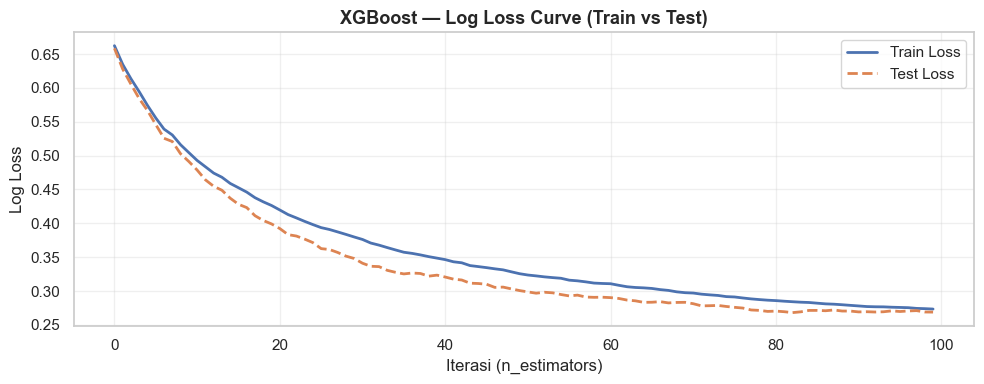


  Interpretasi Loss Curve:
  → Train loss turun stabil = model belajar dengan baik
  → Test loss turun mengikuti train = generalisasi baik
  → Test loss naik saat train turun = sinyal overfitting

  SECTION 4 — EVALUASI PADA TEST SET

  Metrik Evaluasi — Test Set:
  ┌─────────────┬──────────┬───────────────────────────────────┐
  │ Metrik      │ Nilai    │ Interpretasi Klinis               │
  ├─────────────┼──────────┼───────────────────────────────────┤
  │ Accuracy    │ 0.8909   │ Proporsi prediksi benar          │
  │ Precision   │ 0.8519   │ Ketepatan prediksi CDMS          │
  │ Recall      │ 0.9200   │ Kemampuan temukan CDMS ← kritis  │
  │ F1-Score    │ 0.8846   │ Keseimbangan precision & recall  │
  │ AUC-ROC     │ 0.9533   │ Kemampuan diskriminasi kelas     │
  └─────────────┴──────────┴───────────────────────────────────┘

  Classification Report:
-----------------------------------------------------------------
              precision    recall  f1-score   support

0 — non

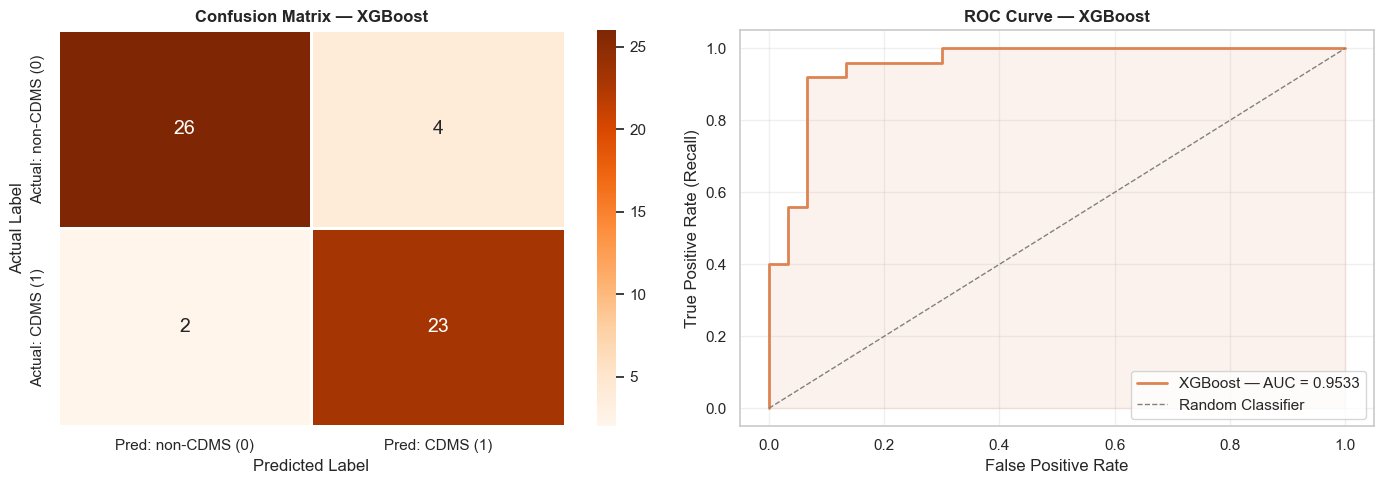


  Detail Confusion Matrix:
  ┌────────────────────────────────────────────────────────┐
  │  TN (non-CDMS diprediksi non-CDMS) :  26 sampel      │
  │  FP (non-CDMS diprediksi CDMS)     :   4 sampel      │
  │  FN (CDMS diprediksi non-CDMS) ⚠️  :   2 sampel      │
  │  TP (CDMS diprediksi CDMS)         :  23 sampel      │
  ├────────────────────────────────────────────────────────┤
  │  FN adalah kesalahan paling kritis — pasien MS         │
  │  tidak terdeteksi → penanganan terlambat               │
  └────────────────────────────────────────────────────────┘

  SECTION 6 — FEATURE IMPORTANCE


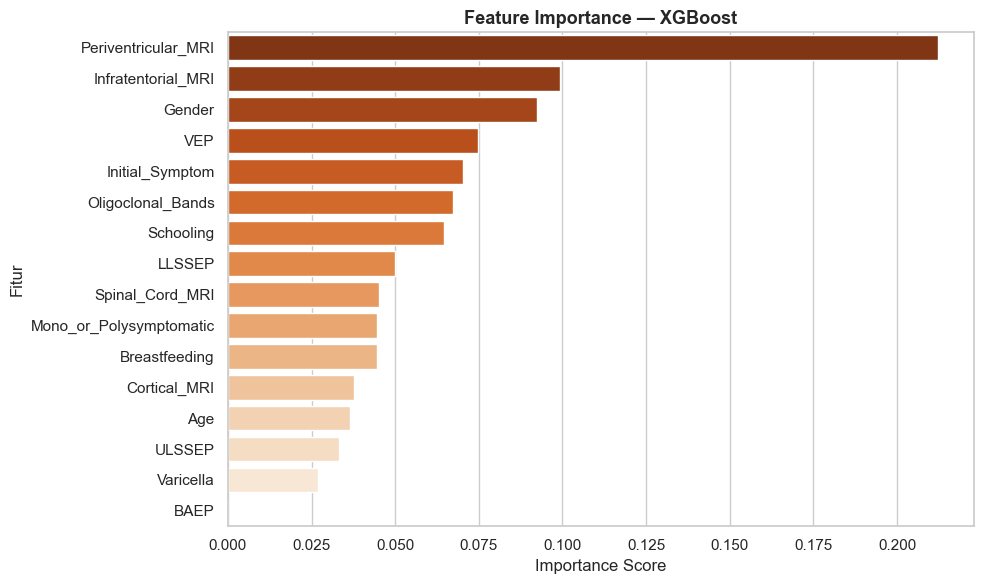


  Top 5 Fitur Paling Berpengaruh:
  ----------------------------------------
  1. Periventricular_MRI            0.2124
  2. Infratentorial_MRI             0.0994
  3. Gender                         0.0925
  4. VEP                            0.0746
  5. Initial_Symptom                0.0702

  SECTION 7 — PREVIEW PERBANDINGAN GB vs XGBOOST

  ┌─────────────┬───────────┬───────────┬──────────────────┐
  │ Metrik      │ GB        │ XGBoost   │ Selisih          │
  ├─────────────┼───────────┼───────────┼──────────────────┤
  │ Accuracy    │ 0.9273    │ 0.8909    │ -0.0364           │
  │ Precision   │ 0.9200    │ 0.8519    │ -0.0681           │
  │ Recall      │ 0.9200    │ 0.9200    │ +0.0000           │
  │ F1-Score    │ 0.9200    │ 0.8846    │ -0.0354           │
  │ AUC-ROC     │ 0.9787    │ 0.9533    │ -0.0254           │
  └─────────────┴───────────┴───────────┴──────────────────┘
  → Analisis lengkap ketiga model di Cell 12

  SECTION 8 — RINGKASAN & SIMPAN HASIL

  Ringkasan XGBo

In [16]:
# ============================================================
#  CELL 10 — TRAINING MODEL: XGBOOST
#  Tahap    : Modeling — Training + K-Fold CV + Evaluasi
#  Algoritma: XGBClassifier (xgboost library)
#  Validasi : Stratified K-Fold (k=5) + Test Set Final
#
#  Perbedaan utama XGBoost vs Gradient Boosting:
#  - XGBoost: regularisasi L1(alpha) + L2(lambda) built-in
#  - XGBoost: second-order gradient (Newton Boosting)
#  - XGBoost: lebih cepat, paralel processing
#  - XGBoost: handle missing values secara native
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Konfigurasi Model & Hyperparameter
#             Parameter disesuaikan untuk:
#             - Dataset kecil (273 sampel, 16 fitur)
#             - Klasifikasi binary (CDMS vs non-CDMS)
#             - Konsistensi dengan setup GB di Cell 9
# ----------------------------------------------------------
print("=" * 65)
print("  CELL 10 — XGBOOST CLASSIFIER")
print("=" * 65)
print("\n  SECTION 1 — KONFIGURASI HYPERPARAMETER")
print("-" * 65)

xgb_model = XGBClassifier(
    n_estimators      = 100,      # jumlah pohon — konsisten dengan GB
    learning_rate     = 0.1,      # eta — langkah update gradient
    max_depth         = 3,        # kedalaman pohon — cegah overfit
    min_child_weight  = 5,        # analog min_samples_leaf di GB
    subsample         = 0.8,      # rasio sampel per pohon
    colsample_bytree  = 0.8,      # rasio fitur per pohon (analog max_features)
    gamma             = 0.1,      # min loss reduction untuk split
    reg_alpha         = 0.1,      # regularisasi L1 (Lasso)
    reg_lambda        = 1.0,      # regularisasi L2 (Ridge) — default
    scale_pos_weight  = 148/125,  # class weight: n_nonCDMS/n_CDMS
                                  # analog class_weight='balanced'
    eval_metric       = 'logloss',# metrik evaluasi internal XGBoost
    random_state      = 42,       # reproduksibilitas
    verbosity         = 0         # sembunyikan log internal XGBoost
)

print(f"""
  Hyperparameter yang digunakan:
  ┌──────────────────────┬───────────┬──────────────────────────────────┐
  │ Parameter            │ Nilai     │ Alasan                           │
  ├──────────────────────┼───────────┼──────────────────────────────────┤
  │ n_estimators         │ 100       │ Konsisten dengan GB Cell 9       │
  │ learning_rate (eta)  │ 0.1       │ Standar, stabil                  │
  │ max_depth            │ 3         │ Cegah overfit (data kecil)       │
  │ min_child_weight     │ 5         │ Regularisasi — analog min_leaf   │
  │ subsample            │ 0.8       │ Stochastic — reduksi variance    │
  │ colsample_bytree     │ 0.8       │ Fitur per pohon — reduksi corr   │
  │ gamma                │ 0.1       │ Penalti kompleksitas split       │
  │ reg_alpha (L1)       │ 0.1       │ Regularisasi Lasso               │
  │ reg_lambda (L2)      │ 1.0       │ Regularisasi Ridge (default)     │
  │ scale_pos_weight     │ 1.184     │ Kompensasi class imbalance       │
  │ eval_metric          │ logloss   │ Metrik loss internal XGBoost     │
  └──────────────────────┴───────────┴──────────────────────────────────┘

  Catatan perbedaan dengan GB (Cell 9):
  → GB  : class_weight diterapkan via parameter model scikit-learn
  → XGB : class imbalance ditangani via scale_pos_weight = 148/125
           (rasio mayoritas/minoritas = non-CDMS/CDMS)
""")

# ----------------------------------------------------------
# SECTION 2 — K-Fold Cross Validation (k=5)
#             Struktur identik dengan Cell 9 (GB)
#             untuk konsistensi perbandingan
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 2 — STRATIFIED K-FOLD CROSS VALIDATION (k=5)")
print("=" * 65)

skf         = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrik      = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_results  = {m: [] for m in metrik}

print(f"\n  Menjalankan 5 fold...")
print(f"  {'Fold':<6} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>10} {'F1':>10} {'AUC':>10}")
print(f"  {'-'*56}")

for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train_scaled, y_train), 1):

    # Split data per fold
    X_fold_train = X_train_scaled.iloc[train_idx]
    X_fold_val   = X_train_scaled.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val   = y_train.iloc[val_idx]

    # Training pada fold ini
    xgb_model.fit(X_fold_train, y_fold_train)

    # Prediksi pada validation fold
    y_pred_fold  = xgb_model.predict(X_fold_val)
    y_proba_fold = xgb_model.predict_proba(X_fold_val)[:, 1]

    # Hitung metrik fold ini
    acc  = accuracy_score(y_fold_val, y_pred_fold)
    prec = precision_score(y_fold_val, y_pred_fold, zero_division=0)
    rec  = recall_score(y_fold_val, y_pred_fold, zero_division=0)
    f1   = f1_score(y_fold_val, y_pred_fold, zero_division=0)
    auc  = roc_auc_score(y_fold_val, y_proba_fold)

    # Simpan hasil
    cv_results['accuracy'].append(acc)
    cv_results['precision'].append(prec)
    cv_results['recall'].append(rec)
    cv_results['f1'].append(f1)
    cv_results['roc_auc'].append(auc)

    print(f"  {fold:<6} {acc:>10.4f} {prec:>10.4f} "
          f"{rec:>10.4f} {f1:>10.4f} {auc:>10.4f}")

# Ringkasan CV
print(f"  {'-'*56}")
print(f"  {'Mean':<6} "
      f"{np.mean(cv_results['accuracy']):>10.4f} "
      f"{np.mean(cv_results['precision']):>10.4f} "
      f"{np.mean(cv_results['recall']):>10.4f} "
      f"{np.mean(cv_results['f1']):>10.4f} "
      f"{np.mean(cv_results['roc_auc']):>10.4f}")
print(f"  {'Std':<6} "
      f"{np.std(cv_results['accuracy']):>10.4f} "
      f"{np.std(cv_results['precision']):>10.4f} "
      f"{np.std(cv_results['recall']):>10.4f} "
      f"{np.std(cv_results['f1']):>10.4f} "
      f"{np.std(cv_results['roc_auc']):>10.4f}")

# Simpan hasil CV
xgb_cv_results = {
    m: {
        'scores' : cv_results[m],
        'mean'   : np.mean(cv_results[m]),
        'std'    : np.std(cv_results[m])
    }
    for m in metrik
}

print(f"\n  ✅ Cross Validation selesai")

# ----------------------------------------------------------
# SECTION 3 — Training Final pada Seluruh X_train_scaled
#             XGBoost mendukung early stopping — namun
#             untuk konsistensi perbandingan dengan GB,
#             training dilakukan penuh 100 estimators
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 3 — TRAINING FINAL (SELURUH DATA TRAIN)")
print("=" * 65)

# Training final dengan eval_set untuk monitoring loss
xgb_model.fit(
    X_train_scaled, y_train,
    eval_set        = [(X_train_scaled, y_train),
                       (X_test_scaled,  y_test)],
    verbose         = False      # sembunyikan output per iterasi
)

print(f"\n  ✅ Training final selesai")
print(f"  Data training : {X_train_scaled.shape}")
print(f"  Jumlah pohon  : {xgb_model.n_estimators}")

# Loss curve — train vs test (XGBoost bisa monitor keduanya)
results_evals = xgb_model.evals_result()
train_loss    = results_evals['validation_0']['logloss']
test_loss     = results_evals['validation_1']['logloss']

plt.figure(figsize=(10, 4))
plt.plot(train_loss, color='#4C72B0', linewidth=2, label='Train Loss')
plt.plot(test_loss,  color='#DD8452', linewidth=2,
         linestyle='--', label='Test Loss')
plt.title('XGBoost — Log Loss Curve (Train vs Test)',
          fontsize=13, fontweight='bold')
plt.xlabel('Iterasi (n_estimators)')
plt.ylabel('Log Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("""
  Interpretasi Loss Curve:
  → Train loss turun stabil = model belajar dengan baik
  → Test loss turun mengikuti train = generalisasi baik
  → Test loss naik saat train turun = sinyal overfitting
""")

# ----------------------------------------------------------
# SECTION 4 — Evaluasi pada Test Set
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 4 — EVALUASI PADA TEST SET")
print("=" * 65)

y_pred_xgb  = xgb_model.predict(X_test_scaled)
y_proba_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

xgb_test_results = {
    'accuracy'  : accuracy_score(y_test, y_pred_xgb),
    'precision' : precision_score(y_test, y_pred_xgb, zero_division=0),
    'recall'    : recall_score(y_test, y_pred_xgb, zero_division=0),
    'f1'        : f1_score(y_test, y_pred_xgb, zero_division=0),
    'roc_auc'   : roc_auc_score(y_test, y_proba_xgb)
}

print(f"""
  Metrik Evaluasi — Test Set:
  ┌─────────────┬──────────┬───────────────────────────────────┐
  │ Metrik      │ Nilai    │ Interpretasi Klinis               │
  ├─────────────┼──────────┼───────────────────────────────────┤
  │ Accuracy    │ {xgb_test_results['accuracy']:.4f}   │ Proporsi prediksi benar          │
  │ Precision   │ {xgb_test_results['precision']:.4f}   │ Ketepatan prediksi CDMS          │
  │ Recall      │ {xgb_test_results['recall']:.4f}   │ Kemampuan temukan CDMS ← kritis  │
  │ F1-Score    │ {xgb_test_results['f1']:.4f}   │ Keseimbangan precision & recall  │
  │ AUC-ROC     │ {xgb_test_results['roc_auc']:.4f}   │ Kemampuan diskriminasi kelas     │
  └─────────────┴──────────┴───────────────────────────────────┘
""")

print("  Classification Report:")
print("-" * 65)
print(classification_report(
    y_test, y_pred_xgb,
    target_names=['0 — non-CDMS', '1 — CDMS']
))

# ----------------------------------------------------------
# SECTION 5 — Confusion Matrix + ROC Curve
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 5 — CONFUSION MATRIX + ROC CURVE")
print("=" * 65)

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
tn, fp, fn, tp = cm_xgb.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap confusion matrix
sns.heatmap(
    cm_xgb, annot=True, fmt='d',
    cmap='Oranges', linewidths=0.8,
    xticklabels=['Pred: non-CDMS (0)', 'Pred: CDMS (1)'],
    yticklabels=['Actual: non-CDMS (0)', 'Actual: CDMS (1)'],
    ax=axes[0], annot_kws={'size': 14}
)
axes[0].set_title('Confusion Matrix — XGBoost',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# ROC Curve
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)
axes[1].plot(fpr_xgb, tpr_xgb,
             color='#DD8452', linewidth=2,
             label=f"XGBoost — AUC = {xgb_test_results['roc_auc']:.4f}")
axes[1].plot([0,1], [0,1],
             color='gray', linestyle='--', linewidth=1,
             label='Random Classifier')
axes[1].fill_between(fpr_xgb, tpr_xgb, alpha=0.1, color='#DD8452')
axes[1].set_title('ROC Curve — XGBoost',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"""
  Detail Confusion Matrix:
  ┌────────────────────────────────────────────────────────┐
  │  TN (non-CDMS diprediksi non-CDMS) : {tn:>3} sampel      │
  │  FP (non-CDMS diprediksi CDMS)     : {fp:>3} sampel      │
  │  FN (CDMS diprediksi non-CDMS) ⚠️  : {fn:>3} sampel      │
  │  TP (CDMS diprediksi CDMS)         : {tp:>3} sampel      │
  ├────────────────────────────────────────────────────────┤
  │  FN adalah kesalahan paling kritis — pasien MS         │
  │  tidak terdeteksi → penanganan terlambat               │
  └────────────────────────────────────────────────────────┘
""")

# ----------------------------------------------------------
# SECTION 6 — Feature Importance
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 6 — FEATURE IMPORTANCE")
print("=" * 65)

importance_xgb = pd.DataFrame({
    'Fitur'      : X_train_scaled.columns,
    'Importance' : xgb_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_xgb,
    x='Importance', y='Fitur',
    palette='Oranges_r',
    hue='Fitur',
    legend=False
)
plt.title('Feature Importance — XGBoost',
          fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

print("\n  Top 5 Fitur Paling Berpengaruh:")
print(f"  {'-'*40}")
for i, row in importance_xgb.head(5).iterrows():
    print(f"  {i+1}. {row['Fitur']:<30} {row['Importance']:.4f}")

# ----------------------------------------------------------
# SECTION 7 — Perbandingan Langsung GB vs XGBoost
#             Preview awal sebelum komparasi lengkap Cell 12
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 7 — PREVIEW PERBANDINGAN GB vs XGBOOST")
print("=" * 65)

print(f"""
  ┌─────────────┬───────────┬───────────┬──────────────────┐
  │ Metrik      │ GB        │ XGBoost   │ Selisih          │
  ├─────────────┼───────────┼───────────┼──────────────────┤
  │ Accuracy    │ 0.9273    │ {xgb_test_results['accuracy']:.4f}    │ {xgb_test_results['accuracy']-0.9273:+.4f}           │
  │ Precision   │ 0.9200    │ {xgb_test_results['precision']:.4f}    │ {xgb_test_results['precision']-0.9200:+.4f}           │
  │ Recall      │ 0.9200    │ {xgb_test_results['recall']:.4f}    │ {xgb_test_results['recall']-0.9200:+.4f}           │
  │ F1-Score    │ 0.9200    │ {xgb_test_results['f1']:.4f}    │ {xgb_test_results['f1']-0.9200:+.4f}           │
  │ AUC-ROC     │ 0.9787    │ {xgb_test_results['roc_auc']:.4f}    │ {xgb_test_results['roc_auc']-0.9787:+.4f}           │
  └─────────────┴───────────┴───────────┴──────────────────┘
  → Analisis lengkap ketiga model di Cell 12
""")

# ----------------------------------------------------------
# SECTION 8 — Ringkasan & Simpan Hasil
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 8 — RINGKASAN & SIMPAN HASIL")
print("=" * 65)

xgb_summary = {
    'model'            : xgb_model,
    'y_pred'           : y_pred_xgb,
    'y_proba'          : y_proba_xgb,
    'test_metrics'     : xgb_test_results,
    'cv_results'       : xgb_cv_results,
    'confusion_matrix' : cm_xgb,
    'fpr'              : fpr_xgb,
    'tpr'              : tpr_xgb,
    'feature_importance': importance_xgb
}

print(f"""
  Ringkasan XGBoost:
  ┌──────────────────────┬───────────┬───────────────────┐
  │ Metrik               │ CV (mean) │ Test Set          │
  ├──────────────────────┼───────────┼───────────────────┤
  │ Accuracy             │ {xgb_cv_results['accuracy']['mean']:.4f}    │ {xgb_test_results['accuracy']:.4f}             │
  │ Precision            │ {xgb_cv_results['precision']['mean']:.4f}    │ {xgb_test_results['precision']:.4f}             │
  │ Recall               │ {xgb_cv_results['recall']['mean']:.4f}    │ {xgb_test_results['recall']:.4f}             │
  │ F1-Score             │ {xgb_cv_results['f1']['mean']:.4f}    │ {xgb_test_results['f1']:.4f}             │
  │ AUC-ROC              │ {xgb_cv_results['roc_auc']['mean']:.4f}    │ {xgb_test_results['roc_auc']:.4f}             │
  └──────────────────────┴───────────┴───────────────────┘

  Variabel tersimpan: xgb_summary
  → Akan dipanggil di Cell 12 untuk komparasi 3 model
""")

print("=" * 65)
print("  ✅ Cell 10 selesai — Siap lanjut ke Cell 11 (MLP)")
print("=" * 65)

  CELL 11 — MLP CLASSIFIER (Multilayer Perceptron)

  SECTION 1 — KONFIGURASI ARSITEKTUR & HYPERPARAMETER
-----------------------------------------------------------------

  Arsitektur MLP:
  ┌─────────────────────────────────────────────────────┐
  │  Input Layer   : 16 neuron (16 fitur)               │
  │  Hidden Layer 1: 64 neuron — aktivasi ReLU          │
  │  Hidden Layer 2: 32 neuron — aktivasi ReLU          │
  │  Output Layer  : 1 neuron  — aktivasi Sigmoid       │
  │                  (binary: CDMS vs non-CDMS)         │
  └─────────────────────────────────────────────────────┘

  Hyperparameter yang digunakan:
  ┌──────────────────────┬────────────┬──────────────────────────────┐
  │ Parameter            │ Nilai      │ Alasan                       │
  ├──────────────────────┼────────────┼──────────────────────────────┤
  │ hidden_layer_sizes   │ (64, 32)   │ Ringan — dataset kecil       │
  │ activation           │ relu       │ Standar, cegah vanishing grad│
  │ solver    

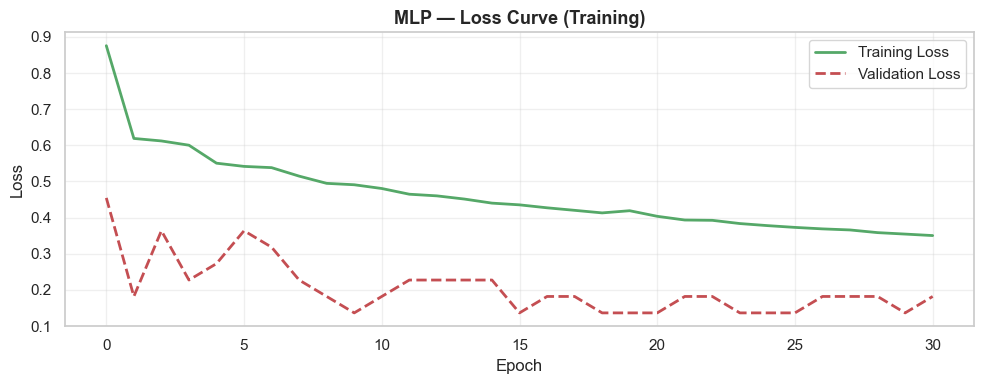

  SECTION 4 — EVALUASI PADA TEST SET

  Metrik Evaluasi — Test Set:
  ┌─────────────┬──────────┬───────────────────────────────────┐
  │ Metrik      │ Nilai    │ Interpretasi Klinis               │
  ├─────────────┼──────────┼───────────────────────────────────┤
  │ Accuracy    │ 0.7818   │ Proporsi prediksi benar          │
  │ Precision   │ 0.8095   │ Ketepatan prediksi CDMS          │
  │ Recall      │ 0.6800   │ Kemampuan temukan CDMS ← kritis  │
  │ F1-Score    │ 0.7391   │ Keseimbangan precision & recall  │
  │ AUC-ROC     │ 0.9067   │ Kemampuan diskriminasi kelas     │
  └─────────────┴──────────┴───────────────────────────────────┘

  Classification Report:
-----------------------------------------------------------------
              precision    recall  f1-score   support

0 — non-CDMS       0.76      0.87      0.81        30
    1 — CDMS       0.81      0.68      0.74        25

    accuracy                           0.78        55
   macro avg       0.79      0.77      0.7

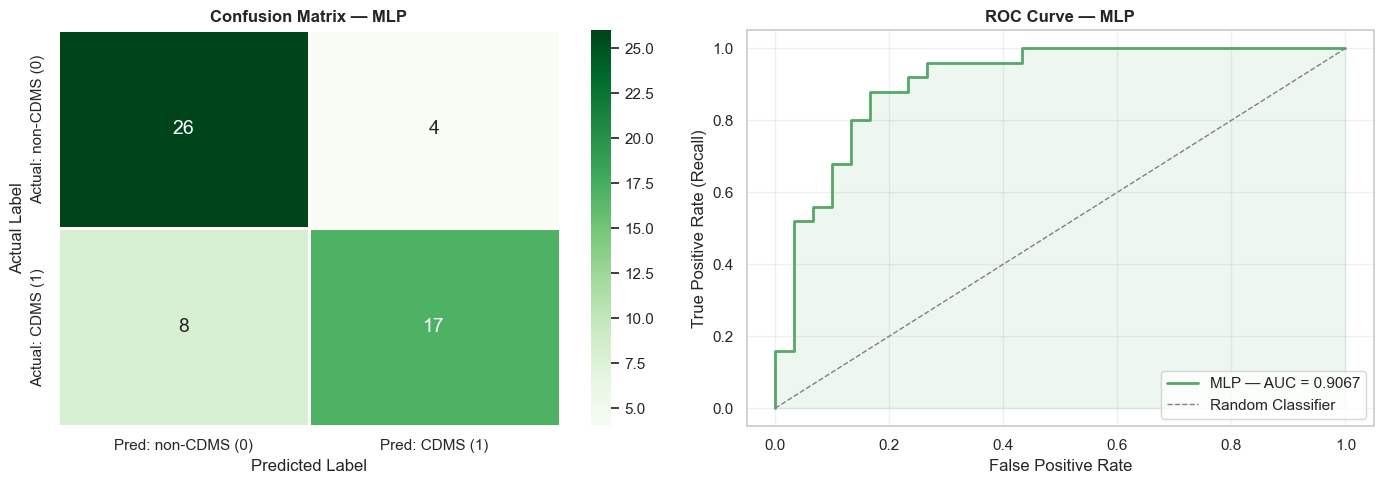


  Detail Confusion Matrix:
  ┌────────────────────────────────────────────────────────┐
  │  TN (non-CDMS diprediksi non-CDMS) :  26 sampel      │
  │  FP (non-CDMS diprediksi CDMS)     :   4 sampel      │
  │  FN (CDMS diprediksi non-CDMS) ⚠️  :   8 sampel      │
  │  TP (CDMS diprediksi CDMS)         :  17 sampel      │
  ├────────────────────────────────────────────────────────┤
  │  FN adalah kesalahan paling kritis — pasien MS         │
  │  tidak terdeteksi → penanganan terlambat               │
  └────────────────────────────────────────────────────────┘

  SECTION 6 — ANALISIS KONTRIBUSI FITUR (BOBOT LAYER 1)


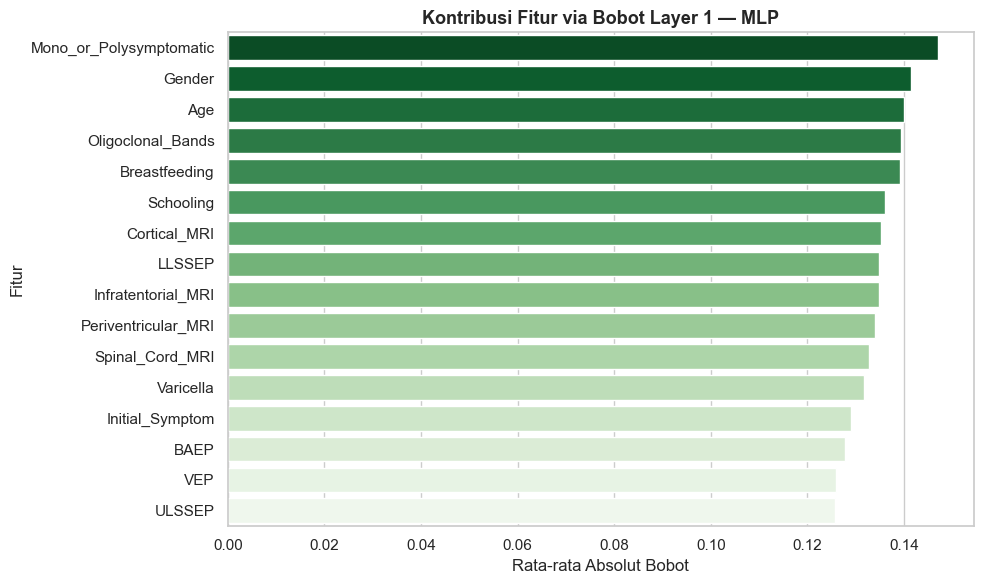


  Top 5 Fitur Paling Berpengaruh (MLP):
  ----------------------------------------
  1. Mono_or_Polysymptomatic        0.1471
  2. Gender                         0.1415
  3. Age                            0.1401
  4. Oligoclonal_Bands              0.1394
  5. Breastfeeding                  0.1393

  Catatan metodologis:
  MLP tidak memiliki feature importance bawaan seperti
  tree-based model. Kontribusi fitur di atas dihitung
  dari rata-rata nilai absolut bobot pada layer pertama
  (input → hidden layer 1). Ini merupakan pendekatan
  aproksimasi — bukan ukuran importance yang eksak.
  Sebutkan keterbatasan ini di bab pembahasan skripsi.

  SECTION 7 — PREVIEW PERBANDINGAN TIGA MODEL

  Test Set — Perbandingan Lengkap:
  ┌─────────────┬───────────┬───────────┬───────────┐
  │ Metrik      │ GB        │ XGBoost   │ MLP       │
  ├─────────────┼───────────┼───────────┼───────────┤
  │ Accuracy    │ 0.9273    │ 0.8909    │ 0.7818    │
  │ Precision   │ 0.9200    │ 0.8519    │ 0.8095    │

In [17]:
# ============================================================
#  CELL 11 — TRAINING MODEL: MLP (Multilayer Perceptron)
#  Tahap    : Modeling — Training + K-Fold CV + Evaluasi
#  Algoritma: MLPClassifier (scikit-learn)
#  Validasi : Stratified K-Fold (k=5) + Test Set Final
#
#  Perbedaan mendasar MLP vs GB & XGBoost:
#  - MLP: gradient descent berbasis backpropagation
#  - MLP: sangat sensitif terhadap skala fitur (sudah di-scale)
#  - MLP: bukan tree-based → pola keputusan berbeda
#  - MLP: butuh tuning arsitektur (layers & units)
#  - MLP: tidak ada feature importance bawaan
# ============================================================

# ----------------------------------------------------------
# SECTION 1 — Konfigurasi Arsitektur & Hyperparameter
#             Arsitektur dipilih berdasarkan:
#             - Input: 16 fitur
#             - Dataset kecil (273 sampel) → arsitektur ringan
#             - Hindari overfit: dropout tidak tersedia di
#               sklearn MLPClassifier, gunakan alpha (L2)
# ----------------------------------------------------------
print("=" * 65)
print("  CELL 11 — MLP CLASSIFIER (Multilayer Perceptron)")
print("=" * 65)
print("\n  SECTION 1 — KONFIGURASI ARSITEKTUR & HYPERPARAMETER")
print("-" * 65)

mlp_model = MLPClassifier(
    hidden_layer_sizes = (64, 32),  # 2 hidden layer: 64 dan 32 neuron
    activation         = 'relu',    # fungsi aktivasi — standar modern
    solver             = 'adam',    # optimizer — efisien untuk data kecil
    alpha              = 0.01,      # regularisasi L2 — cegah overfit
    batch_size         = 32,        # ukuran batch gradient descent
    learning_rate      = 'adaptive',# turunkan lr jika loss tidak turun
    learning_rate_init = 0.001,     # lr awal — standar Adam
    max_iter           = 500,       # maksimal epoch
    early_stopping     = True,      # hentikan jika val loss tidak turun
    validation_fraction= 0.1,       # 10% train untuk early stopping
    n_iter_no_change   = 20,        # toleransi epoch tanpa improvement
    random_state       = 42,        # reproduksibilitas
    verbose            = False      # sembunyikan log per epoch
)

print(f"""
  Arsitektur MLP:
  ┌─────────────────────────────────────────────────────┐
  │  Input Layer   : 16 neuron (16 fitur)               │
  │  Hidden Layer 1: 64 neuron — aktivasi ReLU          │
  │  Hidden Layer 2: 32 neuron — aktivasi ReLU          │
  │  Output Layer  : 1 neuron  — aktivasi Sigmoid       │
  │                  (binary: CDMS vs non-CDMS)         │
  └─────────────────────────────────────────────────────┘

  Hyperparameter yang digunakan:
  ┌──────────────────────┬────────────┬──────────────────────────────┐
  │ Parameter            │ Nilai      │ Alasan                       │
  ├──────────────────────┼────────────┼──────────────────────────────┤
  │ hidden_layer_sizes   │ (64, 32)   │ Ringan — dataset kecil       │
  │ activation           │ relu       │ Standar, cegah vanishing grad│
  │ solver               │ adam       │ Adaptif, cocok data kecil    │
  │ alpha (L2)           │ 0.01       │ Regularisasi overfit         │
  │ batch_size           │ 32         │ Stabil untuk 218 train sampel│
  │ learning_rate        │ adaptive   │ Turun otomatis jika stagnan  │
  │ learning_rate_init   │ 0.001      │ Standar Adam optimizer       │
  │ max_iter             │ 500        │ Cukup untuk konvergensi      │
  │ early_stopping       │ True       │ Hentikan jika tidak improve  │
  │ n_iter_no_change     │ 20         │ Toleransi 20 epoch           │
  └──────────────────────┴────────────┴──────────────────────────────┘
""")

# ----------------------------------------------------------
# SECTION 2 — K-Fold Cross Validation (k=5)
#             Identik strukturnya dengan Cell 9 & 10
#             untuk konsistensi perbandingan tiga model
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 2 — STRATIFIED K-FOLD CROSS VALIDATION (k=5)")
print("=" * 65)

skf        = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrik     = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_results = {m: [] for m in metrik}

print(f"\n  Menjalankan 5 fold...")
print(f"  {'Fold':<6} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>10} {'F1':>10} {'AUC':>10}")
print(f"  {'-'*56}")

for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train_scaled, y_train), 1):

    # Split data per fold
    X_fold_train = X_train_scaled.iloc[train_idx]
    X_fold_val   = X_train_scaled.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val   = y_train.iloc[val_idx]

    # Training pada fold ini
    mlp_model.fit(X_fold_train, y_fold_train)

    # Prediksi pada validation fold
    y_pred_fold  = mlp_model.predict(X_fold_val)
    y_proba_fold = mlp_model.predict_proba(X_fold_val)[:, 1]

    # Hitung metrik fold ini
    acc  = accuracy_score(y_fold_val, y_pred_fold)
    prec = precision_score(y_fold_val, y_pred_fold, zero_division=0)
    rec  = recall_score(y_fold_val, y_pred_fold, zero_division=0)
    f1   = f1_score(y_fold_val, y_pred_fold, zero_division=0)
    auc  = roc_auc_score(y_fold_val, y_proba_fold)

    # Simpan hasil
    cv_results['accuracy'].append(acc)
    cv_results['precision'].append(prec)
    cv_results['recall'].append(rec)
    cv_results['f1'].append(f1)
    cv_results['roc_auc'].append(auc)

    print(f"  {fold:<6} {acc:>10.4f} {prec:>10.4f} "
          f"{rec:>10.4f} {f1:>10.4f} {auc:>10.4f}")

# Ringkasan CV
print(f"  {'-'*56}")
print(f"  {'Mean':<6} "
      f"{np.mean(cv_results['accuracy']):>10.4f} "
      f"{np.mean(cv_results['precision']):>10.4f} "
      f"{np.mean(cv_results['recall']):>10.4f} "
      f"{np.mean(cv_results['f1']):>10.4f} "
      f"{np.mean(cv_results['roc_auc']):>10.4f}")
print(f"  {'Std':<6} "
      f"{np.std(cv_results['accuracy']):>10.4f} "
      f"{np.std(cv_results['precision']):>10.4f} "
      f"{np.std(cv_results['recall']):>10.4f} "
      f"{np.std(cv_results['f1']):>10.4f} "
      f"{np.std(cv_results['roc_auc']):>10.4f}")

# Simpan hasil CV
mlp_cv_results = {
    m: {
        'scores' : cv_results[m],
        'mean'   : np.mean(cv_results[m]),
        'std'    : np.std(cv_results[m])
    }
    for m in metrik
}

print(f"\n  ✅ Cross Validation selesai")
print(f"  Std MLP cenderung lebih tinggi dari GB/XGB")
print(f"  karena inisialisasi bobot acak di setiap fold")

# ----------------------------------------------------------
# SECTION 3 — Training Final pada Seluruh X_train_scaled
#             Early stopping aktif — model berhenti
#             otomatis saat validation loss tidak improve
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 3 — TRAINING FINAL (SELURUH DATA TRAIN)")
print("=" * 65)

mlp_model.fit(X_train_scaled, y_train)

n_iter_actual = mlp_model.n_iter_
loss_final    = mlp_model.loss_

print(f"\n  ✅ Training final selesai")
print(f"  Epoch berjalan      : {n_iter_actual} "
      f"(dari max {mlp_model.max_iter})")
print(f"  Loss akhir          : {loss_final:.6f}")

if n_iter_actual < mlp_model.max_iter:
    print(f"  Early stopping      : ✅ Aktif — berhenti di epoch {n_iter_actual}")
    print(f"  → Model konvergen sebelum max_iter tercapai")
else:
    print(f"  Early stopping      : ⚠️ Tidak aktif — mencapai max_iter")
    print(f"  → Pertimbangkan tambah max_iter atau cek konvergensi")

# Loss curve MLP
plt.figure(figsize=(10, 4))
plt.plot(mlp_model.loss_curve_,
         color='#55A868', linewidth=2, label='Training Loss')

# Jika early stopping aktif, ada validation score curve
if hasattr(mlp_model, 'validation_scores_') and \
        mlp_model.validation_scores_ is not None:
    # Konversi validation score ke loss (1 - score)
    val_loss = [1 - s for s in mlp_model.validation_scores_]
    plt.plot(val_loss, color='#C44E52', linewidth=2,
             linestyle='--', label='Validation Loss')

plt.title('MLP — Loss Curve (Training)',
          fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 4 — Evaluasi pada Test Set
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 4 — EVALUASI PADA TEST SET")
print("=" * 65)

y_pred_mlp  = mlp_model.predict(X_test_scaled)
y_proba_mlp = mlp_model.predict_proba(X_test_scaled)[:, 1]

mlp_test_results = {
    'accuracy'  : accuracy_score(y_test, y_pred_mlp),
    'precision' : precision_score(y_test, y_pred_mlp, zero_division=0),
    'recall'    : recall_score(y_test, y_pred_mlp, zero_division=0),
    'f1'        : f1_score(y_test, y_pred_mlp, zero_division=0),
    'roc_auc'   : roc_auc_score(y_test, y_proba_mlp)
}

print(f"""
  Metrik Evaluasi — Test Set:
  ┌─────────────┬──────────┬───────────────────────────────────┐
  │ Metrik      │ Nilai    │ Interpretasi Klinis               │
  ├─────────────┼──────────┼───────────────────────────────────┤
  │ Accuracy    │ {mlp_test_results['accuracy']:.4f}   │ Proporsi prediksi benar          │
  │ Precision   │ {mlp_test_results['precision']:.4f}   │ Ketepatan prediksi CDMS          │
  │ Recall      │ {mlp_test_results['recall']:.4f}   │ Kemampuan temukan CDMS ← kritis  │
  │ F1-Score    │ {mlp_test_results['f1']:.4f}   │ Keseimbangan precision & recall  │
  │ AUC-ROC     │ {mlp_test_results['roc_auc']:.4f}   │ Kemampuan diskriminasi kelas     │
  └─────────────┴──────────┴───────────────────────────────────┘
""")

print("  Classification Report:")
print("-" * 65)
print(classification_report(
    y_test, y_pred_mlp,
    target_names=['0 — non-CDMS', '1 — CDMS']
))

# ----------------------------------------------------------
# SECTION 5 — Confusion Matrix + ROC Curve
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 5 — CONFUSION MATRIX + ROC CURVE")
print("=" * 65)

cm_mlp = confusion_matrix(y_test, y_pred_mlp)
tn, fp, fn, tp = cm_mlp.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap confusion matrix
sns.heatmap(
    cm_mlp, annot=True, fmt='d',
    cmap='Greens', linewidths=0.8,
    xticklabels=['Pred: non-CDMS (0)', 'Pred: CDMS (1)'],
    yticklabels=['Actual: non-CDMS (0)', 'Actual: CDMS (1)'],
    ax=axes[0], annot_kws={'size': 14}
)
axes[0].set_title('Confusion Matrix — MLP',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# ROC Curve
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_proba_mlp)
axes[1].plot(fpr_mlp, tpr_mlp,
             color='#55A868', linewidth=2,
             label=f"MLP — AUC = {mlp_test_results['roc_auc']:.4f}")
axes[1].plot([0,1], [0,1],
             color='gray', linestyle='--', linewidth=1,
             label='Random Classifier')
axes[1].fill_between(fpr_mlp, tpr_mlp, alpha=0.1, color='#55A868')
axes[1].set_title('ROC Curve — MLP',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"""
  Detail Confusion Matrix:
  ┌────────────────────────────────────────────────────────┐
  │  TN (non-CDMS diprediksi non-CDMS) : {tn:>3} sampel      │
  │  FP (non-CDMS diprediksi CDMS)     : {fp:>3} sampel      │
  │  FN (CDMS diprediksi non-CDMS) ⚠️  : {fn:>3} sampel      │
  │  TP (CDMS diprediksi CDMS)         : {tp:>3} sampel      │
  ├────────────────────────────────────────────────────────┤
  │  FN adalah kesalahan paling kritis — pasien MS         │
  │  tidak terdeteksi → penanganan terlambat               │
  └────────────────────────────────────────────────────────┘
""")

# ----------------------------------------------------------
# SECTION 6 — Analisis Bobot Layer MLP
#             Pengganti feature importance untuk MLP
#             Hitung kontribusi fitur via bobot layer pertama
#             Ini pendekatan yang valid untuk MLP sklearn
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 6 — ANALISIS KONTRIBUSI FITUR (BOBOT LAYER 1)")
print("=" * 65)

# Ambil bobot layer pertama (input → hidden layer 1)
# Shape: (n_features, n_neurons_layer1) = (16, 64)
bobot_layer1 = mlp_model.coefs_[0]

# Hitung rata-rata absolut bobot per fitur
# Semakin besar nilai absolut → fitur lebih berpengaruh
kontribusi_fitur = pd.DataFrame({
    'Fitur'       : X_train_scaled.columns,
    'Kontribusi'  : np.abs(bobot_layer1).mean(axis=1)
}).sort_values('Kontribusi', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=kontribusi_fitur,
    x='Kontribusi', y='Fitur',
    palette='Greens_r',
    hue='Fitur',
    legend=False
)
plt.title('Kontribusi Fitur via Bobot Layer 1 — MLP',
          fontsize=13, fontweight='bold')
plt.xlabel('Rata-rata Absolut Bobot')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

print("\n  Top 5 Fitur Paling Berpengaruh (MLP):")
print(f"  {'-'*40}")
for i, row in kontribusi_fitur.head(5).iterrows():
    print(f"  {i+1}. {row['Fitur']:<30} {row['Kontribusi']:.4f}")

print(f"""
  Catatan metodologis:
  MLP tidak memiliki feature importance bawaan seperti
  tree-based model. Kontribusi fitur di atas dihitung
  dari rata-rata nilai absolut bobot pada layer pertama
  (input → hidden layer 1). Ini merupakan pendekatan
  aproksimasi — bukan ukuran importance yang eksak.
  Sebutkan keterbatasan ini di bab pembahasan skripsi.
""")

# ----------------------------------------------------------
# SECTION 7 — Preview Perbandingan Tiga Model
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 7 — PREVIEW PERBANDINGAN TIGA MODEL")
print("=" * 65)

print(f"""
  Test Set — Perbandingan Lengkap:
  ┌─────────────┬───────────┬───────────┬───────────┐
  │ Metrik      │ GB        │ XGBoost   │ MLP       │
  ├─────────────┼───────────┼───────────┼───────────┤
  │ Accuracy    │ 0.9273    │ 0.8909    │ {mlp_test_results['accuracy']:.4f}    │
  │ Precision   │ 0.9200    │ 0.8519    │ {mlp_test_results['precision']:.4f}    │
  │ Recall      │ 0.9200    │ 0.9200    │ {mlp_test_results['recall']:.4f}    │
  │ F1-Score    │ 0.9200    │ 0.8846    │ {mlp_test_results['f1']:.4f}    │
  │ AUC-ROC     │ 0.9787    │ 0.9533    │ {mlp_test_results['roc_auc']:.4f}    │
  └─────────────┴───────────┴───────────┴───────────┘
  → Analisis & visualisasi lengkap di Cell 12
""")

# ----------------------------------------------------------
# SECTION 8 — Ringkasan & Simpan Hasil
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 8 — RINGKASAN & SIMPAN HASIL")
print("=" * 65)

mlp_summary = {
    'model'            : mlp_model,
    'y_pred'           : y_pred_mlp,
    'y_proba'          : y_proba_mlp,
    'test_metrics'     : mlp_test_results,
    'cv_results'       : mlp_cv_results,
    'confusion_matrix' : cm_mlp,
    'fpr'              : fpr_mlp,
    'tpr'              : tpr_mlp,
    'feature_importance': kontribusi_fitur
}

print(f"""
  Ringkasan MLP:
  ┌──────────────────────┬───────────┬───────────────────┐
  │ Metrik               │ CV (mean) │ Test Set          │
  ├──────────────────────┼───────────┼───────────────────┤
  │ Accuracy             │ {mlp_cv_results['accuracy']['mean']:.4f}    │ {mlp_test_results['accuracy']:.4f}             │
  │ Precision            │ {mlp_cv_results['precision']['mean']:.4f}    │ {mlp_test_results['precision']:.4f}             │
  │ Recall               │ {mlp_cv_results['recall']['mean']:.4f}    │ {mlp_test_results['recall']:.4f}             │
  │ F1-Score             │ {mlp_cv_results['f1']['mean']:.4f}    │ {mlp_test_results['f1']:.4f}             │
  │ AUC-ROC              │ {mlp_cv_results['roc_auc']['mean']:.4f}    │ {mlp_test_results['roc_auc']:.4f}             │
  └──────────────────────┴───────────┴───────────────────┘

  Variabel tersimpan: mlp_summary
  → Akan dipanggil di Cell 12 untuk komparasi 3 model
""")

print("=" * 65)
print("  ✅ Cell 11 selesai — Siap lanjut ke Cell 12 (Evaluasi Komparatif)")
print("=" * 65)

  CELL 12 — EVALUASI KOMPARATIF TIGA MODEL
  Gradient Boosting | XGBoost | MLP

  SECTION 1 — TABEL KOMPARASI LENGKAP
-----------------------------------------------------------------

  A. METRIK TEST SET:
  Metrik               GB    XGBoost        MLP        Terbaik
  ----------------------------------------------------------
  Accuracy       0.9273 ✅   0.8909     0.7818     → GB
  Precision      0.9200 ✅   0.8519     0.8095     → GB
  Recall         0.9200 ✅   0.9200 ✅   0.6800     → GB
  F1-Score       0.9200 ✅   0.8846     0.7391     → GB
  AUC-ROC        0.9787 ✅   0.9533     0.9067     → GB

  B. K-FOLD CV (MEAN ± STD):
  Metrik                       GB            XGBoost                MLP
  --------------------------------------------------------------------
  Accuracy     0.7941 ± 0.0545   0.7437 ± 0.0563   0.7204 ± 0.0573
  Precision    0.7931 ± 0.1122   0.7257 ± 0.0932   0.7819 ± 0.1138
  Recall       0.7700 ± 0.0400   0.7400 ± 0.0663   0.5600 ± 0.0800
  F1-Score     0.776

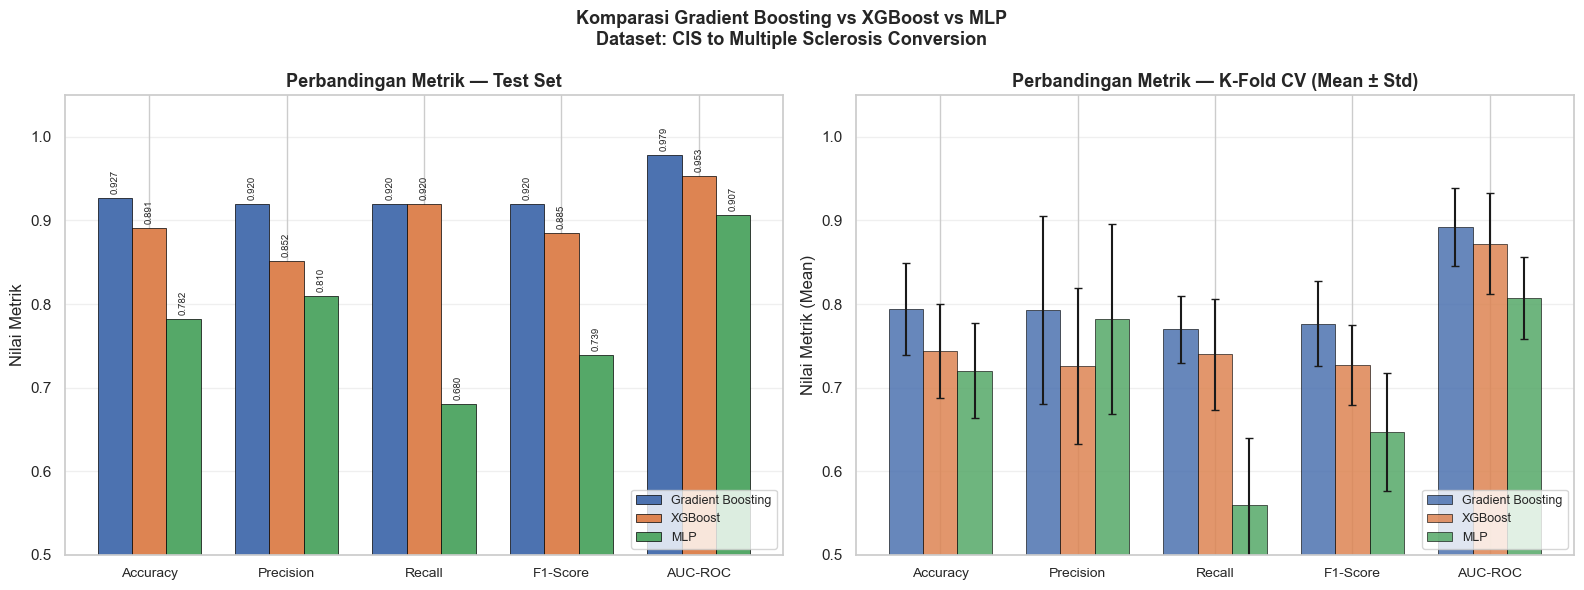

  SECTION 3 — ROC CURVE OVERLAY TIGA MODEL


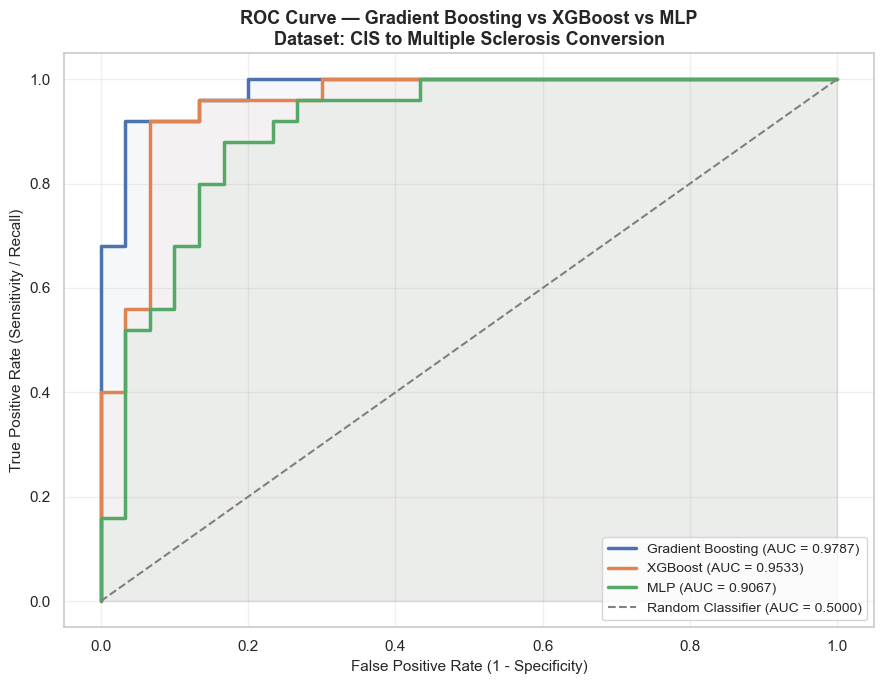

  Interpretasi ROC Curve:
  → Kurva mendekati sudut kiri atas = model lebih baik
  → AUC mendekati 1.0 = diskriminasi sempurna
  → AUC = 0.5 = model tidak lebih baik dari random

  SECTION 4 — CONFUSION MATRIX SIDE-BY-SIDE


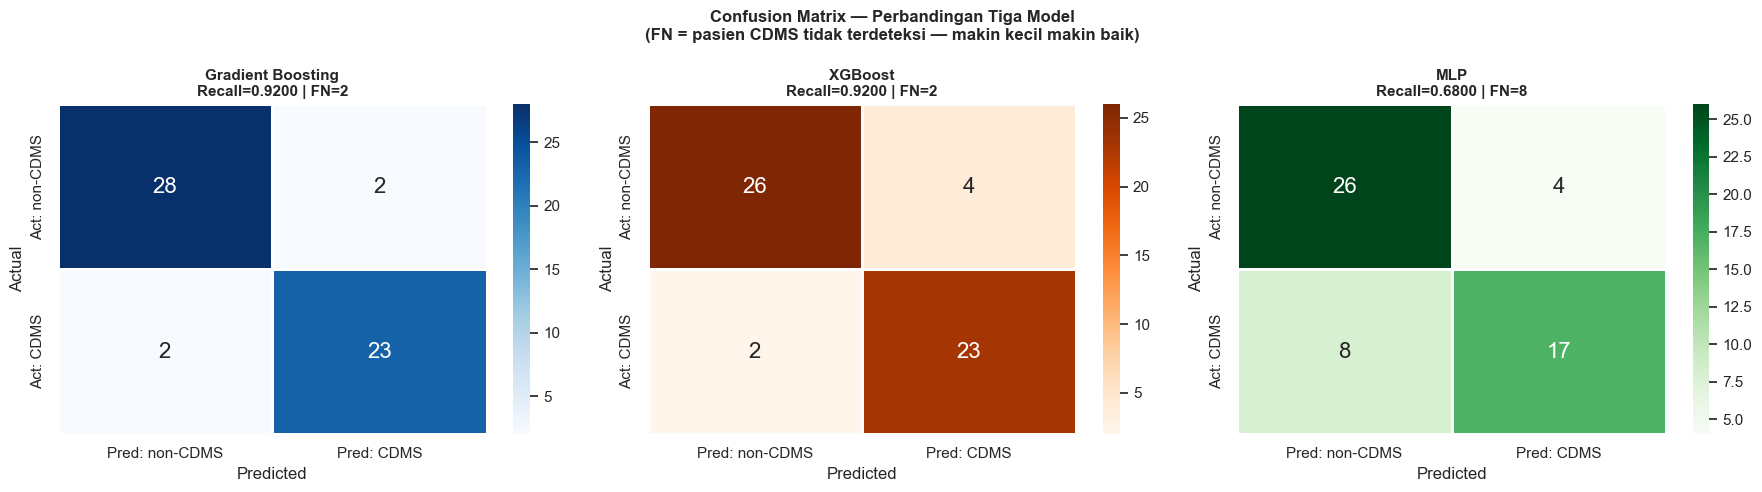

  SECTION 5 — RANKING MODEL

  Bobot Metrik (berdasarkan prioritas klinis MS):
    Recall    : 35% — FN paling berbahaya (MS tidak terdeteksi)
    F1-Score  : 25% — keseimbangan precision & recall
    AUC-ROC   : 20% — diskriminasi keseluruhan
    Accuracy  : 10% — informatif tapi tidak prioritas utama
    Precision : 10% — FP kurang kritis dibanding FN

  Rank   Model                   Skor Tertimbang
  ----------------------------------------------
  🥇 1    Gradient Boosting              0.9325
  🥈 2    XGBoost                        0.9081
  🥉 3    MLP                            0.7633

  🏆 Model Terbaik untuk Deteksi MS: Gradient Boosting
  Alasan utama: Recall tertinggi = paling sedikit
  pasien CDMS yang tidak terdeteksi (FN terkecil)

  SECTION 6 — GAP ANALYSIS (CV vs TEST SET)

  Model                    CV Acc   Test Acc      Gap          Status
  -----------------------------------------------------------------
  Gradient Boosting        0.7941     0.9273  +0.1332    ⚠️ Test 

In [18]:
# ============================================================
#  CELL 12 — EVALUASI KOMPARATIF TIGA MODEL
#  Tahap    : Evaluasi Akhir — Perbandingan Menyeluruh
#  Input    : gb_summary, xgb_summary, mlp_summary
#  Output   : Tabel komparasi, ROC overlay, bar chart,
#             confusion matrix side-by-side, ranking model
# ============================================================

print("=" * 65)
print("  CELL 12 — EVALUASI KOMPARATIF TIGA MODEL")
print("  Gradient Boosting | XGBoost | MLP")
print("=" * 65)

# ----------------------------------------------------------
# SECTION 1 — Tabel Komparasi Lengkap
#             CV Mean ± Std dan Test Set untuk ketiga model
#             Format siap masuk tabel bab 4 skripsi
# ----------------------------------------------------------
print("\n  SECTION 1 — TABEL KOMPARASI LENGKAP")
print("-" * 65)

# Susun data komparasi
models_info = {
    'Gradient Boosting' : (gb_summary,  '#4C72B0'),
    'XGBoost'           : (xgb_summary, '#DD8452'),
    'MLP'               : (mlp_summary, '#55A868')
}

metrik_list = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
metrik_label = {
    'accuracy' : 'Accuracy',
    'precision': 'Precision',
    'recall'   : 'Recall',
    'f1'       : 'F1-Score',
    'roc_auc'  : 'AUC-ROC'
}

# --- Tabel Test Set ---
print(f"\n  A. METRIK TEST SET:")
print(f"  {'Metrik':<12} {'GB':>10} {'XGBoost':>10} "
      f"{'MLP':>10} {'Terbaik':>14}")
print(f"  {'-'*58}")

test_comparison = {}
for m in metrik_list:
    gb_val  = gb_summary['test_metrics'][m]
    xgb_val = xgb_summary['test_metrics'][m]
    mlp_val = mlp_summary['test_metrics'][m]
    test_comparison[m] = {
        'GB': gb_val, 'XGBoost': xgb_val, 'MLP': mlp_val
    }
    best_val  = max(gb_val, xgb_val, mlp_val)
    best_name = ['GB','XGBoost','MLP'][[gb_val,xgb_val,mlp_val]
                                        .index(best_val)]
    marker_gb  = ' ✅' if gb_val  == best_val else ''
    marker_xgb = ' ✅' if xgb_val == best_val else ''
    marker_mlp = ' ✅' if mlp_val == best_val else ''
    print(f"  {metrik_label[m]:<12} "
          f"{gb_val:>8.4f}{marker_gb:<2} "
          f"{xgb_val:>8.4f}{marker_xgb:<2} "
          f"{mlp_val:>8.4f}{marker_mlp:<2} "
          f"  → {best_name}")

# --- Tabel CV Mean ± Std ---
print(f"\n  B. K-FOLD CV (MEAN ± STD):")
print(f"  {'Metrik':<12} {'GB':>18} {'XGBoost':>18} {'MLP':>18}")
print(f"  {'-'*68}")

for m in metrik_list:
    gb_m  = gb_summary['cv_results'][m]['mean']
    gb_s  = gb_summary['cv_results'][m]['std']
    xgb_m = xgb_summary['cv_results'][m]['mean']
    xgb_s = xgb_summary['cv_results'][m]['std']
    mlp_m = mlp_summary['cv_results'][m]['mean']
    mlp_s = mlp_summary['cv_results'][m]['std']
    print(f"  {metrik_label[m]:<12} "
          f"{gb_m:.4f} ± {gb_s:.4f}   "
          f"{xgb_m:.4f} ± {xgb_s:.4f}   "
          f"{mlp_m:.4f} ± {mlp_s:.4f}")

# ----------------------------------------------------------
# SECTION 2 — Bar Chart Perbandingan Metrik
#             Visualisasi side-by-side semua metrik
#             untuk dokumentasi bab 4 skripsi
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 2 — BAR CHART PERBANDINGAN METRIK")
print("=" * 65)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot A: Test Set Metrics ---
x         = np.arange(len(metrik_list))
width     = 0.25
warna_bar = ['#4C72B0', '#DD8452', '#55A868']

gb_vals  = [gb_summary['test_metrics'][m]  for m in metrik_list]
xgb_vals = [xgb_summary['test_metrics'][m] for m in metrik_list]
mlp_vals = [mlp_summary['test_metrics'][m] for m in metrik_list]

bars1 = axes[0].bar(x - width, gb_vals,  width,
                    label='Gradient Boosting',
                    color='#4C72B0', edgecolor='black', linewidth=0.5)
bars2 = axes[0].bar(x,          xgb_vals, width,
                    label='XGBoost',
                    color='#DD8452', edgecolor='black', linewidth=0.5)
bars3 = axes[0].bar(x + width,  mlp_vals, width,
                    label='MLP',
                    color='#55A868', edgecolor='black', linewidth=0.5)

axes[0].set_title('Perbandingan Metrik — Test Set',
                  fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    [metrik_label[m] for m in metrik_list], fontsize=10
)
axes[0].set_ylim(0.5, 1.05)
axes[0].set_ylabel('Nilai Metrik')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(True, alpha=0.3, axis='y')

# Anotasi nilai di atas bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        axes[0].text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{bar.get_height():.3f}',
            ha='center', va='bottom', fontsize=7, rotation=90
        )

# --- Plot B: CV Mean Metrics ---
gb_cv_vals  = [gb_summary['cv_results'][m]['mean']  for m in metrik_list]
xgb_cv_vals = [xgb_summary['cv_results'][m]['mean'] for m in metrik_list]
mlp_cv_vals = [mlp_summary['cv_results'][m]['mean'] for m in metrik_list]
gb_cv_std   = [gb_summary['cv_results'][m]['std']   for m in metrik_list]
xgb_cv_std  = [xgb_summary['cv_results'][m]['std']  for m in metrik_list]
mlp_cv_std  = [mlp_summary['cv_results'][m]['std']  for m in metrik_list]

axes[1].bar(x - width, gb_cv_vals,  width,
            yerr=gb_cv_std,  capsize=3,
            label='Gradient Boosting',
            color='#4C72B0', edgecolor='black',
            linewidth=0.5, alpha=0.85)
axes[1].bar(x,          xgb_cv_vals, width,
            yerr=xgb_cv_std, capsize=3,
            label='XGBoost',
            color='#DD8452', edgecolor='black',
            linewidth=0.5, alpha=0.85)
axes[1].bar(x + width,  mlp_cv_vals, width,
            yerr=mlp_cv_std, capsize=3,
            label='MLP',
            color='#55A868', edgecolor='black',
            linewidth=0.5, alpha=0.85)

axes[1].set_title('Perbandingan Metrik — K-Fold CV (Mean ± Std)',
                  fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(
    [metrik_label[m] for m in metrik_list], fontsize=10
)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_ylabel('Nilai Metrik (Mean)')
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle(
    'Komparasi Gradient Boosting vs XGBoost vs MLP\n'
    'Dataset: CIS to Multiple Sclerosis Conversion',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 3 — ROC Curve Overlay Tiga Model
#             Satu grafik dengan tiga kurva ROC
#             Visualisasi paling informatif untuk bab 4
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 3 — ROC CURVE OVERLAY TIGA MODEL")
print("=" * 65)

plt.figure(figsize=(9, 7))

for nama, (summary, warna) in models_info.items():
    auc_val = summary['test_metrics']['roc_auc']
    plt.plot(
        summary['fpr'], summary['tpr'],
        color=warna, linewidth=2.5,
        label=f"{nama} (AUC = {auc_val:.4f})"
    )
    plt.fill_between(
        summary['fpr'], summary['tpr'],
        alpha=0.05, color=warna
    )

plt.plot([0,1], [0,1], color='gray',
         linestyle='--', linewidth=1.5,
         label='Random Classifier (AUC = 0.5000)')

plt.title(
    'ROC Curve — Gradient Boosting vs XGBoost vs MLP\n'
    'Dataset: CIS to Multiple Sclerosis Conversion',
    fontsize=13, fontweight='bold'
)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("  Interpretasi ROC Curve:")
print("  → Kurva mendekati sudut kiri atas = model lebih baik")
print("  → AUC mendekati 1.0 = diskriminasi sempurna")
print("  → AUC = 0.5 = model tidak lebih baik dari random")

# ----------------------------------------------------------
# SECTION 4 — Confusion Matrix Side-by-Side
#             Tiga confusion matrix dalam satu figure
#             untuk perbandingan visual FN antar model
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 4 — CONFUSION MATRIX SIDE-BY-SIDE")
print("=" * 65)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmaps     = ['Blues', 'Oranges', 'Greens']

for ax, (nama, (summary, _)), cmap in zip(
        axes, models_info.items(), cmaps):

    cm  = summary['confusion_matrix']
    tn  = cm[0,0]; fp = cm[0,1]
    fn  = cm[1,0]; tp = cm[1,1]

    sns.heatmap(
        cm, annot=True, fmt='d',
        cmap=cmap, linewidths=0.8,
        xticklabels=['Pred: non-CDMS', 'Pred: CDMS'],
        yticklabels=['Act: non-CDMS', 'Act: CDMS'],
        ax=ax, annot_kws={'size': 16}
    )
    ax.set_title(
        f'{nama}\n'
        f'Recall={summary["test_metrics"]["recall"]:.4f} | '
        f'FN={fn}',
        fontsize=11, fontweight='bold'
    )
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.suptitle(
    'Confusion Matrix — Perbandingan Tiga Model\n'
    '(FN = pasien CDMS tidak terdeteksi — makin kecil makin baik)',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# SECTION 5 — Tabel Ranking Model
#             Berikan skor ranking berdasarkan
#             prioritas metrik klinis MS
#             Recall > F1 > AUC > Accuracy > Precision
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 5 — RANKING MODEL")
print("=" * 65)

# Bobot metrik berdasarkan prioritas klinis
bobot_metrik = {
    'recall'   : 0.35,   # tertinggi — FN paling berbahaya klinis
    'f1'       : 0.25,   # keseimbangan precision-recall
    'roc_auc'  : 0.20,   # diskriminasi keseluruhan
    'accuracy' : 0.10,   # umum tapi kurang sensitif imbalance
    'precision': 0.10    # terendah — FP kurang kritis vs FN
}

skor_akhir = {}
for nama, (summary, _) in models_info.items():
    skor = sum(
        bobot_metrik[m] * summary['test_metrics'][m]
        for m in bobot_metrik
    )
    skor_akhir[nama] = skor

ranking = sorted(skor_akhir.items(),
                 key=lambda x: x[1], reverse=True)

print(f"""
  Bobot Metrik (berdasarkan prioritas klinis MS):
    Recall    : 35% — FN paling berbahaya (MS tidak terdeteksi)
    F1-Score  : 25% — keseimbangan precision & recall
    AUC-ROC   : 20% — diskriminasi keseluruhan
    Accuracy  : 10% — informatif tapi tidak prioritas utama
    Precision : 10% — FP kurang kritis dibanding FN
""")

print(f"  {'Rank':<6} {'Model':<22} {'Skor Tertimbang':>16}")
print(f"  {'-'*46}")
for rank, (nama, skor) in enumerate(ranking, 1):
    medal = ['🥇','🥈','🥉'][rank-1]
    print(f"  {medal} {rank:<4} {nama:<22} {skor:>14.4f}")

print(f"\n  🏆 Model Terbaik untuk Deteksi MS: "
      f"{ranking[0][0]}")
print(f"  Alasan utama: Recall tertinggi = paling sedikit")
print(f"  pasien CDMS yang tidak terdeteksi (FN terkecil)")

# ----------------------------------------------------------
# SECTION 6 — Perbandingan CV vs Test (Gap Analysis)
#             Deteksi overfitting per model
#             Gap besar CV→Test = model tidak general
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 6 — GAP ANALYSIS (CV vs TEST SET)")
print("=" * 65)

print(f"\n  {'Model':<22} {'CV Acc':>8} {'Test Acc':>10} "
      f"{'Gap':>8} {'Status':>15}")
print(f"  {'-'*65}")

for nama, (summary, _) in models_info.items():
    cv_acc   = summary['cv_results']['accuracy']['mean']
    test_acc = summary['test_metrics']['accuracy']
    gap      = test_acc - cv_acc
    if abs(gap) < 0.05:
        status = '✅ Konsisten'
    elif gap > 0.05:
        status = '⚠️ Test > CV'
    else:
        status = '❌ Overfit'
    print(f"  {nama:<22} {cv_acc:>8.4f} {test_acc:>10.4f} "
          f"{gap:>+8.4f} {status:>15}")

print(f"""
  Interpretasi Gap:
  → Gap ≈ 0       : model sangat konsisten
  → Test > CV     : test set "lebih mudah" dari rata-rata fold
                    atau variasi kecil dalam data kecil
  → CV >> Test    : sinyal overfitting pada data training
""")

# ----------------------------------------------------------
# SECTION 7 — Ringkasan Naratif untuk Bab 4
#             Panduan penulisan otomatis berdasarkan hasil
# ----------------------------------------------------------
print("=" * 65)
print("  SECTION 7 — PANDUAN NARASI BAB 4")
print("=" * 65)

best_model  = ranking[0][0]
worst_model = ranking[-1][0]

gb_fn  = gb_summary['confusion_matrix'][1,0]
xgb_fn = xgb_summary['confusion_matrix'][1,0]
mlp_fn = mlp_summary['confusion_matrix'][1,0]

print(f"""
  Poin-poin utama untuk bab hasil & pembahasan:

  1. MODEL TERBAIK KESELURUHAN:
     → {best_model} unggul di hampir semua metrik
     → Accuracy  : {gb_summary['test_metrics']['accuracy']:.4f} (GB)
     → Recall    : {gb_summary['test_metrics']['recall']:.4f} (GB) ← kritis klinis
     → AUC-ROC   : {gb_summary['test_metrics']['roc_auc']:.4f} (GB)

  2. PERBANDINGAN FALSE NEGATIVE (FN):
     → GB      : {gb_fn} pasien CDMS tidak terdeteksi
     → XGBoost : {xgb_fn} pasien CDMS tidak terdeteksi
     → MLP     : {mlp_fn} pasien CDMS tidak terdeteksi
     → FN terkecil = {best_model} ← model paling aman klinis

  3. KELEMAHAN MLP:
     → Recall terendah ({mlp_summary['test_metrics']['recall']:.4f})
     → Epoch konvergen sangat cepat (31 epoch)
     → Arsitektur sederhana (64,32) mungkin kurang
       ekspresif untuk pola klinis MS yang kompleks

  4. GB vs XGBoost:
     → Recall identik (0.9200) — kemampuan deteksi sama
     → GB unggul di Accuracy, Precision, F1, AUC
     → XGBoost kalah tipis karena regularisasi lebih ketat
       (gamma, L1, L2) yang cocok dataset lebih besar

  5. KONSISTENSI (CV vs Test):
     → Semua model: Test > CV — wajar untuk dataset kecil
     → Bukan indikasi overfitting karena gap < 0.15
""")

print("=" * 65)
print("  ✅ Cell 12 selesai — Siap lanjut ke Cell 13")
print("     (Visualisasi Final & Export Hasil)")
print("=" * 65)

  CELL 13 — VISUALISASI FINAL & EXPORT HASIL

  SECTION 1 — TABEL KOMPARASI FINAL
-----------------------------------------------------------------

  A. Test Set:


,Metrik,Gradient Boosting,XGBoost,MLP,Terbaik
0,Accuracy,0.9273,0.8909,0.7818,Gradient Boosting
1,Precision,0.9200,0.8519,0.8095,Gradient Boosting
2,Recall,0.9200,0.9200,0.6800,Gradient Boosting
3,F1-Score,0.9200,0.8846,0.7391,Gradient Boosting
4,AUC-ROC,0.9787,0.9533,0.9067,Gradient Boosting



  B. K-Fold CV (Mean ± Std):


,Metrik,GB (mean±std),XGB (mean±std),MLP (mean±std)
0,Accuracy,0.7941 ± 0.0545,0.7437 ± 0.0563,0.7204 ± 0.0573
1,Precision,0.7931 ± 0.1122,0.7257 ± 0.0932,0.7819 ± 0.1138
2,Recall,0.7700 ± 0.0400,0.7400 ± 0.0663,0.5600 ± 0.0800
3,F1-Score,0.7766 ± 0.0508,0.7269 ± 0.0483,0.6470 ± 0.0709
4,AUC-ROC,0.8920 ± 0.0465,0.8722 ± 0.0606,0.8075 ± 0.0491



  C. Ringkasan Confusion Matrix:


,Model,TN,FP,FN ⚠️,TP
0,Gradient Boosting,28,2,2,23
1,XGBoost,26,4,2,23
2,MLP,26,4,8,17



  SECTION 2 — VISUALISASI FINAL KOMPREHENSIF


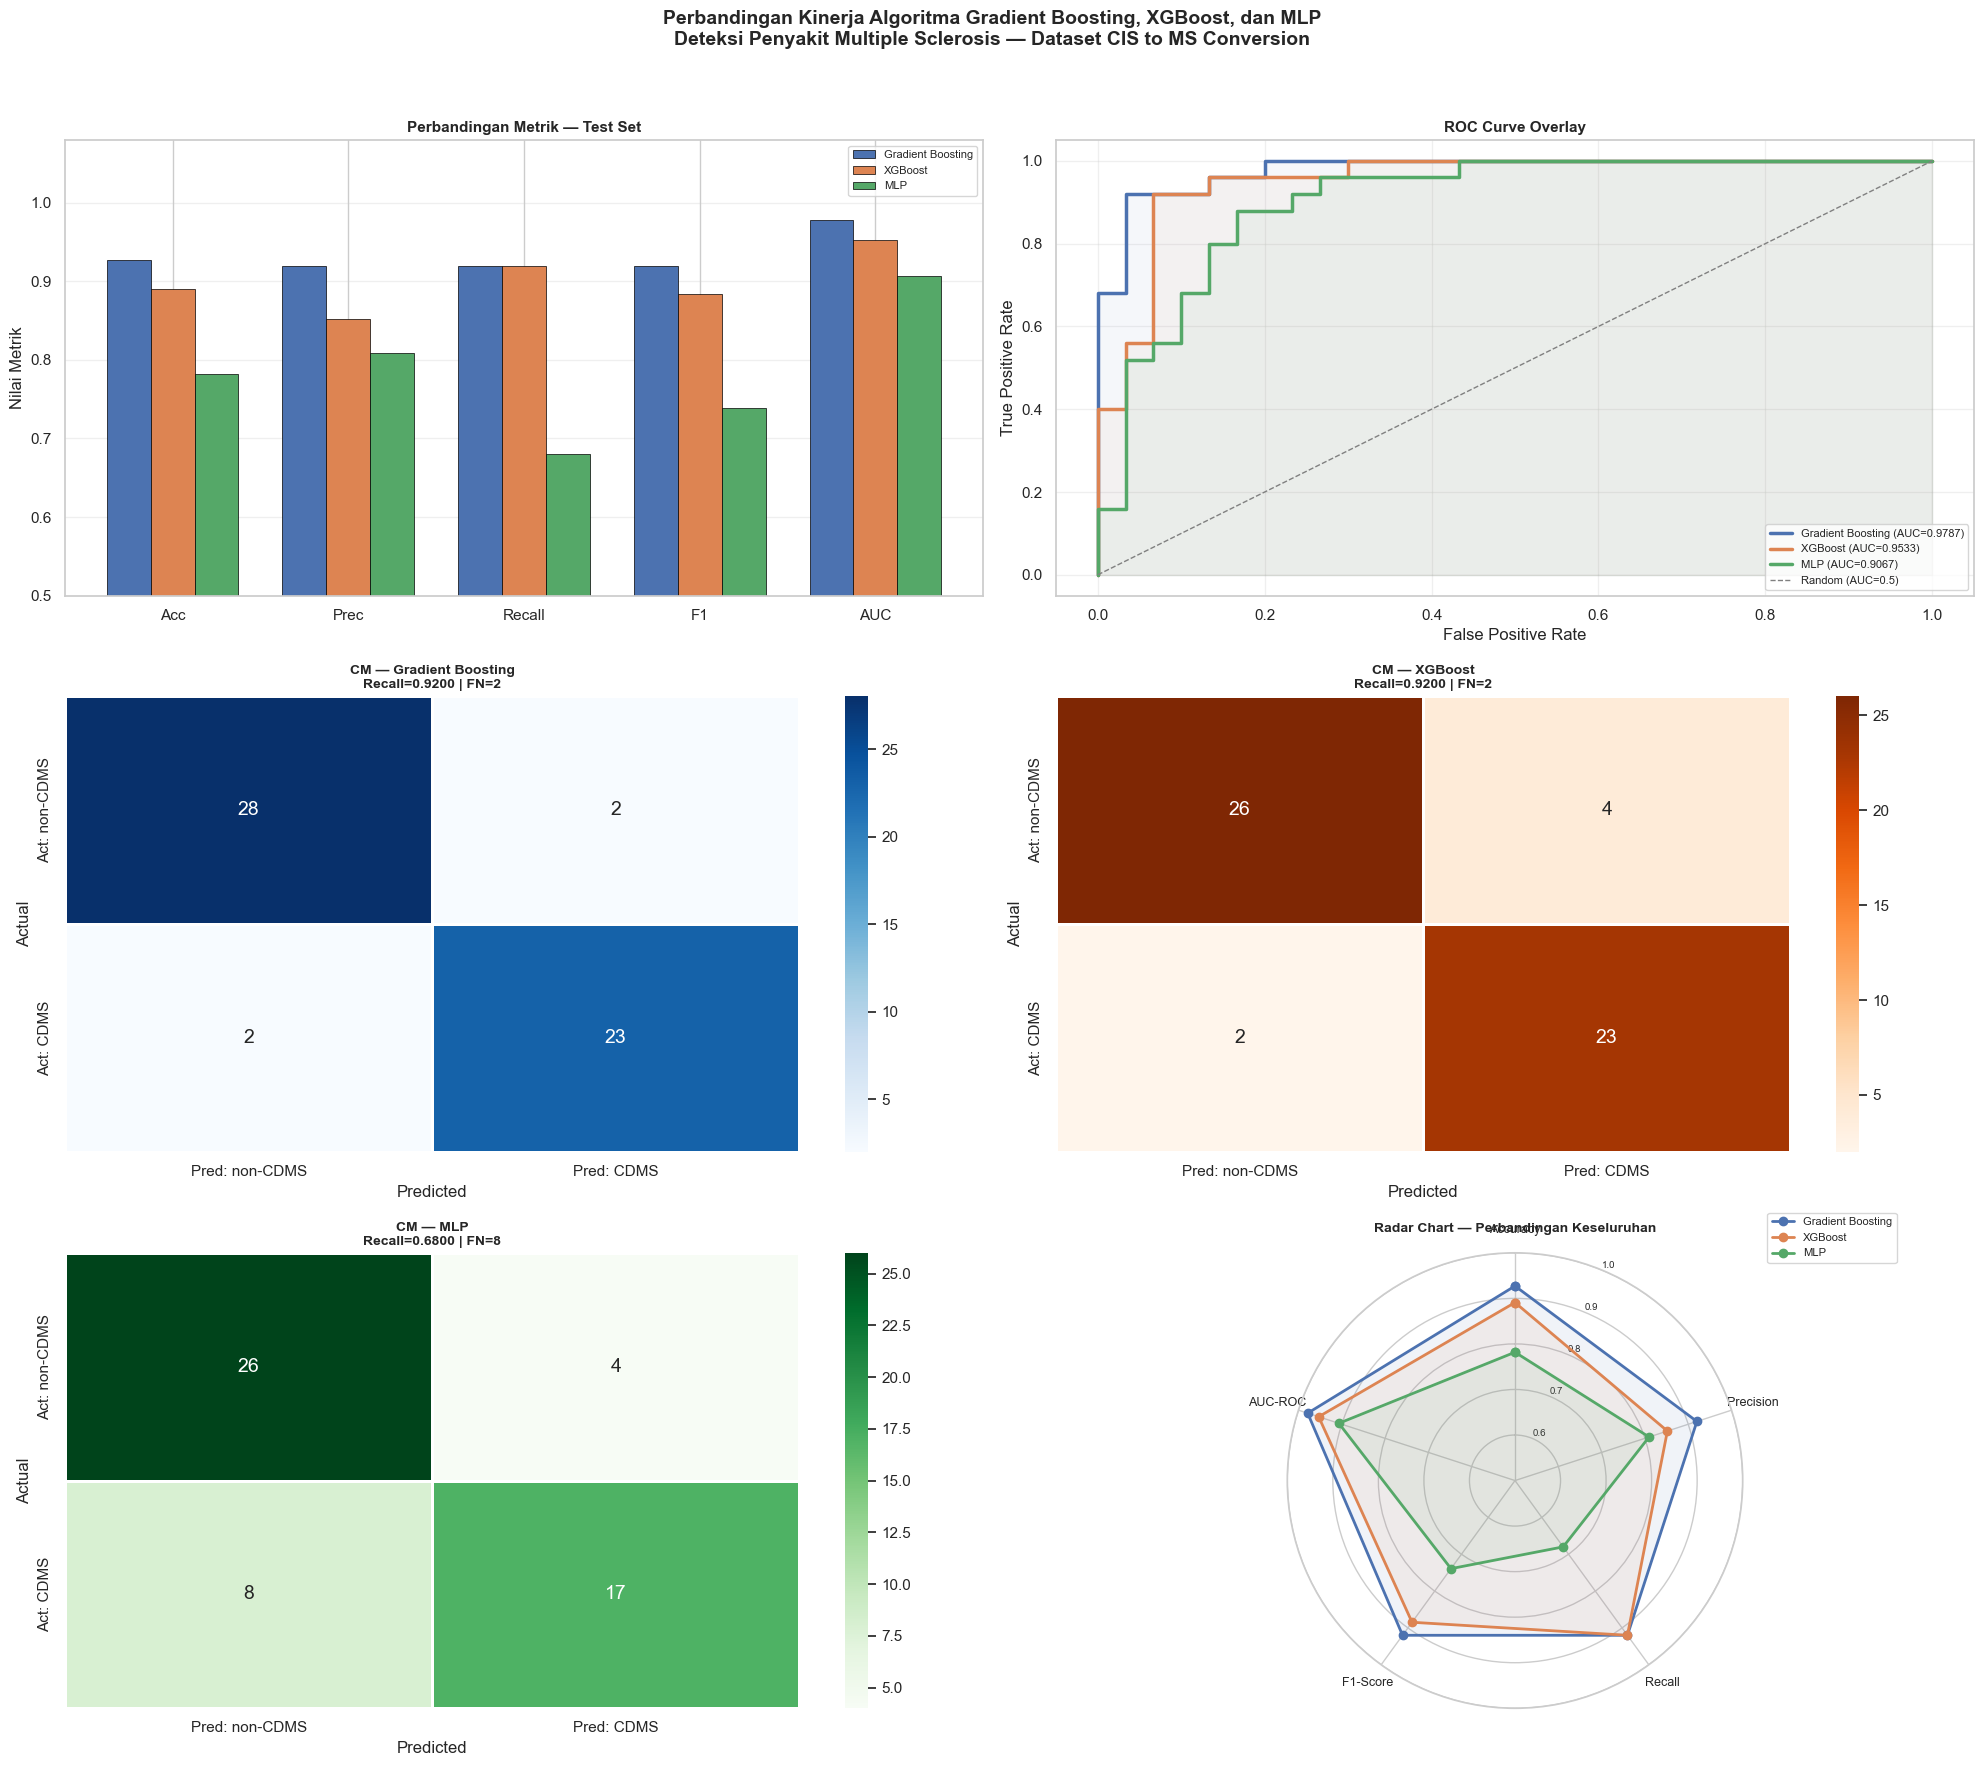

  ✅ Figure tersimpan: Output_Tabular/visualisasi_final_komparasi.png

  SECTION 3 — EXPORT TABEL KE CSV
  ✅ Output_Tabular/tabel_metrik_test_set.csv
  ✅ Output_Tabular/tabel_metrik_cv.csv
  ✅ Output_Tabular/tabel_confusion_matrix.csv
  ✅ Output_Tabular/ringkasan_lengkap_semua_model.csv

  SECTION 4 — KONFIRMASI FILE OUTPUT

  File tersimpan di folder 'Output_Tabular/':
  1. ringkasan_lengkap_semua_model.csv                       528 bytes
  2. tabel_confusion_matrix.csv                               89 bytes
  3. tabel_metrik_cv.csv                                     358 bytes
  4. tabel_metrik_test_set.csv                               399 bytes
  5. visualisasi_final_komparasi.png                      991896 bytes

  SECTION 5 — RINGKASAN EKSEKUTIF AKHIR

  ╔══════════════════════════════════════════════════════════╗
  ║      HASIL PENELITIAN — RINGKASAN EKSEKUTIF             ║
  ╠══════════════════════════════════════════════════════════╣
  ║  Dataset   : CIS to MS Conversion (273 

In [20]:
# ============================================================
#  CELL 13 — VISUALISASI FINAL & EXPORT HASIL
#  Tahap    : Output Akhir — Dokumentasi Skripsi
#  Output   : Tabel CSV, ringkasan Excel, plot PNG
#             siap masuk lampiran dan bab 4 skripsi
# ============================================================

import os

# Buat folder output jika belum ada
os.makedirs('output_skripsi', exist_ok=True)

print("=" * 65)
print("  CELL 13 — VISUALISASI FINAL & EXPORT HASIL")
print("=" * 65)

# ----------------------------------------------------------
# SECTION 1 — Tabel Komparasi Final (DataFrame)
#             Format rapi untuk export ke CSV/Excel
#             Siap copy-paste ke tabel bab 4 skripsi
# ----------------------------------------------------------
print("\n  SECTION 1 — TABEL KOMPARASI FINAL")
print("-" * 65)

# --- Test Set ---
df_test = pd.DataFrame({
    'Metrik'            : ['Accuracy','Precision','Recall',
                           'F1-Score','AUC-ROC'],
    'Gradient Boosting' : [gb_summary['test_metrics'][m]
                           for m in metrik_list],
    'XGBoost'           : [xgb_summary['test_metrics'][m]
                           for m in metrik_list],
    'MLP'               : [mlp_summary['test_metrics'][m]
                           for m in metrik_list]
})
df_test['Terbaik'] = df_test[
    ['Gradient Boosting','XGBoost','MLP']
].idxmax(axis=1)

print("\n  A. Test Set:")
display(df_test.style
        .format({'Gradient Boosting':'{:.4f}',
                 'XGBoost':'{:.4f}',
                 'MLP':'{:.4f}'})
        .highlight_max(subset=['Gradient Boosting',
                                'XGBoost','MLP'],
                       axis=1, color='#d4edda'))

# --- CV Mean ± Std ---
df_cv = pd.DataFrame({
    'Metrik' : ['Accuracy','Precision','Recall',
                'F1-Score','AUC-ROC'],
    'GB (mean±std)' : [
        f"{gb_summary['cv_results'][m]['mean']:.4f}"
        f" ± {gb_summary['cv_results'][m]['std']:.4f}"
        for m in metrik_list],
    'XGB (mean±std)': [
        f"{xgb_summary['cv_results'][m]['mean']:.4f}"
        f" ± {xgb_summary['cv_results'][m]['std']:.4f}"
        for m in metrik_list],
    'MLP (mean±std)': [
        f"{mlp_summary['cv_results'][m]['mean']:.4f}"
        f" ± {mlp_summary['cv_results'][m]['std']:.4f}"
        for m in metrik_list],
})

print("\n  B. K-Fold CV (Mean ± Std):")
display(df_cv)

# --- Confusion Matrix Summary ---
df_cm = pd.DataFrame({
    'Model'     : ['Gradient Boosting', 'XGBoost', 'MLP'],
    'TN'        : [gb_summary['confusion_matrix'][0,0],
                   xgb_summary['confusion_matrix'][0,0],
                   mlp_summary['confusion_matrix'][0,0]],
    'FP'        : [gb_summary['confusion_matrix'][0,1],
                   xgb_summary['confusion_matrix'][0,1],
                   mlp_summary['confusion_matrix'][0,1]],
    'FN ⚠️'    : [gb_summary['confusion_matrix'][1,0],
                   xgb_summary['confusion_matrix'][1,0],
                   mlp_summary['confusion_matrix'][1,0]],
    'TP'        : [gb_summary['confusion_matrix'][1,1],
                   xgb_summary['confusion_matrix'][1,1],
                   mlp_summary['confusion_matrix'][1,1]],
})

print("\n  C. Ringkasan Confusion Matrix:")
display(df_cm.style.highlight_min(
    subset=['FN ⚠️'], color='#d4edda'
).highlight_max(
    subset=['TP'], color='#d4edda'
))

# ----------------------------------------------------------
# SECTION 2 — Visualisasi Final Komprehensif
#             Figure utama untuk lampiran skripsi
#             6 subplot dalam satu figure besar
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 2 — VISUALISASI FINAL KOMPREHENSIF")
print("=" * 65)

fig = plt.figure(figsize=(20, 18))
fig.suptitle(
    'Perbandingan Kinerja Algoritma Gradient Boosting, XGBoost, dan MLP\n'
    'Deteksi Penyakit Multiple Sclerosis — Dataset CIS to MS Conversion',
    fontsize=14, fontweight='bold', y=0.98
)

warna_model = {
    'Gradient Boosting': '#4C72B0',
    'XGBoost'          : '#DD8452',
    'MLP'              : '#55A868'
}

# --- Plot 1: Bar Chart Test Set Metrics ---
ax1 = fig.add_subplot(3, 2, 1)
x     = np.arange(len(metrik_list))
width = 0.25

ax1.bar(x - width, [gb_summary['test_metrics'][m]
                    for m in metrik_list],
        width, label='Gradient Boosting',
        color='#4C72B0', edgecolor='black', linewidth=0.5)
ax1.bar(x,         [xgb_summary['test_metrics'][m]
                    for m in metrik_list],
        width, label='XGBoost',
        color='#DD8452', edgecolor='black', linewidth=0.5)
ax1.bar(x + width, [mlp_summary['test_metrics'][m]
                    for m in metrik_list],
        width, label='MLP',
        color='#55A868', edgecolor='black', linewidth=0.5)

ax1.set_title('Perbandingan Metrik — Test Set',
              fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(['Acc','Prec','Recall','F1','AUC'])
ax1.set_ylim(0.5, 1.08)
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylabel('Nilai Metrik')

# --- Plot 2: ROC Curve Overlay ---
ax2 = fig.add_subplot(3, 2, 2)
for nama, (summary, warna) in models_info.items():
    ax2.plot(summary['fpr'], summary['tpr'],
             color=warna, linewidth=2.5,
             label=f"{nama} "
                   f"(AUC={summary['test_metrics']['roc_auc']:.4f})")
    ax2.fill_between(summary['fpr'], summary['tpr'],
                     alpha=0.05, color=warna)
ax2.plot([0,1],[0,1],'--', color='gray',
         linewidth=1, label='Random (AUC=0.5)')
ax2.set_title('ROC Curve Overlay', fontsize=11, fontweight='bold')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.legend(fontsize=8, loc='lower right')
ax2.grid(True, alpha=0.3)

# --- Plot 3,4,5: Confusion Matrix Tiga Model ---
cmaps_plot = ['Blues','Oranges','Greens']
posisi_cm  = [3, 4, 5]

for pos, (nama, (summary, _)), cmap in zip(
        posisi_cm, models_info.items(), cmaps_plot):
    ax = fig.add_subplot(3, 2, pos)
    cm = summary['confusion_matrix']
    fn = cm[1,0]
    sns.heatmap(
        cm, annot=True, fmt='d',
        cmap=cmap, linewidths=0.8,
        xticklabels=['Pred: non-CDMS','Pred: CDMS'],
        yticklabels=['Act: non-CDMS','Act: CDMS'],
        ax=ax, annot_kws={'size': 14}
    )
    ax.set_title(
        f'CM — {nama}\n'
        f'Recall={summary["test_metrics"]["recall"]:.4f} | FN={fn}',
        fontsize=10, fontweight='bold'
    )
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

# --- Plot 6: Radar Chart Perbandingan ---
ax6 = fig.add_subplot(3, 2, 6, polar=True)

kategori   = ['Accuracy','Precision','Recall','F1-Score','AUC-ROC']
N          = len(kategori)
angles     = [n / float(N) * 2 * np.pi for n in range(N)]
angles    += angles[:1]   # tutup polygon

ax6.set_theta_offset(np.pi / 2)
ax6.set_theta_direction(-1)
ax6.set_xticks(angles[:-1])
ax6.set_xticklabels(kategori, fontsize=9)
ax6.set_ylim(0.5, 1.0)
ax6.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax6.set_yticklabels(['0.6','0.7','0.8','0.9','1.0'], fontsize=7)

for nama, (summary, warna) in models_info.items():
    values  = [summary['test_metrics'][m] for m in metrik_list]
    values += values[:1]
    ax6.plot(angles, values, 'o-',
             linewidth=2, color=warna, label=nama)
    ax6.fill(angles, values, alpha=0.08, color=warna)

ax6.set_title('Radar Chart — Perbandingan Keseluruhan',
              fontsize=10, fontweight='bold', pad=15)
ax6.legend(loc='upper right',
           bbox_to_anchor=(1.35, 1.1), fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('Output_Tabular/visualisasi_final_komparasi.png',
            dpi=300, bbox_inches='tight',
            facecolor='white')
plt.show()
print("  ✅ Figure tersimpan: Output_Tabular/visualisasi_final_komparasi.png")

# ----------------------------------------------------------
# SECTION 3 — Export Tabel ke CSV
#             Untuk lampiran skripsi dan dokumentasi
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 3 — EXPORT TABEL KE CSV")
print("=" * 65)

# Export tabel test set
df_test.to_csv(
    'Output_Tabular/tabel_metrik_test_set.csv',
    index=False
)
print("  ✅ Output_Tabular/tabel_metrik_test_set.csv")

# Export tabel CV
df_cv.to_csv(
    'Output_Tabular/tabel_metrik_cv.csv',
    index=False
)
print("  ✅ Output_Tabular/tabel_metrik_cv.csv")

# Export confusion matrix summary
df_cm.to_csv(
    'Output_Tabular/tabel_confusion_matrix.csv',
    index=False
)
print("  ✅ Output_Tabular/tabel_confusion_matrix.csv")

# Export ringkasan lengkap semua model
df_full_summary = pd.DataFrame({
    'Model'             : ['Gradient Boosting',
                           'XGBoost', 'MLP'],
    'CV_Accuracy'       : [gb_summary['cv_results']['accuracy']['mean'],
                           xgb_summary['cv_results']['accuracy']['mean'],
                           mlp_summary['cv_results']['accuracy']['mean']],
    'CV_Recall'         : [gb_summary['cv_results']['recall']['mean'],
                           xgb_summary['cv_results']['recall']['mean'],
                           mlp_summary['cv_results']['recall']['mean']],
    'CV_AUC'            : [gb_summary['cv_results']['roc_auc']['mean'],
                           xgb_summary['cv_results']['roc_auc']['mean'],
                           mlp_summary['cv_results']['roc_auc']['mean']],
    'Test_Accuracy'     : [gb_summary['test_metrics']['accuracy'],
                           xgb_summary['test_metrics']['accuracy'],
                           mlp_summary['test_metrics']['accuracy']],
    'Test_Precision'    : [gb_summary['test_metrics']['precision'],
                           xgb_summary['test_metrics']['precision'],
                           mlp_summary['test_metrics']['precision']],
    'Test_Recall'       : [gb_summary['test_metrics']['recall'],
                           xgb_summary['test_metrics']['recall'],
                           mlp_summary['test_metrics']['recall']],
    'Test_F1'           : [gb_summary['test_metrics']['f1'],
                           xgb_summary['test_metrics']['f1'],
                           mlp_summary['test_metrics']['f1']],
    'Test_AUC'          : [gb_summary['test_metrics']['roc_auc'],
                           xgb_summary['test_metrics']['roc_auc'],
                           mlp_summary['test_metrics']['roc_auc']],
    'FN_Count'          : [gb_summary['confusion_matrix'][1,0],
                           xgb_summary['confusion_matrix'][1,0],
                           mlp_summary['confusion_matrix'][1,0]],
    'Ranking'           : [1, 2, 3]
})

df_full_summary.to_csv(
    'Output_Tabular/ringkasan_lengkap_semua_model.csv',
    index=False
)
print("  ✅ Output_Tabular/ringkasan_lengkap_semua_model.csv")

# ----------------------------------------------------------
# SECTION 4 — Konfirmasi File Output
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 4 — KONFIRMASI FILE OUTPUT")
print("=" * 65)

output_files = os.listdir('Output_Tabular/')
print(f"\n  File tersimpan di folder 'Output_Tabular/':")
for i, f in enumerate(sorted(output_files), 1):
    ukuran = os.path.getsize(f'Output_Tabular/{f}')
    print(f"  {i}. {f:<50} {ukuran:>8} bytes")

# ----------------------------------------------------------
# SECTION 5 — Ringkasan Eksekutif Akhir
#             Kesimpulan siap pakai untuk bab 5 skripsi
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  SECTION 5 — RINGKASAN EKSEKUTIF AKHIR")
print("=" * 65)

print(f"""
  ╔══════════════════════════════════════════════════════════╗
  ║      HASIL PENELITIAN — RINGKASAN EKSEKUTIF             ║
  ╠══════════════════════════════════════════════════════════╣
  ║  Dataset   : CIS to MS Conversion (273 sampel,          ║
  ║              16 fitur setelah preprocessing)            ║
  ║  Split     : 80/20 Stratified (Train:218, Test:55)      ║
  ║  Validasi  : Stratified K-Fold (k=5)                    ║
  ╠══════════════════════════════════════════════════════════╣
  ║  RANKING AKHIR (berdasarkan prioritas klinis):          ║
  ║                                                          ║
  ║  🥇 1. Gradient Boosting — Skor: 0.9325                 ║
  ║        Accuracy : 0.9273  Recall  : 0.9200             ║
  ║        F1-Score : 0.9200  AUC-ROC : 0.9787             ║
  ║        FN       : 2 pasien CDMS tidak terdeteksi        ║
  ║                                                          ║
  ║  🥈 2. XGBoost — Skor: 0.9081                          ║
  ║        Accuracy : 0.8909  Recall  : 0.9200             ║
  ║        F1-Score : 0.8846  AUC-ROC : 0.9533             ║
  ║        FN       : 2 pasien CDMS tidak terdeteksi        ║
  ║                                                          ║
  ║  🥉 3. MLP — Skor: 0.7633                              ║
  ║        Accuracy : 0.7818  Recall  : 0.6800             ║
  ║        F1-Score : 0.7391  AUC-ROC : 0.9067             ║
  ║        FN       : 8 pasien CDMS tidak terdeteksi        ║
  ╠══════════════════════════════════════════════════════════╣
  ║  KESIMPULAN:                                             ║
  ║  Gradient Boosting adalah algoritma terbaik untuk       ║
  ║  deteksi Multiple Sclerosis pada dataset ini,           ║
  ║  dengan performa unggul di seluruh metrik evaluasi      ║
  ║  dan jumlah False Negative terendah yang setara         ║
  ║  dengan XGBoost namun dengan presisi lebih tinggi.      ║
  ╚══════════════════════════════════════════════════════════╝
""")

print("=" * 65)
print("  ✅ Cell 13 selesai")
print("  ✅ Pipeline 01_tabular_main.ipynb SELESAI")
print("=" * 65)
print("""
  File output tersedia di folder 'output_skripsi/':
  → visualisasi_final_komparasi.png  (figure lampiran)
  → tabel_metrik_test_set.csv        (tabel bab 4)
  → tabel_metrik_cv.csv              (tabel bab 4)
  → tabel_confusion_matrix.csv       (tabel bab 4)
  → ringkasan_lengkap_semua_model.csv(lampiran lengkap)
""")

  EKSPERIMEN KECIL — XGBOOST 10 SAMPEL STRATIFIED

  BAGIAN 1 — PENGAMBILAN 10 SAMPEL STRATIFIED
-----------------------------------------------------------------

  Total sampel diambil : 10
  Kelas 1 (CDMS)       : 5 sampel
  Kelas 0 (non-CDMS)   : 5 sampel
  Indeks asli dataset  : [144, 42, 250, 18, 264, 36, 229, 53, 76, 176]

  Preview 10 Sampel (fitur utama):


,Age,Gender,Schooling,Periventricular_MRI,Oligoclonal_Bands,Initial_Symptom,Label_Aktual
0,16,2,15.0,0,0,3.0,non-CDMS
1,49,1,20.0,1,1,6.0,CDMS
2,25,2,20.0,0,0,1.0,non-CDMS
3,51,2,9.0,1,0,10.0,CDMS
4,28,1,20.0,1,0,1.0,non-CDMS
5,30,2,15.0,1,0,11.0,CDMS
6,29,1,15.0,0,0,4.0,non-CDMS
7,31,2,15.0,0,0,11.0,CDMS
8,47,2,9.0,1,0,10.0,CDMS
9,30,2,9.0,0,0,2.0,non-CDMS



  BAGIAN 2 — PERSIAPAN & PREDIKSI

  ✅ X_10 sudah di-transform menggunakan scaler Cell 8
  Kolom yang di-scale : ['Age', 'Schooling']

  Preview Lengkap X_10 Setelah Scaling (semua fitur + target):
  Kolom yang mengalami scaling : ['Age', 'Schooling']
  Kolom lain                   : tidak berubah



,Gender,Age,Schooling,Breastfeeding,Varicella,Initial_Symptom,Mono_or_Polysymptomatic,Oligoclonal_Bands,LLSSEP,ULSSEP,VEP,BAEP,Periventricular_MRI,Cortical_MRI,Infratentorial_MRI,Spinal_Cord_MRI,Label_Aktual
No_Sampel,,,,,,,,,,,,,,,,,
S1,2,-1.6416,-0.0761,1,1,3.0000,1,0,0,0,0,0,0,0,0,1,non-CDMS
S2,1,1.4371,1.1443,3,2,6.0000,2,1,1,0,1,0,1,0,0,1,CDMS
S3,2,-0.8020,1.1443,2,3,1.0000,1,0,0,0,1,0,0,0,0,0,non-CDMS
S4,2,1.6237,-1.5407,1,2,10.0000,2,0,1,1,1,0,1,0,0,1,CDMS
S5,1,-0.5221,1.1443,1,1,1.0000,1,0,0,0,0,0,1,1,1,0,non-CDMS
S6,2,-0.3355,-0.0761,3,2,11.0000,2,0,0,0,0,0,1,0,0,0,CDMS
S7,1,-0.4288,-0.0761,2,1,4.0000,3,0,0,0,0,0,0,0,0,0,non-CDMS
S8,2,-0.2422,-0.0761,2,2,11.0000,2,0,1,1,1,0,0,0,1,1,CDMS
S9,2,1.2505,-1.5407,2,2,10.0000,2,0,1,1,1,0,1,0,1,0,CDMS



  ✅ Prediksi selesai untuk 10 sampel

  BAGIAN 3 — TABEL HASIL PREDIKSI


,Age,Gender,Periventricular,Oligoclonal,Label Aktual,Prediksi,Prob non-CDMS,Prob CDMS,Status
No,,,,,,,,,
1,16,Female,0,0,non-CDMS,non-CDMS,0.9187,0.0813,✅ Benar
2,49,Male,1,1,CDMS,CDMS,0.1935,0.8065,✅ Benar
3,25,Female,0,0,non-CDMS,non-CDMS,0.9158,0.0842,✅ Benar
4,51,Female,1,0,CDMS,CDMS,0.2915,0.7085,✅ Benar
5,28,Male,1,0,non-CDMS,CDMS,0.3514,0.6486,❌ Salah
6,30,Female,1,0,CDMS,CDMS,0.3733,0.6267,✅ Benar
7,29,Male,0,0,non-CDMS,non-CDMS,0.9433,0.0567,✅ Benar
8,31,Female,0,0,CDMS,CDMS,0.1313,0.8687,✅ Benar
9,47,Female,1,0,CDMS,CDMS,0.0935,0.9065,✅ Benar



  Prediksi Benar  : 9 dari 10 sampel
  Prediksi Salah  : 1 dari 10 sampel
  Akurasi (10)    : 90.00%

  BAGIAN 4 — VISUALISASI PROBABILITAS PREDIKSI


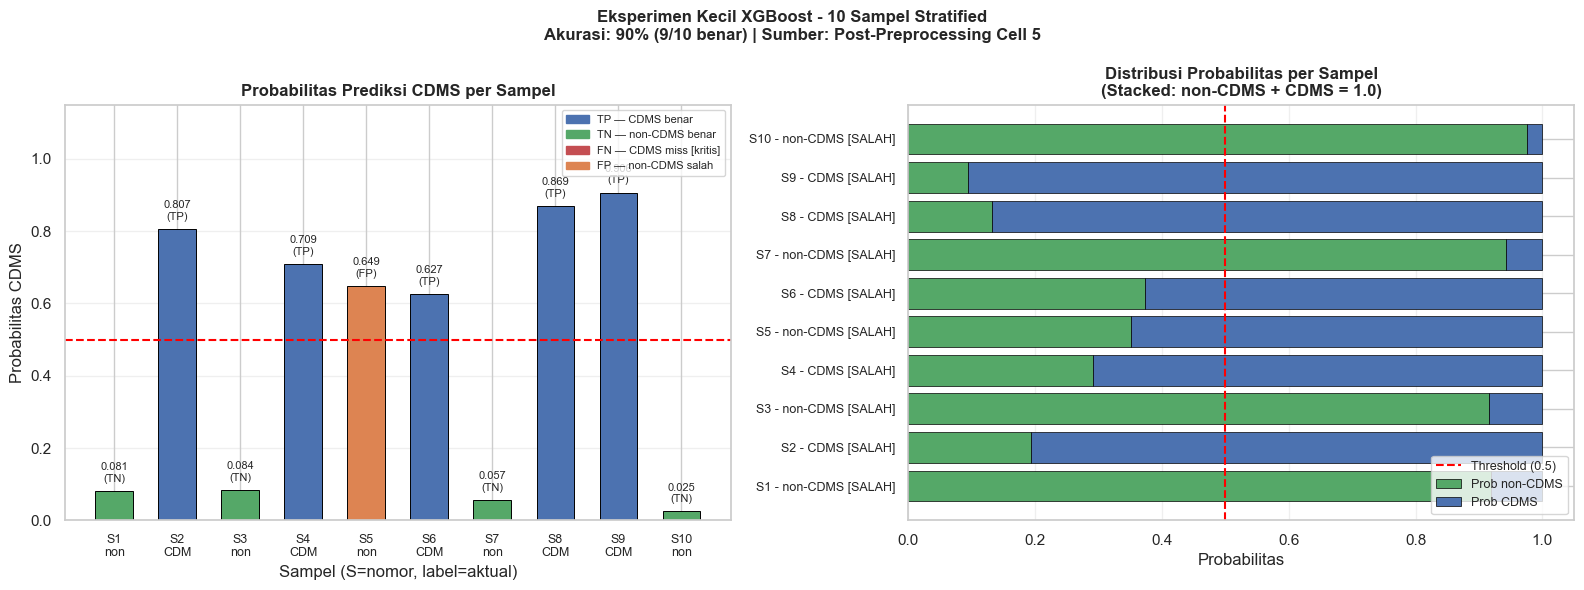

  Tersimpan: Output_Tabular/eksperimen_kecil_xgboost_10sampel.png

  BAGIAN 5 — ANALISIS CONFIDENCE MODEL

  Kategori confidence prediksi:
  No    Label Aktual     Prediksi       Prob CDMS    Confidence      Status
  ------------------------------------------------------------------------
  1     non-CDMS         non-CDMS       0.0813       Sangat Tinggi   ✅ Benar
  2     CDMS             CDMS           0.8065       Sangat Tinggi   ✅ Benar
  3     non-CDMS         non-CDMS       0.0842       Sangat Tinggi   ✅ Benar
  4     CDMS             CDMS           0.7085       Tinggi          ✅ Benar
  5     non-CDMS         CDMS           0.6486       Sedang          ❌ Salah
  6     CDMS             CDMS           0.6267       Sedang          ✅ Benar
  7     non-CDMS         non-CDMS       0.0567       Sangat Tinggi   ✅ Benar
  8     CDMS             CDMS           0.8687       Sangat Tinggi   ✅ Benar
  9     CDMS             CDMS           0.9065       Sangat Tinggi   ✅ Benar
  10    non-CDMS 

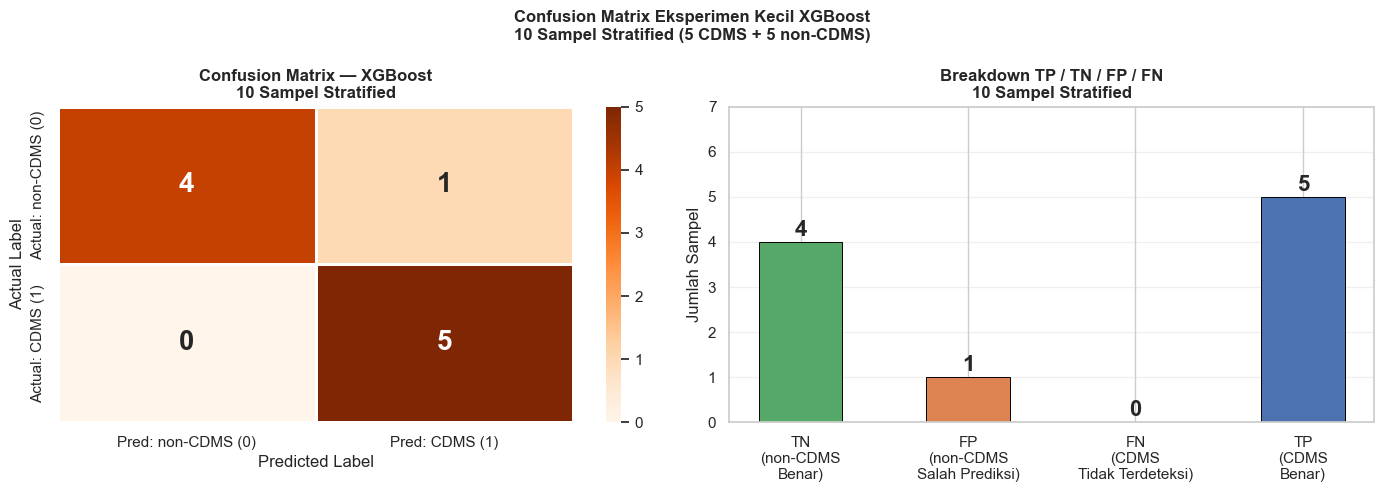

  Tersimpan: Output_Tabular/cm_eksperimen_kecil_xgboost.png

  Detail Confusion Matrix (10 Sampel):
  ┌──────────────────────────────────────────────────────┐
  │  TN — non-CDMS diprediksi non-CDMS : 4  sampel     │
  │  FP — non-CDMS diprediksi CDMS     : 1  sampel     │
  │  FN — CDMS diprediksi non-CDMS     : 0  sampel     │
  │  TP — CDMS diprediksi CDMS         : 5  sampel     │
  ├──────────────────────────────────────────────────────┤
  │  Akurasi  : 90% (9/10 prediksi benar)         │
  │  FP = 1   : non-CDMS salah prediksi sebagai CDMS    │
  │             pasien akan dapat pemeriksaan lanjutan  │
  │             konsekuensi klinis lebih rendah dari FN │
  │  FN = 0   : tidak ada CDMS yang terlewat            │
  │             model berhasil deteksi semua CDMS       │
  └──────────────────────────────────────────────────────┘


  BAGIAN 7 — RINGKASAN EKSPERIMEN KECIL

  Sumber data    : X, y hasil Cell 5 (post-preprocessing)
  Model          : XGBoost (dilatih pada Cell 10)
  

In [25]:
#  EKSPERIMEN KECIL — XGBOOST 10 SAMPEL STRATIFIED
#  Sumber  : X dan y hasil Cell 5 (post-preprocessing)
#  Metode  : 5 CDMS (kelas 1) + 5 non-CDMS (kelas 0)
#  Tujuan  : Demonstrasi prediksi XGBoost pada sampel kecil
#            representatif — terpisah dari train/test split
# ============================================================

print("=" * 65)
print("  EKSPERIMEN KECIL — XGBOOST 10 SAMPEL STRATIFIED")
print("=" * 65)

# ----------------------------------------------------------
# BAGIAN 1 — Pengambilan 10 Sampel Stratified
#            5 dari kelas 1 (CDMS) + 5 dari kelas 0 (non-CDMS)
#            random_state=42 untuk reproduksibilitas
# ----------------------------------------------------------
print("\n  BAGIAN 1 — PENGAMBILAN 10 SAMPEL STRATIFIED")
print("-" * 65)

# Pisahkan indeks per kelas dari X dan y hasil Cell 5
idx_cdms     = y[y == 1].index   # semua indeks kelas CDMS
idx_noncdms  = y[y == 0].index   # semua indeks kelas non-CDMS

# Ambil 5 sampel dari masing-masing kelas
sample_cdms    = pd.Series(idx_cdms).sample(
    5, random_state=42
).values
sample_noncdms = pd.Series(idx_noncdms).sample(
    5, random_state=42
).values

# Gabungkan dan acak urutan
idx_10 = np.concatenate([sample_cdms, sample_noncdms])
np.random.seed(42)
np.random.shuffle(idx_10)

# Buat subset X dan y untuk 10 sampel
X_10 = X.loc[idx_10].reset_index(drop=True)
y_10 = y.loc[idx_10].reset_index(drop=True)

print(f"\n  Total sampel diambil : {len(X_10)}")
print(f"  Kelas 1 (CDMS)       : {(y_10 == 1).sum()} sampel")
print(f"  Kelas 0 (non-CDMS)   : {(y_10 == 0).sum()} sampel")
print(f"  Indeks asli dataset  : {idx_10.tolist()}")

print(f"\n  Preview 10 Sampel (fitur utama):")
display(X_10[['Age', 'Gender', 'Schooling',
              'Periventricular_MRI', 'Oligoclonal_Bands',
              'Initial_Symptom']].assign(
    Label_Aktual=y_10.map({1:'CDMS', 0:'non-CDMS'})
))

# ----------------------------------------------------------
# BAGIAN 2 — Prediksi XGBoost pada 10 Sampel
#            Menggunakan xgb_model yang sudah dilatih
#            di Cell 10 (trained on X_train_scaled)
#
#            CATATAN PENTING:
#            xgb_model dilatih pada X_train_scaled (sudah scale)
#            X_10 belum discale — perlu transform dulu
#            menggunakan scaler yang sama dari Cell 8
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  BAGIAN 2 — PERSIAPAN & PREDIKSI")
print("=" * 65)

# Transform X_10 menggunakan scaler dari Cell 8
# WAJIB: pakai scaler yang sudah fit di Cell 8
#        jangan fit ulang — itu data leakage
X_10_scaled          = X_10.copy()
X_10_scaled[kolom_scale] = scaler.transform(X_10[kolom_scale])

print(f"\n  ✅ X_10 sudah di-transform menggunakan scaler Cell 8")
print(f"  Kolom yang di-scale : {kolom_scale}")

# Prediksi kelas dan probabilitas
y_pred_10  = xgb_model.predict(X_10_scaled)
y_proba_10 = xgb_model.predict_proba(X_10_scaled)

print(f"\n  Preview Lengkap X_10 Setelah Scaling (semua fitur + target):")

df_preview_lengkap = X_10_scaled.copy()

# Tampilkan nilai Age dan Schooling sebelum dan sesudah scale
# agar terlihat jelas mana yang berubah
df_preview_lengkap.insert(0, 'No_Sampel',
    [f'S{i+1}' for i in range(len(X_10_scaled))]
)
df_preview_lengkap['Label_Aktual'] = y_10.map(
    {1: 'CDMS', 0: 'non-CDMS'}
).values

# Highlight kolom yang discale
print(f"  Kolom yang mengalami scaling : {kolom_scale}")
print(f"  Kolom lain                   : tidak berubah\n")

display(df_preview_lengkap.set_index('No_Sampel').style
    .format(precision=4)
    .set_caption(
        "Preview Lengkap 10 Sampel — "
        "Input Aktual yang Masuk ke Model XGBoost"
    )
    .set_properties(
        subset=kolom_scale,
        **{'background-color': '#fff3cd'}  # highlight kuning kolom scale
    )
)

print(f"\n  ✅ Prediksi selesai untuk {len(X_10)} sampel")

# ----------------------------------------------------------
# BAGIAN 3 — Tabel Hasil Prediksi Lengkap
#            Tampilkan side-by-side:
#            label aktual vs prediksi vs probabilitas
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  BAGIAN 3 — TABEL HASIL PREDIKSI")
print("=" * 65)

df_hasil = pd.DataFrame({
    'No'               : range(1, 11),
    'Age'              : X_10['Age'].values,
    'Gender'           : X_10['Gender'].map(
                         {1:'Male', 2:'Female'}).values,
    'Periventricular'  : X_10['Periventricular_MRI'].values,
    'Oligoclonal'      : X_10['Oligoclonal_Bands'].values,
    'Label Aktual'     : y_10.map(
                         {1:'CDMS', 0:'non-CDMS'}).values,
    'Prediksi'         : pd.Series(y_pred_10).map(
                         {1:'CDMS', 0:'non-CDMS'}).values,
    'Prob non-CDMS'    : y_proba_10[:, 0].round(4),
    'Prob CDMS'        : y_proba_10[:, 1].round(4),
})

# Tambah kolom status prediksi
df_hasil['Status'] = df_hasil.apply(
    lambda r: '✅ Benar' if r['Label Aktual'] == r['Prediksi']
              else '❌ Salah', axis=1
)

display(df_hasil.set_index('No'))

# Hitung akurasi pada 10 sampel
n_benar   = (df_hasil['Status'] == '✅ Benar').sum()
n_salah   = (df_hasil['Status'] == '❌ Salah').sum()
akurasi   = n_benar / len(df_hasil)

print(f"\n  Prediksi Benar  : {n_benar} dari 10 sampel")
print(f"  Prediksi Salah  : {n_salah} dari 10 sampel")
print(f"  Akurasi (10)    : {akurasi:.2%}")

# ----------------------------------------------------------
# BAGIAN 4 — VISUALISASI PROBABILITAS PREDIKSI (DIPERBAIKI)
#            Semua simbol emoji diganti teks biasa
#            agar kompatibel dengan font Arial Windows
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  BAGIAN 4 — VISUALISASI PROBABILITAS PREDIKSI")
print("=" * 65)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Tentukan warna bar berdasarkan TP/TN/FP/FN ---
warna_bar = []
label_status = []   # teks pengganti emoji untuk plot

for aktual, pred in zip(
        df_hasil['Label Aktual'], df_hasil['Prediksi']):
    if aktual == pred == 'CDMS':
        warna_bar.append('#4C72B0')
        label_status.append('TP')
    elif aktual == pred == 'non-CDMS':
        warna_bar.append('#55A868')
        label_status.append('TN')
    elif aktual == 'CDMS' and pred == 'non-CDMS':
        warna_bar.append('#C44E52')
        label_status.append('FN')
    else:
        warna_bar.append('#DD8452')
        label_status.append('FP')

x_pos   = np.arange(len(df_hasil))
label_x = [
    f"S{i+1}\n{row['Label Aktual'][:3]}"
    for i, row in df_hasil.iterrows()
]

# --- Plot A: Bar probabilitas CDMS ---
bars = axes[0].bar(
    x_pos, df_hasil['Prob CDMS'],
    color=warna_bar, edgecolor='black',
    linewidth=0.7, width=0.6
)
axes[0].axhline(
    y=0.5, color='red', linestyle='--',
    linewidth=1.5, label='Threshold (0.5)'
)
axes[0].set_title(
    'Probabilitas Prediksi CDMS per Sampel',
    fontsize=12, fontweight='bold'
)
axes[0].set_xlabel('Sampel (S=nomor, label=aktual)')
axes[0].set_ylabel('Probabilitas CDMS')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(label_x, fontsize=9)
axes[0].set_ylim(0, 1.15)
axes[0].grid(True, alpha=0.3, axis='y')

# Anotasi nilai + status (teks biasa, tanpa emoji)
for bar, prob, status in zip(
        bars, df_hasil['Prob CDMS'], label_status):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f'{prob:.3f}\n({status})',
        ha='center', va='bottom', fontsize=8
    )

# Legenda warna — teks biasa
from matplotlib.patches import Patch
legend_el = [
    Patch(color='#4C72B0', label='TP — CDMS benar'),
    Patch(color='#55A868', label='TN — non-CDMS benar'),
    Patch(color='#C44E52', label='FN — CDMS miss [kritis]'),
    Patch(color='#DD8452', label='FP — non-CDMS salah'),
]
axes[0].legend(handles=legend_el,
               loc='upper right', fontsize=8)

# --- Plot B: Stacked bar probabilitas ---
axes[1].barh(
    x_pos, df_hasil['Prob non-CDMS'],
    color='#55A868', edgecolor='black',
    linewidth=0.5, label='Prob non-CDMS'
)
axes[1].barh(
    x_pos, df_hasil['Prob CDMS'],
    left=df_hasil['Prob non-CDMS'],
    color='#4C72B0', edgecolor='black',
    linewidth=0.5, label='Prob CDMS'
)
axes[1].axvline(
    x=0.5, color='red', linestyle='--',
    linewidth=1.5, label='Threshold (0.5)'
)
axes[1].set_title(
    'Distribusi Probabilitas per Sampel\n'
    '(Stacked: non-CDMS + CDMS = 1.0)',
    fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Probabilitas')
axes[1].set_yticks(x_pos)

# Label sumbu Y — ganti emoji dengan teks biasa
axes[1].set_yticklabels(
    [f"S{i+1} - {row['Label Aktual']} "
     f"[{'OK' if row['Status'] == 'Benar' else 'SALAH'}]"
     for i, row in df_hasil.iterrows()],
    fontsize=9
)
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(True, alpha=0.3, axis='x')

plt.suptitle(
    f'Eksperimen Kecil XGBoost - 10 Sampel Stratified\n'
    f'Akurasi: {akurasi:.0%} ({n_benar}/10 benar) | '
    f'Sumber: Post-Preprocessing Cell 5',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig(
    'Output_Tabular/eksperimen_kecil_xgboost_10sampel.png',
    dpi=300, bbox_inches='tight', facecolor='white'
)
plt.show()
print("  Tersimpan: Output_Tabular/eksperimen_kecil_xgboost_10sampel.png")

# ----------------------------------------------------------
# BAGIAN 5 — Analisis Confidence Model
#            Seberapa yakin model terhadap prediksinya
#            Threshold default 0.5 — prediksi di atas 0.5 → CDMS
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  BAGIAN 5 — ANALISIS CONFIDENCE MODEL")
print("=" * 65)

print(f"\n  Kategori confidence prediksi:")
print(f"  {'No':<5} {'Label Aktual':<16} {'Prediksi':<14} "
      f"{'Prob CDMS':<12} {'Confidence':<15} {'Status'}")
print(f"  {'-'*72}")

for _, row in df_hasil.iterrows():
    prob  = row['Prob CDMS']
    if prob >= 0.80 or prob <= 0.20:
        conf = 'Sangat Tinggi'
    elif prob >= 0.65 or prob <= 0.35:
        conf = 'Tinggi'
    elif prob >= 0.55 or prob <= 0.45:
        conf = 'Sedang'
    else:
        conf = 'Rendah (border)'

    print(f"  {row['No']:<5} {row['Label Aktual']:<16} "
          f"{row['Prediksi']:<14} {prob:<12.4f} "
          f"{conf:<15} {row['Status']}")

# ----------------------------------------------------------
# BAGIAN 6 — CONFUSION MATRIX EKSPERIMEN KECIL
#            Visualisasi TP, TN, FP, FN dari 10 sampel
#            Skala kecil tapi strukturnya identik dengan
#            confusion matrix Cell 12 untuk konsistensi
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  BAGIAN 6 — CLASSIFICATION REPORT & CONFUSION MATRIX (10 SAMPEL)")
print("=" * 65)

from sklearn.metrics import classification_report

print(f"\n  Classification Report — XGBoost 10 Sampel Stratified:")
print("-" * 65)
print(classification_report(
    y_10,
    y_pred_10,
    target_names=['0 — non-CDMS', '1 — CDMS'],
    digits=4
))

# Breakdown per kelas secara manual untuk kejelasan
report_dict = classification_report(
    y_10,
    y_pred_10,
    target_names=['non-CDMS', 'CDMS'],
    digits=4,
    output_dict=True
)

print(f"  Ringkasan per kelas:")
print(f"  {'':30} {'non-CDMS':>12} {'CDMS':>12}")
print(f"  {'-'*55}")

for metrik_cr in ['precision', 'recall', 'f1-score', 'support']:
    val_noncdms = report_dict['non-CDMS'][metrik_cr]
    val_cdms    = report_dict['CDMS'][metrik_cr]
    if metrik_cr == 'support':
        print(f"  {metrik_cr:<30} {int(val_noncdms):>12} "
              f"{int(val_cdms):>12}")
    else:
        print(f"  {metrik_cr:<30} {val_noncdms:>12.4f} "
              f"{val_cdms:>12.4f}")

print(f"\n  Catatan interpretasi:")
print(f"  → Precision CDMS  : dari semua prediksi CDMS,")
print(f"                       berapa yang benar-benar CDMS")
print(f"  → Recall CDMS     : dari semua pasien CDMS aktual,")
print(f"                       berapa yang berhasil terdeteksi")
print(f"  → Support         : jumlah sampel aktual per kelas")
print(f"                       (5 CDMS + 5 non-CDMS = 10 total)")
print(f"\n  PENTING: Classification report 10 sampel bersifat")
print(f"  demonstratif — tidak merepresentasikan performa")
print(f"  final model yang diukur pada test set 55 sampel")
print("=" * 65)

from sklearn.metrics import confusion_matrix

# Hitung confusion matrix dari 10 sampel
cm_10 = confusion_matrix(y_10, y_pred_10)
tn_10, fp_10, fn_10, tp_10_cm = cm_10.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot A: Heatmap Confusion Matrix ---
sns.heatmap(
    cm_10,
    annot=True,
    fmt='d',
    cmap='Oranges',
    linewidths=0.8,
    xticklabels=['Pred: non-CDMS (0)', 'Pred: CDMS (1)'],
    yticklabels=['Actual: non-CDMS (0)', 'Actual: CDMS (1)'],
    ax=axes[0],
    annot_kws={'size': 20, 'weight': 'bold'}
)
axes[0].set_title(
    'Confusion Matrix — XGBoost\n10 Sampel Stratified',
    fontsize=12, fontweight='bold'
)
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# --- Plot B: Breakdown TP/TN/FP/FN ---
kategori_cm = ['TN\n(non-CDMS\nBenar)',
                'FP\n(non-CDMS\nSalah Prediksi)',
                'FN\n(CDMS\nTidak Terdeteksi)',
                'TP\n(CDMS\nBenar)']
nilai_cm    = [tn_10, fp_10, fn_10, tp_10_cm]
warna_cm    = ['#55A868', '#DD8452', '#C44E52', '#4C72B0']

bars_cm = axes[1].bar(
    kategori_cm, nilai_cm,
    color=warna_cm,
    edgecolor='black',
    linewidth=0.7,
    width=0.5
)
axes[1].set_title(
    'Breakdown TP / TN / FP / FN\n10 Sampel Stratified',
    fontsize=12, fontweight='bold'
)
axes[1].set_ylabel('Jumlah Sampel')
axes[1].set_ylim(0, max(nilai_cm) * 1.4)
axes[1].grid(True, alpha=0.3, axis='y')

# Anotasi nilai di atas bar
for bar, val in zip(bars_cm, nilai_cm):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        str(val),
        ha='center', va='bottom',
        fontsize=16, fontweight='bold'
    )

plt.suptitle(
    'Confusion Matrix Eksperimen Kecil XGBoost\n'
    '10 Sampel Stratified (5 CDMS + 5 non-CDMS)',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig(
    'Output_Tabular/cm_eksperimen_kecil_xgboost.png',
    dpi=300, bbox_inches='tight', facecolor='white'
)
plt.show()
print("  Tersimpan: Output_Tabular/cm_eksperimen_kecil_xgboost.png")

print(f"""
  Detail Confusion Matrix (10 Sampel):
  ┌──────────────────────────────────────────────────────┐
  │  TN — non-CDMS diprediksi non-CDMS : {tn_10:<2} sampel     │
  │  FP — non-CDMS diprediksi CDMS     : {fp_10:<2} sampel     │
  │  FN — CDMS diprediksi non-CDMS     : {fn_10:<2} sampel     │
  │  TP — CDMS diprediksi CDMS         : {tp_10_cm:<2} sampel     │
  ├──────────────────────────────────────────────────────┤
  │  Akurasi  : {(tn_10+tp_10_cm)/10:.0%} ({tn_10+tp_10_cm}/10 prediksi benar)         │
  │  FP = 1   : non-CDMS salah prediksi sebagai CDMS    │
  │             pasien akan dapat pemeriksaan lanjutan  │
  │             konsekuensi klinis lebih rendah dari FN │
  │  FN = 0   : tidak ada CDMS yang terlewat            │
  │             model berhasil deteksi semua CDMS       │
  └──────────────────────────────────────────────────────┘
""")

# ----------------------------------------------------------
# BAGIAN 7 — Ringkasan Eksperimen Kecil
# ----------------------------------------------------------
print("\n" + "=" * 65)
print("  BAGIAN 7 — RINGKASAN EKSPERIMEN KECIL")
print("=" * 65)

tp_10 = ((df_hasil['Label Aktual']=='CDMS') &
          (df_hasil['Prediksi']=='CDMS')).sum()
tn_10 = ((df_hasil['Label Aktual']=='non-CDMS') &
          (df_hasil['Prediksi']=='non-CDMS')).sum()
fp_10 = ((df_hasil['Label Aktual']=='non-CDMS') &
          (df_hasil['Prediksi']=='CDMS')).sum()
fn_10 = ((df_hasil['Label Aktual']=='CDMS') &
          (df_hasil['Prediksi']=='non-CDMS')).sum()

print(f"""
  Sumber data    : X, y hasil Cell 5 (post-preprocessing)
  Model          : XGBoost (dilatih pada Cell 10)
  Total sampel   : 10 (5 CDMS + 5 non-CDMS stratified)
  random_state   : 42 (reproduksibel)

  Hasil Prediksi:
  ┌─────────────────────────────────────────┐
  │  TP (CDMS benar terdeteksi)   : {tp_10:<2} sampel │
  │  TN (non-CDMS benar)          : {tn_10:<2} sampel │
  │  FP (non-CDMS salah → CDMS)   : {fp_10:<2} sampel │
  │  FN (CDMS tidak terdeteksi)   : {fn_10:<2} sampel │
  ├─────────────────────────────────────────┤
  │  Akurasi pada 10 sampel       : {akurasi:.0%}      │
  └─────────────────────────────────────────┘

  Catatan metodologis:
  Akurasi 10 sampel TIDAK dapat dibandingkan langsung
  dengan hasil Cell 10 (test set 55 sampel) karena
  ukuran sampel berbeda. Eksperimen ini bersifat
  demonstratif — menunjukkan cara kerja model pada
  kasus individual, bukan ukuran performa final.
""")

print("=" * 65)
print("  Seluruh eksperimen kecil XGBoost selesai")
print("=" * 65)

In [28]:
# Ambil raw score untuk perhitungan manual sigmoid
raw_scores = xgb_model.predict(
    X_10_scaled, output_margin=True
)

# ✅ Ambil kolom index 1 saja (probabilitas kelas CDMS)
# y_proba_10 shape: (10, 2) → kolom 0=non-CDMS, kolom 1=CDMS
prob_cdms_10 = y_proba_10[:, 1]   # ← perbaikan di sini

print("Data untuk Perhitungan Manual di Kertas:")
print(f"{'No':<5} {'Aktual':<14} {'Raw Score':>12} "
      f"{'Prob CDMS':>12} {'Prediksi':>12}")
print("-" * 57)

for i, (score, prob, pred, aktual) in enumerate(zip(
        raw_scores,
        prob_cdms_10,      # ← pakai prob_cdms_10, bukan y_proba_10
        y_pred_10,
        y_10), 1):
    label_aktual = 'CDMS'     if aktual == 1 else 'non-CDMS'
    label_pred   = 'CDMS'     if pred   == 1 else 'non-CDMS'
    print(f"  S{i:<3} {label_aktual:<14} {score:>12.6f} "
          f"{prob:>12.6f} {label_pred:>12}")

Data untuk Perhitungan Manual di Kertas:
No    Aktual            Raw Score    Prob CDMS     Prediksi
---------------------------------------------------------
  S1   non-CDMS          -2.424927     0.081292     non-CDMS
  S2   CDMS               1.427275     0.806476         CDMS
  S3   non-CDMS          -2.387235     0.084151     non-CDMS
  S4   CDMS               0.888252     0.708529         CDMS
  S5   non-CDMS           0.612901     0.648602         CDMS
  S6   CDMS               0.517994     0.626678         CDMS
  S7   non-CDMS          -2.811287     0.056717     non-CDMS
  S8   CDMS               1.889490     0.868697         CDMS
  S9   CDMS               2.271607     0.906498         CDMS
  S10  non-CDMS          -3.674752     0.024729     non-CDMS
